# Experiment 3 — Regression Analysis using Linear and Regularized Models


### Aim
To build Linear Regression, Ridge, Lasso and Elastic Net models to predict the loan amount that will be sanctioned to an applicant, tune the regularization strength of each model, and compare how they perform and behave differently.

### Dataset
Loan Amount Prediction dataset (Kaggle): https://www.kaggle.com/datasets/boss0ayush/loan-sanction-amount-prediction-data. The target column is `Loan Sanction Amount (USD)`, a continuous number, which is why this is a **regression** problem, not a classification one.


## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import time

import warnings
warnings.filterwarnings("ignore")

plt.style.use("default")
sns.set_style("whitegrid")
# Global Plot Formatting (rules.md compliance)
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['legend.fontsize'] = 15


## 2. EDA Helper Functions


In [2]:
# Dataset Overview
def dataset_overview(df):
    print("=" * 80)
    print("DATASET OVERVIEW")
    print("=" * 80)

    print(f"\nRows                : {df.shape[0]}")
    print(f"Columns             : {df.shape[1]}")

    print("\nColumn Names")
    print("-" * 80)

    for col in df.columns:
        print(col)

    print("\nDataset Info")
    print("-" * 80)
    print(df.info())

    print("\nStatistical Summary (Numerical)")
    print("-" * 80)
    print(df.describe().T)

    print("\nStatistical Summary (Categorical)")
    print("-" * 80)

    temp_df = df.select_dtypes(include=["object", "category"])

    if temp_df.shape[1] > 0:
        print(temp_df.describe().T)
    else:
        print("No categorical columns found.")


# Column Analysis
def column_analysis(df):
    print("\n")
    print("=" * 80)
    print("COLUMN ANALYSIS")
    print("=" * 80)

    total_rows = len(df)

    for col in df.columns:
        print("\n" + "-" * 80)
        print(f"Column : {col}")
        print("-" * 80)

        dtype = df[col].dtype
        missing = df[col].isna().sum()
        unique = df[col].nunique(dropna=True)

        print(f"Data Type          : {dtype}")

        if unique <= 20:
            print(df[col].unique())
        else:
            print(df[col].unique()[:20])
            print(f"\nshowing first 20 of {unique} unique values")

        if unique >= 0.95 * total_rows:
            print("Possible Identifier Column")


# Missing Value Analysis
def missing_value_analysis(df):
    print("\n")
    print("=" * 80)
    print("MISSING VALUE ANALYSIS")
    print("=" * 80)

    missing = df.isnull().sum()
    missing_percent = (missing / len(df)) * 100

    missing_df = pd.DataFrame({
        "Missing Count": missing,
        "Missing Percentage": missing_percent
    })

    print(missing_df)

    #Bar Chart
    plt.figure(figsize=(12,5))
    missing_percent.plot(kind="bar")
    plt.ylabel("Missing Percentage")
    plt.title("Missing Values (%)")
    plt.xticks(rotation=90)
    plt.show()


# Duplicate values analysis
def duplicate_analysis(df):
    print("\n")
    print("=" * 80)
    print("DUPLICATE ANALYSIS")
    print("=" * 80)

    duplicates = df.duplicated().sum()
    duplicate_percent = (duplicates / len(df)) * 100

    print(f"Duplicate Rows       : {duplicates}")
    print(f"Duplicate Percentage : {duplicate_percent:.2f}%")

    plt.figure(figsize=(4,4))
    plt.pie(
        [len(df)-duplicates, duplicates],
        labels=["Unique Rows", "Duplicate Rows"],
        autopct="%1.1f%%"
    )

    plt.title("Duplicate Row Distribution")
    plt.show()
# Numerical and Categorical analysis
from scipy import stats

def numerical_analysis(df):
    print("\n")
    print("=" * 80)
    print("NUMERICAL FEATURE ANALYSIS")
    print("=" * 80)

    for col in df.columns:
        if pd.api.types.is_numeric_dtype(df[col]):
            temp = df[col].dropna()
        else:
            temp = pd.to_numeric(df[col], errors="coerce").dropna()
            if len(temp) < 0.9 * df[col].notna().sum():
                continue
        if temp.empty:
            continue

        print("\n" + "-" * 80)
        print(f"Column : {col}")
        print("-" * 80)

        print(f"Mean       : {temp.mean():.3f}")
        print(f"Median     : {temp.median():.3f}")
        print(f"Std Dev    : {temp.std():.3f}")
        print(f"Variance   : {temp.var():.3f}")
        print(f"Skewness   : {temp.skew():.3f}")
        print(f"Kurtosis   : {temp.kurtosis():.3f}")

        # Histogram
        plt.figure(figsize=(6,4))
        plt.hist(temp, bins=30)
        plt.title(f"Histogram : {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.show()

        # Boxplot
        plt.figure(figsize=(6,2))
        sns.boxplot(x=temp)
        plt.title(f"Boxplot : {col}")
        plt.show()

        # Outliers (IQR)
        q1 = temp.quantile(0.25)
        q3 = temp.quantile(0.75)

        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        outliers = ((temp < lower) | (temp > upper)).sum()

        print(f"Outliers Detected : {outliers}")

def categorical_analysis(df):
    print("\n")
    print("=" * 80)
    print("CATEGORICAL FEATURE ANALYSIS")
    print("=" * 80)

    total_rows = len(df.columns)

    for col in df.columns:
        if pd.api.types.is_numeric_dtype(df[col]):
            continue
        temp = pd.to_numeric(df[col], errors="coerce")
        if temp.notna().sum() >= 0.9 * df[col].notna().sum():
            continue
        unique = df[col].nunique(dropna=True)

        print("\n" + "-" * 80)
        print(f"Column : {col}")
        print("-" * 80)
        print(f"Unique Categories : {unique}")
        counts = df[col].value_counts(dropna=False)

        if unique < 0.80 * total_rows:
            if unique <= 20:
                print(counts)
            else:
                print(counts.head(20))
                print(f"\nShowing Top 20 categories out of {unique}")

            plt.figure(figsize=(8,4))
            counts.plot(kind="bar")
            plt.title(col)
            plt.ylabel("Count")
            plt.xticks(rotation=45)
            plt.show()

def correlation_analysis(df):
    print("\n")
    print("=" * 80)
    print("CORRELATION ANALYSIS")
    print("=" * 80)

    numeric_df = df.select_dtypes(include=np.number)

    if numeric_df.shape[1] < 2:
        print("Not enough numerical columns.")
        return []

    corr = numeric_df.corr()

    plt.figure(figsize=(10,8))
    sns.heatmap(
        corr,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Correlation Heatmap")
    plt.show()

    print("\nHighly Correlated Feature Pairs")

    high_corr = []
    cols = corr.columns
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            if abs(corr.iloc[i, j]) >= 0.8:
                print(f"{cols[i]}, {cols[j]} = {corr.iloc[i, j]}")
                high_corr.append((cols[i], cols[j], corr.iloc[i, j]))
    return high_corr


def target_analysis(df, task, target):
    print("\n")
    print("=" * 80)
    print("TARGET ANALYSIS")
    print("=" * 80)

    if target is None:
        print("No target provided as parameter!")
        return

    if task.lower() == "classification":
        print(df[target].value_counts())
        plt.figure(figsize=(6,4))
        df[target].value_counts().plot(kind="bar")
        plt.title("Class Distribution")
        plt.show()
    elif task.lower() == "regression":
        print(df[target].describe())
        plt.figure(figsize=(6,4))
        plt.hist(df[target].dropna(), bins=30)
        plt.title("Target Distribution")
        plt.show()


def eda_summary(df, high_corr):
    print("\n")
    print("=" * 80)
    print("FINAL EDA SUMMARY")
    print("=" * 80)

    print(f"Rows                     : {df.shape[0]}")
    print(f"Columns                  : {df.shape[1]}")
    print(f"Numerical Columns        : {len(df.select_dtypes(include=np.number).columns)}")
    print(f"Categorical Columns      : {len(df.select_dtypes(exclude=np.number).columns)}")
    print(f"Duplicate Rows           : {df.duplicated().sum()}")
    print(f"Columns with Missing     : {(df.isnull().sum() > 0).sum()}")
    print(f"Highly Correlated Pairs  : {len(high_corr)}")
    print("\nEDA Completed Successfully.")


# Function to generate 12 EDA subplots on a single consolidated figure (rules.md Section 2 & 4.1)
def plot_eda_12_subplots(df, task="regression", target=None, filename="exp3_eda_12_subplots.eps"):
    fig, axes = plt.subplots(4, 3, figsize=(18, 20))
    axes = axes.flatten()
    
    # 1. Target Distribution
    if target and target in df.columns:
        axes[0].hist(df[target].dropna(), bins=30, color='skyblue', edgecolor='black')
        axes[0].set_title(f"1. Target Distribution ({target[:15]})")
        axes[0].set_xlabel(target[:15])
        axes[0].set_ylabel("Frequency")
    else:
        axes[0].text(0.5, 0.5, "No Target Specified", ha='center', va='center')
        axes[0].set_title("1. Target Distribution")
    
    # 2. Missing Values
    missing = df.isnull().sum()
    missing_top10 = missing[missing > 0].head(10) if (missing > 0).any() else missing.head(10)
    axes[1].bar(range(len(missing_top10)), missing_top10.values, color='coral')
    axes[1].set_xticks(range(len(missing_top10)))
    axes[1].set_xticklabels(missing_top10.index, rotation=45, ha='right')
    axes[1].set_title("2. Missing Value Count")
    axes[1].set_ylabel("Count")
    
    # 3. Duplicate Rows
    duplicates = df.duplicated().sum()
    uniques = len(df) - duplicates
    axes[2].pie([uniques, duplicates], labels=['Unique', 'Duplicates'], autopct='%1.1f%%', colors=['lightgreen', 'orange'])
    axes[2].set_title("3. Duplicate Row Ratio")
    
    # Select numeric columns excluding target
    num_cols = [c for c in df.select_dtypes(include=np.number).columns if c != target]
    
    # 4. Correlation Heatmap of top 6 features
    if len(num_cols) >= 2:
        top_num = num_cols[:6]
        corr = df[top_num].corr()
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[3], cbar=False)
        axes[3].set_title("4. Correlation Heatmap")
    else:
        axes[3].text(0.5, 0.5, "N/A", ha='center', va='center')
        axes[3].set_title("4. Correlation Heatmap")
    
    # 5-12. Feature Plots / Target Scatter Plots
    for i in range(8):
        ax_idx = i + 4
        if i < len(num_cols):
            col_name = num_cols[i]
            if target and target in df.columns:
                axes[ax_idx].scatter(df[col_name], df[target], alpha=0.4, color='darkblue', s=10)
                axes[ax_idx].set_title(f"{ax_idx+1}. {col_name[:12]} vs Target")
                axes[ax_idx].set_xlabel(col_name[:12])
                axes[ax_idx].set_ylabel(target[:10])
            else:
                axes[ax_idx].hist(df[col_name].dropna(), bins=20, color='teal', alpha=0.7)
                axes[ax_idx].set_title(f"{ax_idx+1}. Dist: {col_name[:15]}")
                axes[ax_idx].set_xlabel(col_name[:15])
                axes[ax_idx].set_ylabel("Freq")
        else:
            axes[ax_idx].text(0.5, 0.5, "N/A", ha='center', va='center')
            axes[ax_idx].set_title(f"{ax_idx+1}. Feature Plot")
            
    plt.tight_layout()
    plt.savefig(filename, format='eps', dpi=600, bbox_inches='tight')
    plt.show()
    print(f"Consolidated EDA 12-subplot figure saved as '{filename}' at 600 DPI.")


In [3]:
def tabular_eda(df, task, target=None):
    dataset_overview(df)
    column_analysis(df)
    missing_value_analysis(df)
    duplicate_analysis(df)
    numerical_analysis(df)
    categorical_analysis(df)
    high_corr = correlation_analysis(df)
    target_analysis(df, task, target)
    eda_summary(df, high_corr)
    # Generate and export 12-subplot EDA figure per rules.md
    plot_eda_12_subplots(df, task, target, filename='exp3_eda_12_subplots.eps')


## 3. Load Dataset

In [4]:
train = pd.read_csv("train.csv")
print(train.head().T)

                                            0                  1  \
Customer ID                           C-36995            C-33999   
Name                         Frederica Shealy  America Calderone   
Gender                                      F                  M   
Age                                        56                 32   
Income (USD)                          1933.05            4952.91   
Income Stability                          Low                Low   
Profession                            Working            Working   
Type of Employment                Sales staff                NaN   
Location                           Semi-Urban         Semi-Urban   
Loan Amount Request (USD)            72809.58           46837.47   
Current Loan Expenses (USD)            241.08             495.81   
Expense Type 1                              N                  N   
Expense Type 2                              N                  Y   
Dependents                                3.0   

In [5]:
test = pd.read_csv("test.csv")
print(test.head().T)

                                                0              1  \
Customer ID                               C-26247        C-35067   
Name                             Tandra Olszewski  Jeannette Cha   
Gender                                          F              F   
Age                                            47             57   
Income (USD)                              3472.69        1184.84   
Income Stability                              Low            Low   
Profession                   Commercial associate        Working   
Type of Employment                       Managers    Sales staff   
Location                               Semi-Urban          Rural   
Loan Amount Request (USD)               137088.98      104771.59   
Current Loan Expenses (USD)                396.72         463.76   
Expense Type 1                                  N              Y   
Expense Type 2                                  N              Y   
Dependents                                    2.

## 4. Exploratory Data Analysis (EDA)


### Train Data set


DATASET OVERVIEW

Rows                : 30000
Columns             : 24

Column Names
--------------------------------------------------------------------------------
Customer ID
Name
Gender
Age
Income (USD)
Income Stability
Profession
Type of Employment
Location
Loan Amount Request (USD)
Current Loan Expenses (USD)
Expense Type 1
Expense Type 2
Dependents
Credit Score
No. of Defaults
Has Active Credit Card
Property ID
Property Age
Property Type
Property Location
Co-Applicant
Property Price
Loan Sanction Amount (USD)

Dataset Info
--------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Customer ID                  30000 non-null  object 
 1   Name                         30000 non-null  object 
 2   Gender                       29947 no

                        count unique               top   freq
Customer ID             30000  30000           C-45413      1
Name                    30000  30000  Marilou Kwiecien      1
Gender                  29947      2                 M  15053
Income Stability        28317      2               Low  25751
Profession              30000      8           Working  16926
Type of Employment      22730     18          Laborers   5578
Location                30000      3        Semi-Urban  21563
Expense Type 1          30000      2                 N  19214
Expense Type 2          30000      2                 Y  20180
Has Active Credit Card  28434      3            Active   9771
Property Location       29644      3        Semi-Urban  10387


COLUMN ANALYSIS

--------------------------------------------------------------------------------
Column : Customer ID
--------------------------------------------------------------------------------
Data Type          : object
['C-36995' 'C-33999' 'C-37

Data Type          : float64
[ 54607.18  37469.98  36474.43  56040.54  74008.28  22382.57      0.
 168218.24  22842.29  16747.72  67256.42  34225.84  54336.71  75716.93
  67117.49  46597.14  73391.87  40467.06   -999.    84367.95]

showing first 20 of 21450 unique values


MISSING VALUE ANALYSIS
                             Missing Count  Missing Percentage
Customer ID                              0            0.000000
Name                                     0            0.000000
Gender                                  53            0.176667
Age                                      0            0.000000
Income (USD)                          4576           15.253333
Income Stability                      1683            5.610000
Profession                               0            0.000000
Type of Employment                    7270           24.233333
Location                                 0            0.000000
Loan Amount Request (USD)                0            0.000000
Current Lo

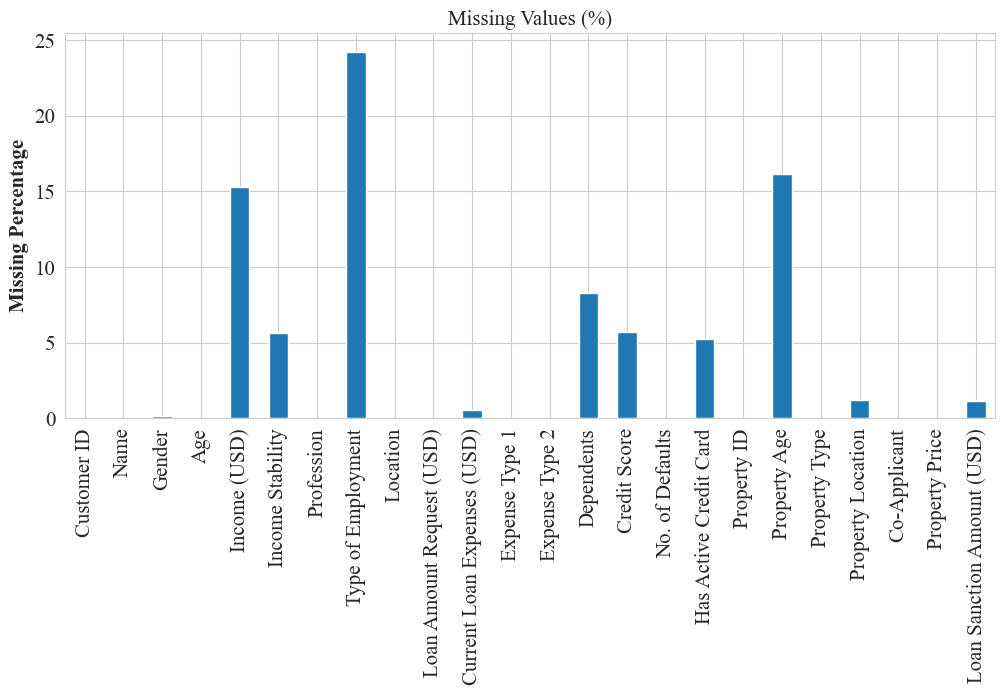



DUPLICATE ANALYSIS
Duplicate Rows       : 0
Duplicate Percentage : 0.00%


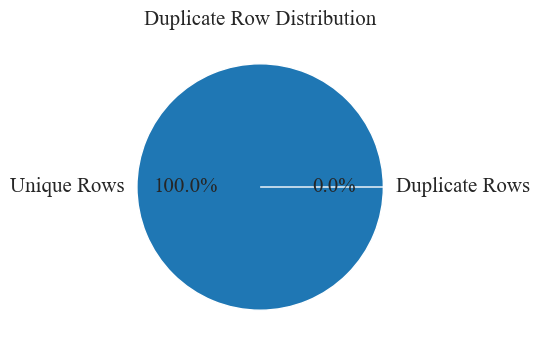



NUMERICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : Age
--------------------------------------------------------------------------------
Mean       : 40.092
Median     : 40.000
Std Dev    : 16.045
Variance   : 257.446
Skewness   : 0.046
Kurtosis   : -1.382


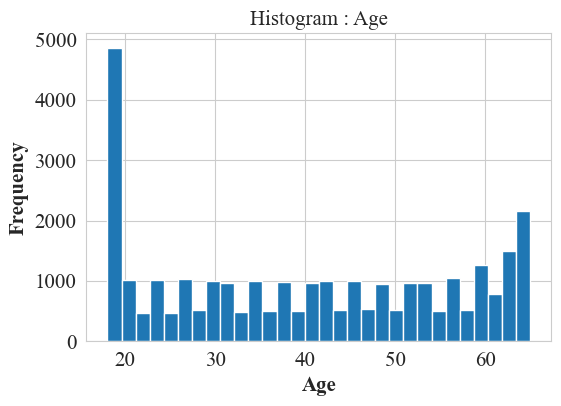

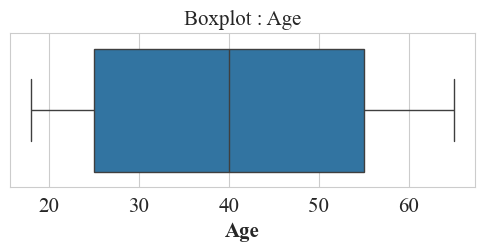

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Income (USD)
--------------------------------------------------------------------------------
Mean       : 2630.574
Median     : 2222.435
Std Dev    : 11262.724
Variance   : 126848948.069
Skewness   : 154.002
Kurtosis   : 24259.669


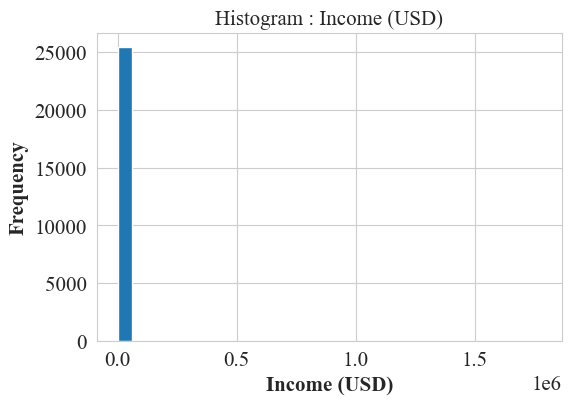

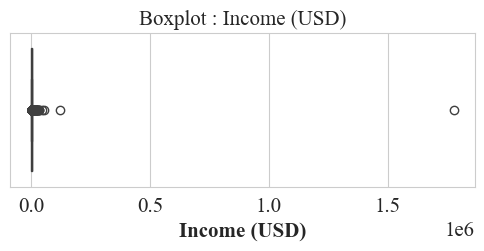

Outliers Detected : 1124

--------------------------------------------------------------------------------
Column : Loan Amount Request (USD)
--------------------------------------------------------------------------------
Mean       : 88826.334
Median     : 75128.075
Std Dev    : 59536.950
Variance   : 3544648368.253
Skewness   : 1.260
Kurtosis   : 2.103


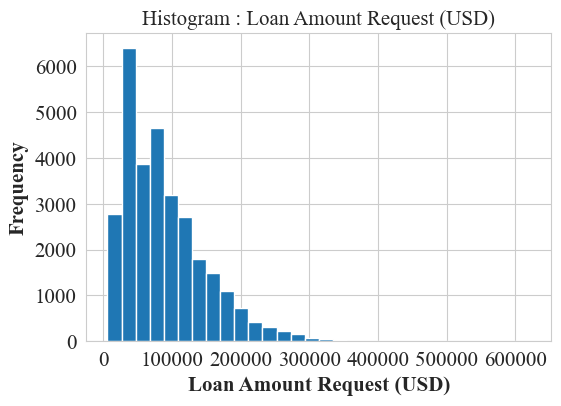

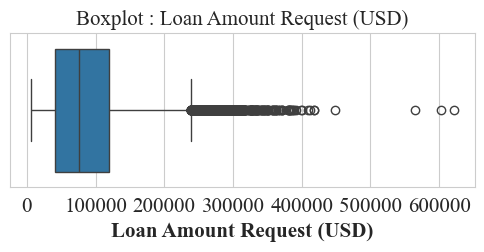

Outliers Detected : 752

--------------------------------------------------------------------------------
Column : Current Loan Expenses (USD)
--------------------------------------------------------------------------------
Mean       : 400.937
Median     : 375.205
Std Dev    : 242.545
Variance   : 58828.259
Skewness   : 0.044
Kurtosis   : 10.751


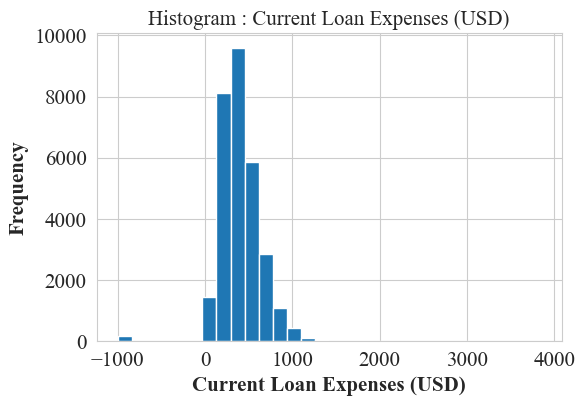

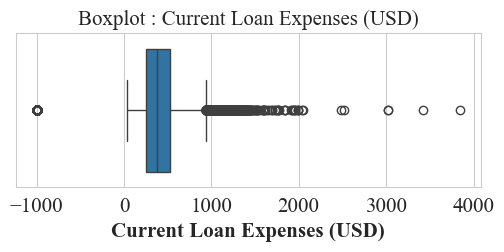

Outliers Detected : 857

--------------------------------------------------------------------------------
Column : Dependents
--------------------------------------------------------------------------------
Mean       : 2.253
Median     : 2.000
Std Dev    : 0.951
Variance   : 0.905
Skewness   : 0.805
Kurtosis   : 1.399


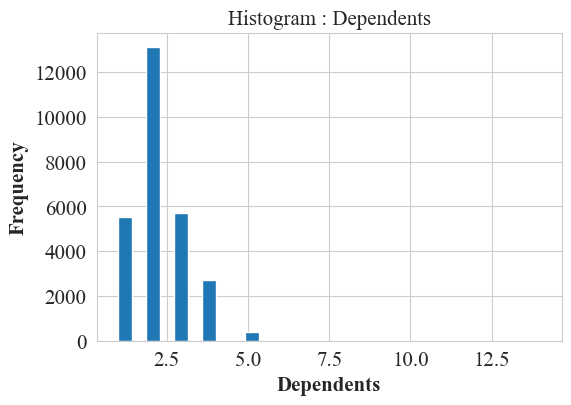

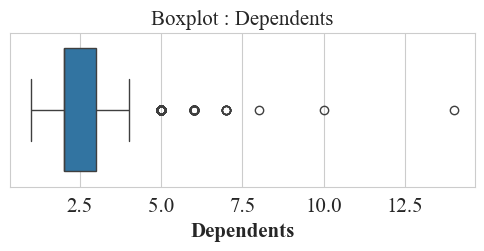

Outliers Detected : 432

--------------------------------------------------------------------------------
Column : Credit Score
--------------------------------------------------------------------------------
Mean       : 739.885
Median     : 739.820
Std Dev    : 72.164
Variance   : 5207.621
Skewness   : -0.020
Kurtosis   : -0.985


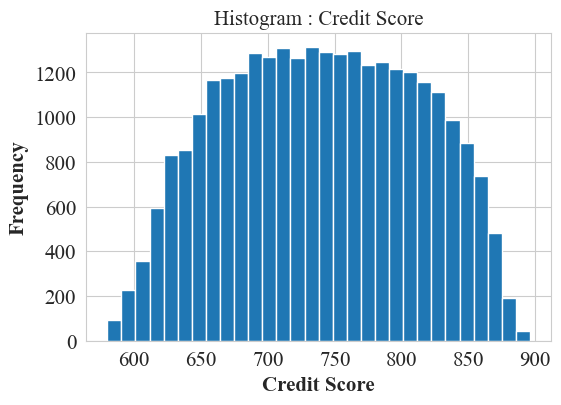

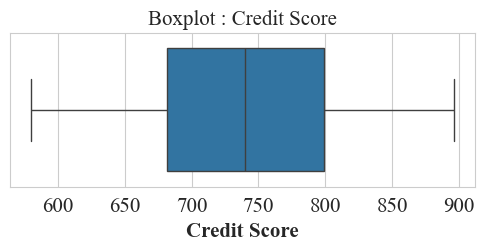

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : No. of Defaults
--------------------------------------------------------------------------------
Mean       : 0.194
Median     : 0.000
Std Dev    : 0.395
Variance   : 0.156
Skewness   : 1.548
Kurtosis   : 0.397


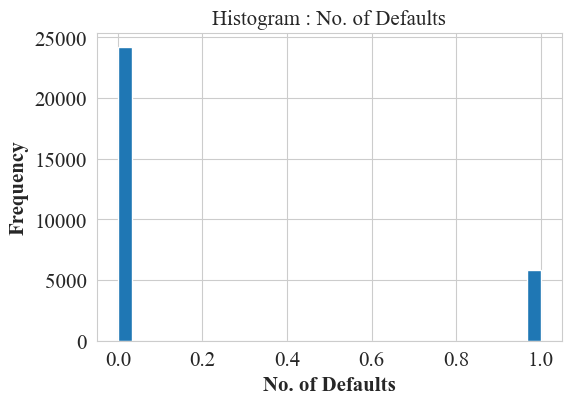

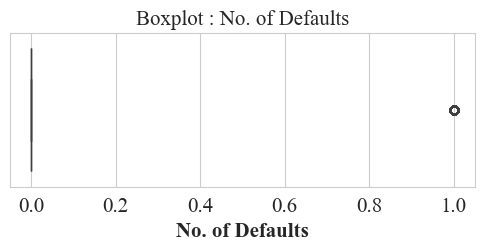

Outliers Detected : 5818

--------------------------------------------------------------------------------
Column : Property ID
--------------------------------------------------------------------------------
Mean       : 501.935
Median     : 504.000
Std Dev    : 288.158
Variance   : 83035.082
Skewness   : -0.011
Kurtosis   : -1.203


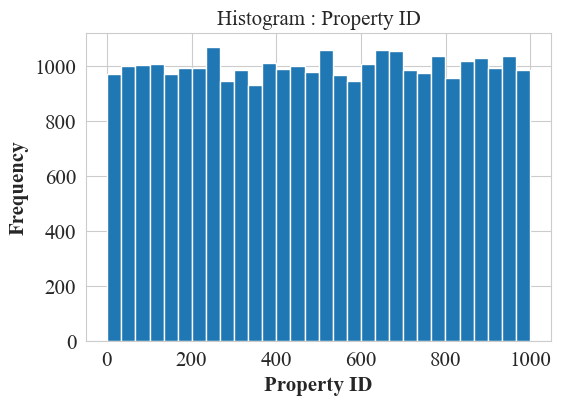

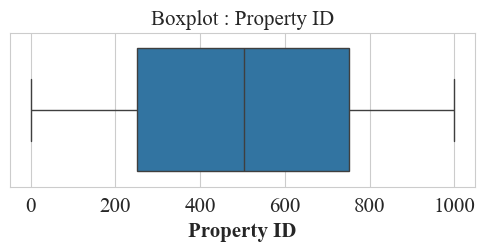

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Property Age
--------------------------------------------------------------------------------
Mean       : 2631.119
Median     : 2223.250
Std Dev    : 11322.677
Variance   : 128203014.453
Skewness   : 153.220
Kurtosis   : 24008.677


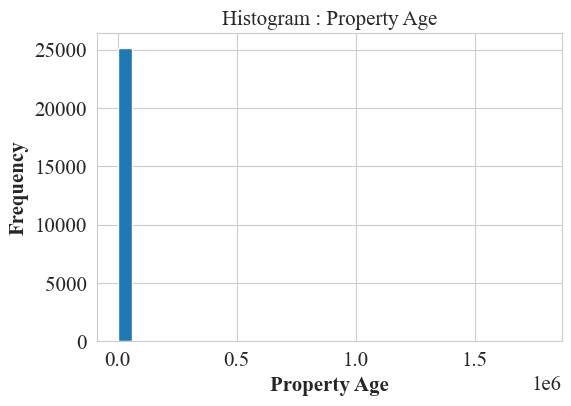

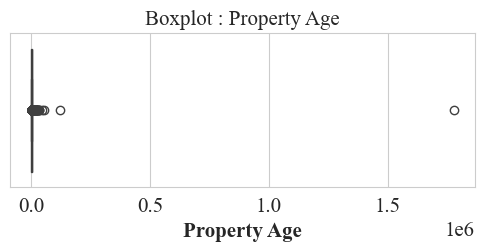

Outliers Detected : 1105

--------------------------------------------------------------------------------
Column : Property Type
--------------------------------------------------------------------------------
Mean       : 2.460
Median     : 2.000
Std Dev    : 1.119
Variance   : 1.251
Skewness   : 0.051
Kurtosis   : -1.359


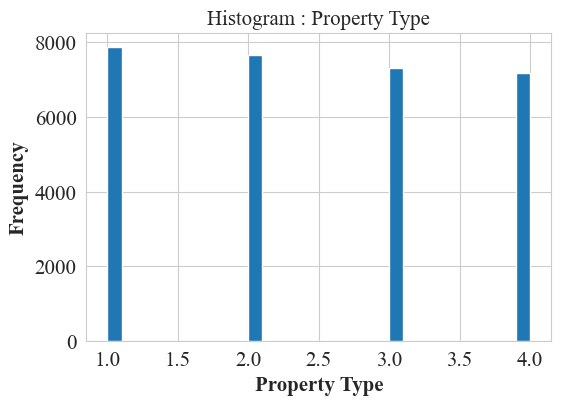

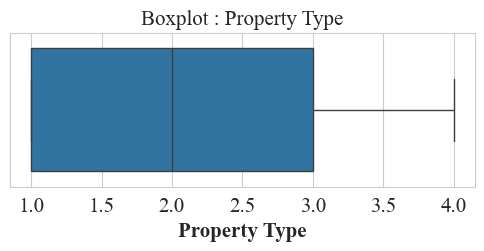

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Co-Applicant
--------------------------------------------------------------------------------
Mean       : -4.744
Median     : 1.000
Std Dev    : 74.615
Variance   : 5567.337
Skewness   : -13.251
Kurtosis   : 173.598


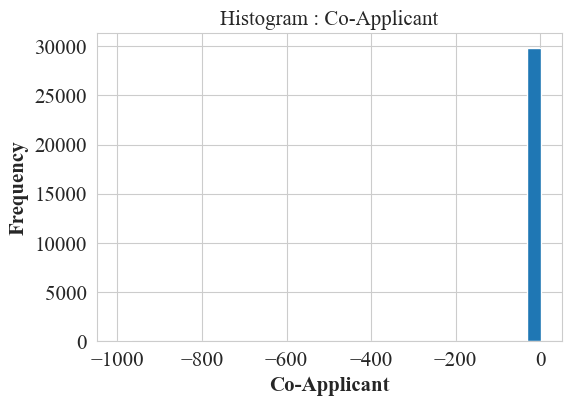

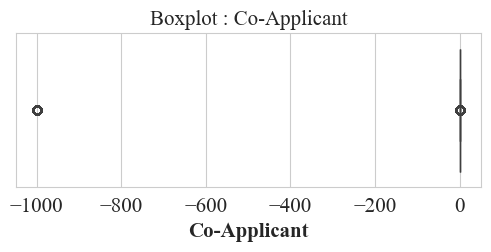

Outliers Detected : 4484

--------------------------------------------------------------------------------
Column : Property Price
--------------------------------------------------------------------------------
Mean       : 131759.680
Median     : 109993.610
Std Dev    : 93549.548
Variance   : 8751517950.503
Skewness   : 1.417
Kurtosis   : 3.149


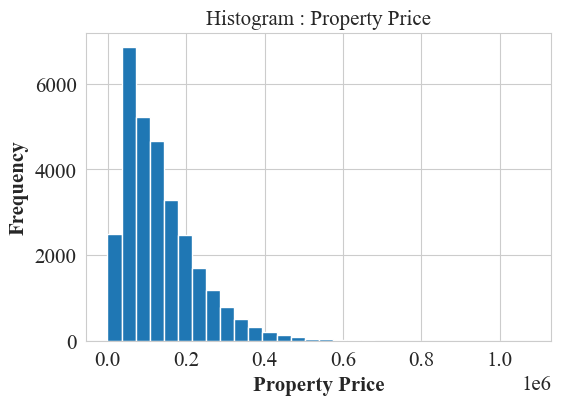

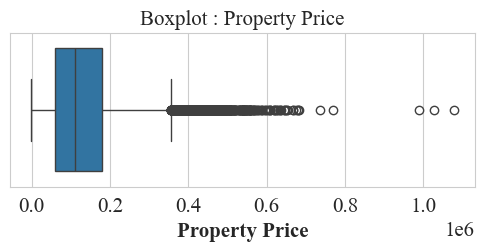

Outliers Detected : 863

--------------------------------------------------------------------------------
Column : Loan Sanction Amount (USD)
--------------------------------------------------------------------------------
Mean       : 47649.342
Median     : 35209.395
Std Dev    : 48221.147
Variance   : 2325278987.676
Skewness   : 1.230
Kurtosis   : 1.760


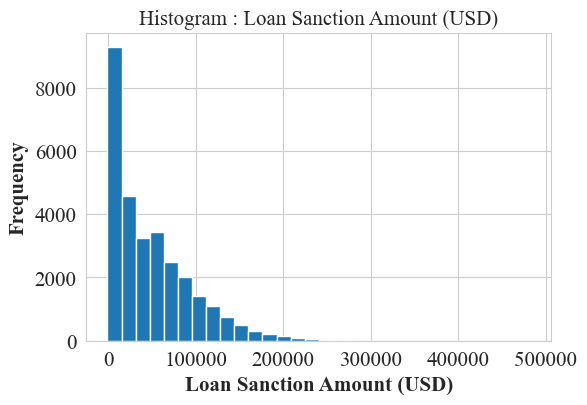

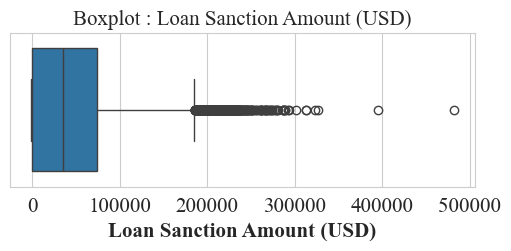

Outliers Detected : 438


CATEGORICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : Customer ID
--------------------------------------------------------------------------------
Unique Categories : 30000

--------------------------------------------------------------------------------
Column : Name
--------------------------------------------------------------------------------
Unique Categories : 30000

--------------------------------------------------------------------------------
Column : Gender
--------------------------------------------------------------------------------
Unique Categories : 2
Gender
M      15053
F      14894
NaN       53
Name: count, dtype: int64


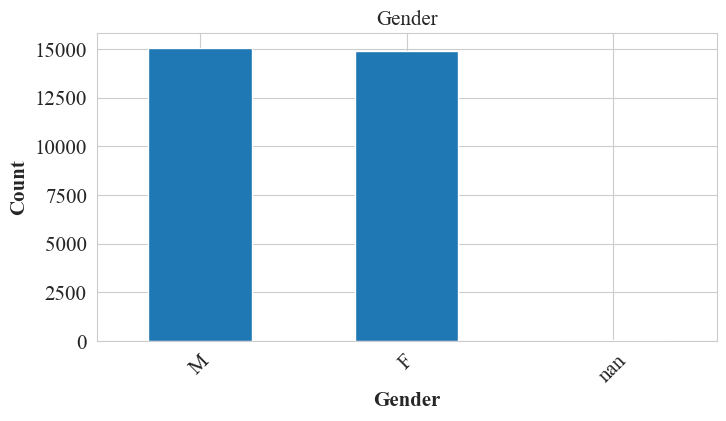


--------------------------------------------------------------------------------
Column : Income Stability
--------------------------------------------------------------------------------
Unique Categories : 2
Income Stability
Low     25751
High     2566
NaN      1683
Name: count, dtype: int64


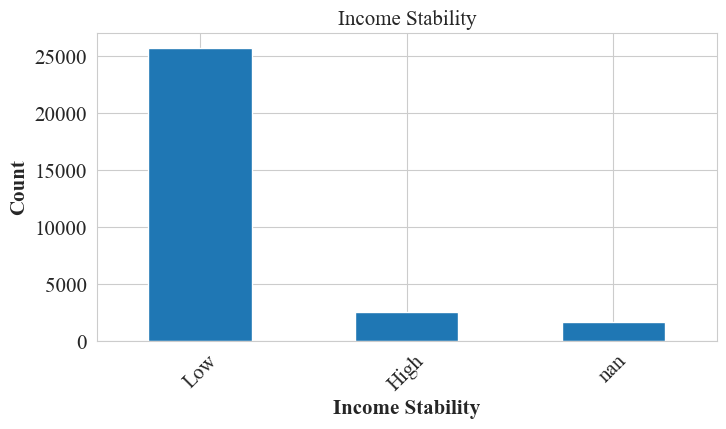


--------------------------------------------------------------------------------
Column : Profession
--------------------------------------------------------------------------------
Unique Categories : 8
Profession
Working                 16926
Commercial associate     7962
Pensioner                2740
State servant            2366
Unemployed                  2
Businessman                 2
Student                     1
Maternity leave             1
Name: count, dtype: int64


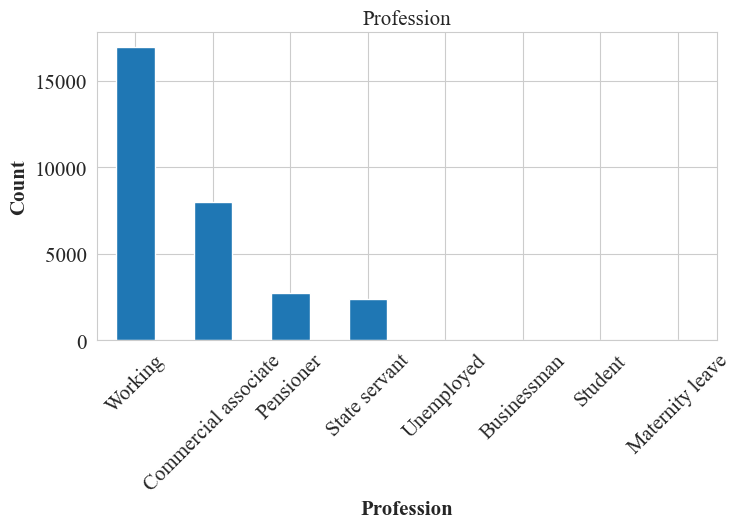


--------------------------------------------------------------------------------
Column : Type of Employment
--------------------------------------------------------------------------------
Unique Categories : 18
Type of Employment
NaN                      7270
Laborers                 5578
Sales staff              3736
Core staff               3230
Managers                 2495
Drivers                  1606
Accountants              1379
High skill tech staff    1307
Medicine staff            864
Security staff            579
Cooking staff             566
Private service staff     342
Cleaning staff            341
Low-skill Laborers        162
Secretaries               161
Waiters/barmen staff      149
Realty agents              86
IT staff                   77
HR staff                   72
Name: count, dtype: int64


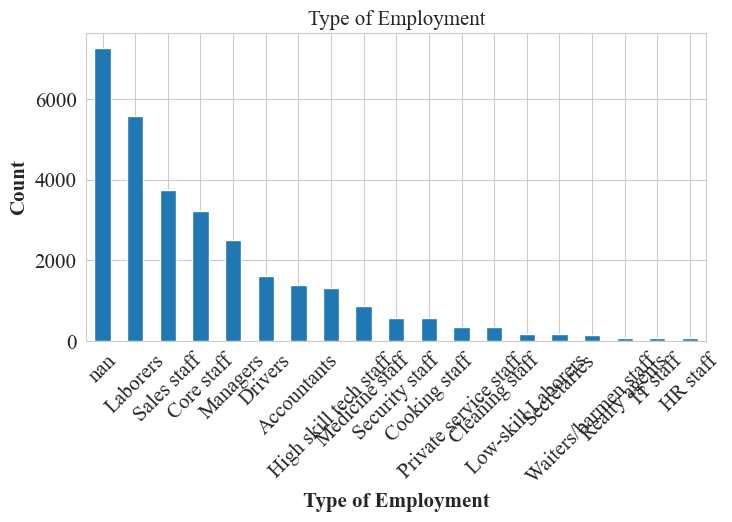


--------------------------------------------------------------------------------
Column : Location
--------------------------------------------------------------------------------
Unique Categories : 3
Location
Semi-Urban    21563
Rural          5338
Urban          3099
Name: count, dtype: int64


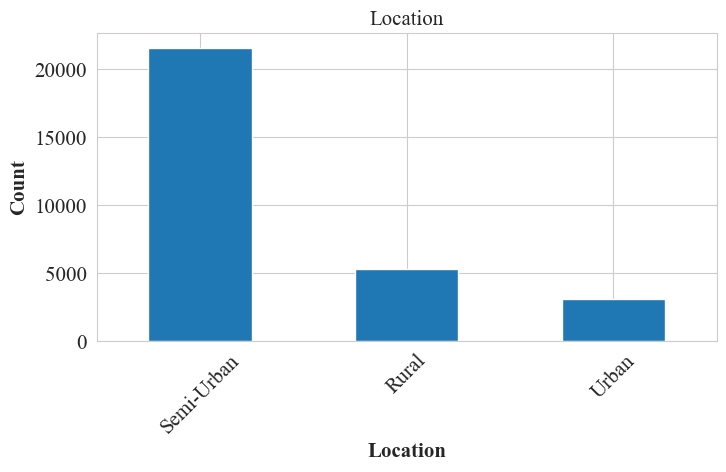


--------------------------------------------------------------------------------
Column : Expense Type 1
--------------------------------------------------------------------------------
Unique Categories : 2
Expense Type 1
N    19214
Y    10786
Name: count, dtype: int64


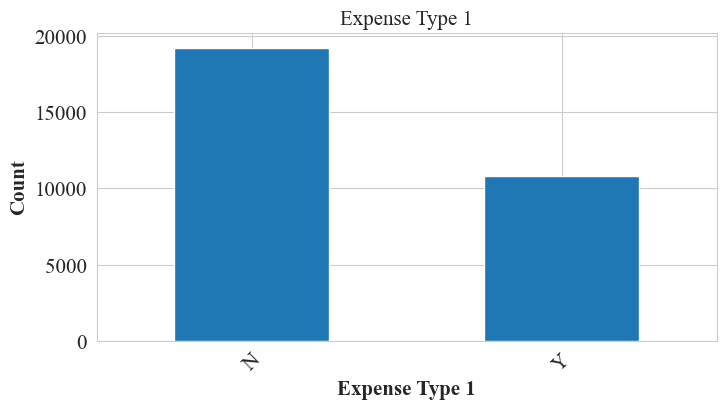


--------------------------------------------------------------------------------
Column : Expense Type 2
--------------------------------------------------------------------------------
Unique Categories : 2
Expense Type 2
Y    20180
N     9820
Name: count, dtype: int64


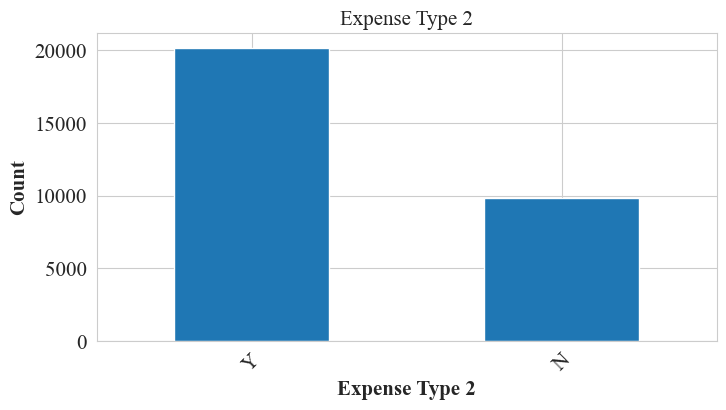


--------------------------------------------------------------------------------
Column : Has Active Credit Card
--------------------------------------------------------------------------------
Unique Categories : 3
Has Active Credit Card
Active         9771
Inactive       9466
Unpossessed    9197
NaN            1566
Name: count, dtype: int64


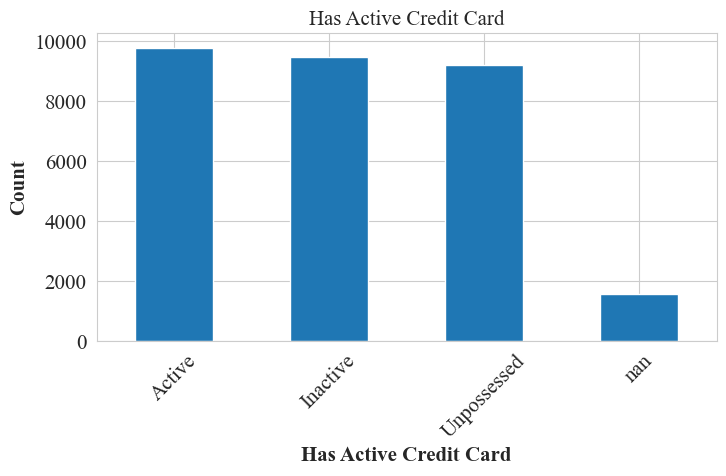


--------------------------------------------------------------------------------
Column : Property Location
--------------------------------------------------------------------------------
Unique Categories : 3
Property Location
Semi-Urban    10387
Rural         10041
Urban          9216
NaN             356
Name: count, dtype: int64


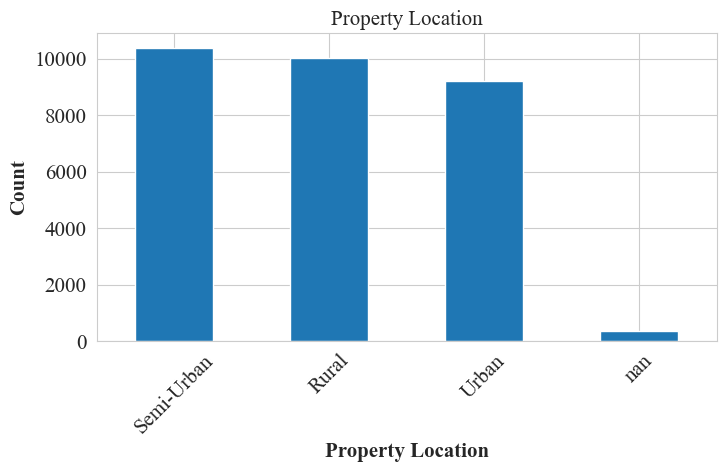



CORRELATION ANALYSIS


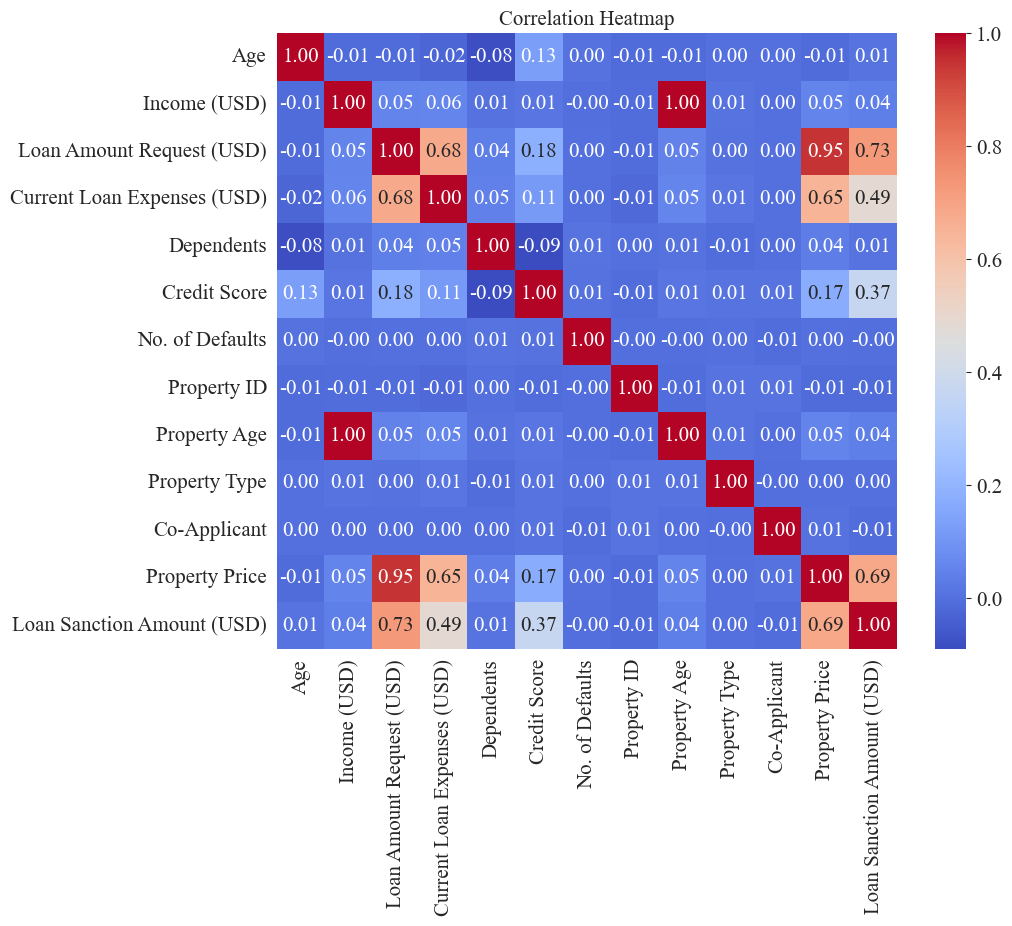


Highly Correlated Feature Pairs
Income (USD), Property Age = 1.0
Loan Amount Request (USD), Property Price = 0.9483497026229606


TARGET ANALYSIS
count     29660.000000
mean      47649.342208
std       48221.146686
min        -999.000000
25%           0.000000
50%       35209.395000
75%       74261.250000
max      481907.320000
Name: Loan Sanction Amount (USD), dtype: float64


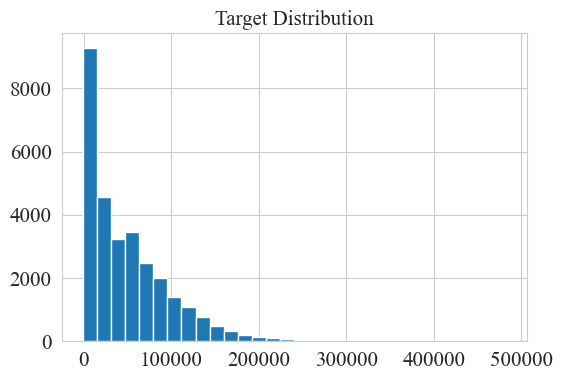



FINAL EDA SUMMARY
Rows                     : 30000
Columns                  : 24
Numerical Columns        : 13
Categorical Columns      : 11
Duplicate Rows           : 0
Columns with Missing     : 11
Highly Correlated Pairs  : 2

EDA Completed Successfully.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


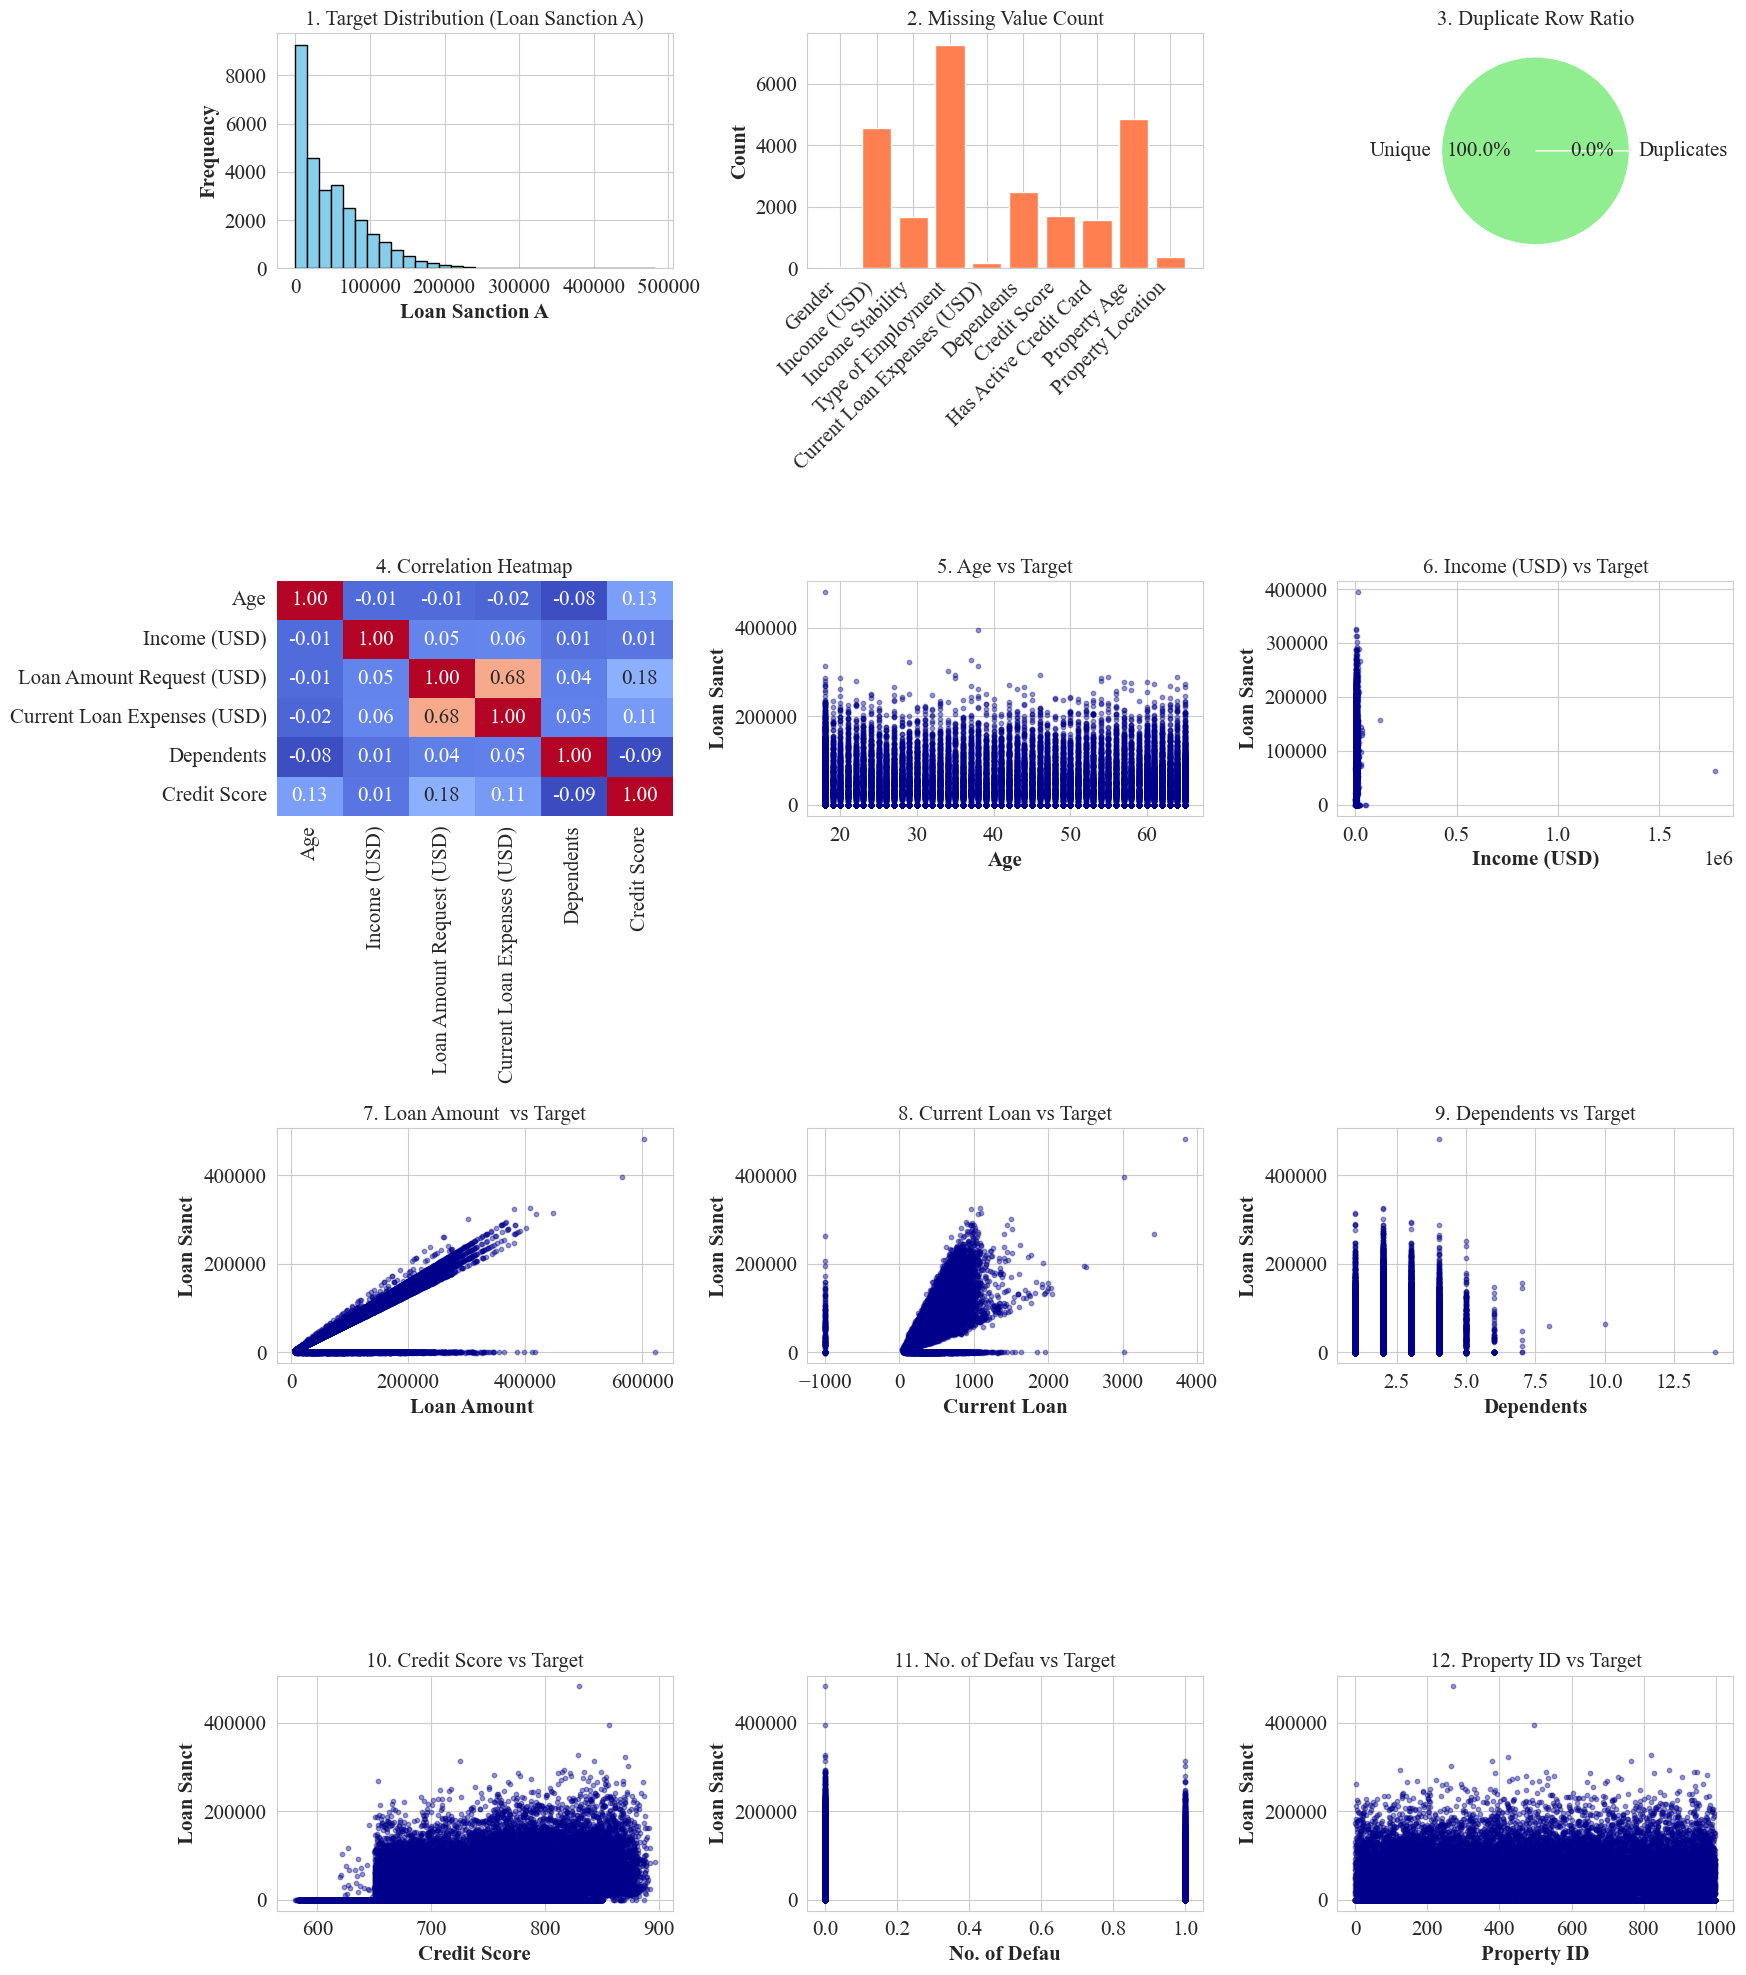

Consolidated EDA 12-subplot figure saved as 'exp3_eda_12_subplots.eps' at 600 DPI.


In [6]:
tabular_eda(train,"regression","Loan Sanction Amount (USD)")

### Test set

DATASET OVERVIEW

Rows                : 20000
Columns             : 23

Column Names
--------------------------------------------------------------------------------
Customer ID
Name
Gender
Age
Income (USD)
Income Stability
Profession
Type of Employment
Location
Loan Amount Request (USD)
Current Loan Expenses (USD)
Expense Type 1
Expense Type 2
Dependents
Credit Score
No. of Defaults
Has Active Credit Card
Property ID
Property Age
Property Type
Property Location
Co-Applicant
Property Price

Dataset Info
--------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Customer ID                  20000 non-null  object 
 1   Name                         20000 non-null  object 
 2   Gender                       19969 non-null  object 
 3   Age   

                        count unique            top   freq
Customer ID             20000  20000        C-10525      1
Name                    20000  20000  Florance Judd      1
Gender                  19969      2              F  10142
Income Stability        19187      2            Low  17501
Profession              20000      7        Working  11405
Type of Employment      15311     18       Laborers   3743
Location                20000      3     Semi-Urban  14463
Expense Type 1          20000      2              N  12816
Expense Type 2          20000      2              Y  13383
Has Active Credit Card  18924      3         Active   6418
Property Location       19840      3     Semi-Urban   6839
Co-Applicant            20000      3              1  17004
Property Price          20000  19824              ?    168


COLUMN ANALYSIS

--------------------------------------------------------------------------------
Column : Customer ID
-----------------------------------------------------

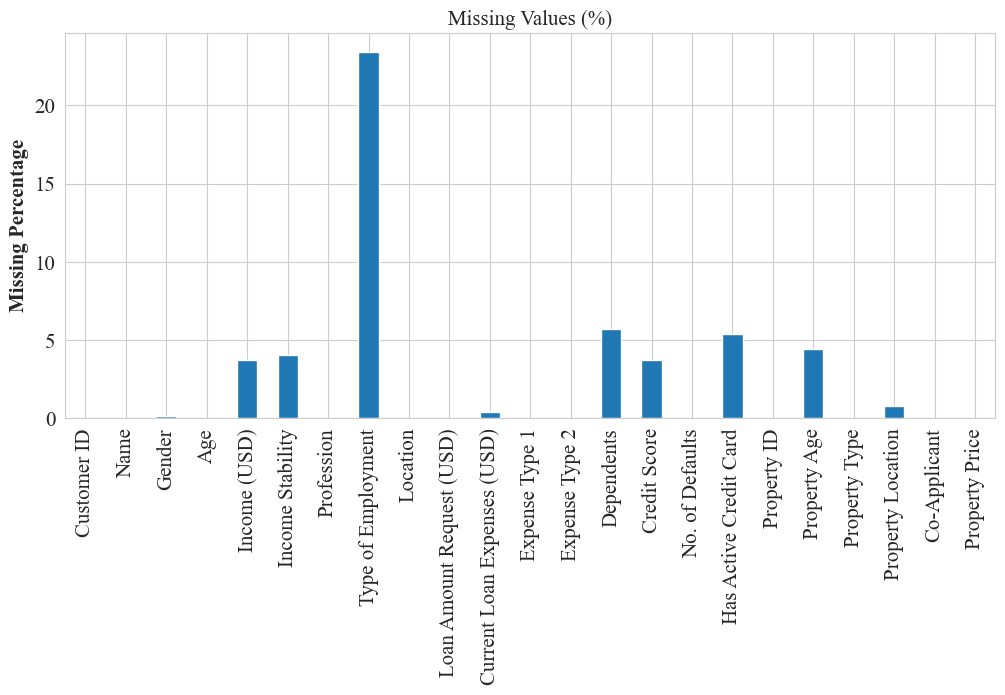



DUPLICATE ANALYSIS
Duplicate Rows       : 0
Duplicate Percentage : 0.00%


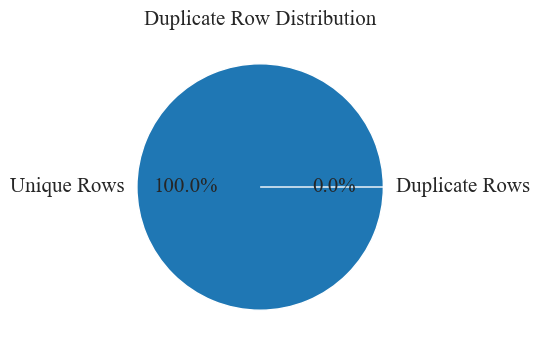



NUMERICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : Age
--------------------------------------------------------------------------------
Mean       : 39.941
Median     : 40.000
Std Dev    : 16.098
Variance   : 259.133
Skewness   : 0.055
Kurtosis   : -1.387


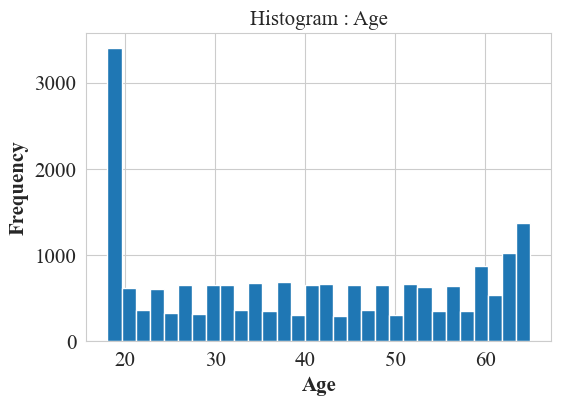

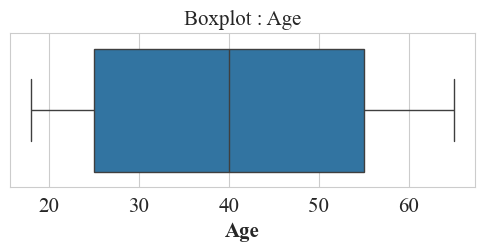

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Income (USD)
--------------------------------------------------------------------------------
Mean       : 2536.995
Median     : 2224.590
Std Dev    : 1415.909
Variance   : 2004797.738
Skewness   : 3.410
Kurtosis   : 31.052


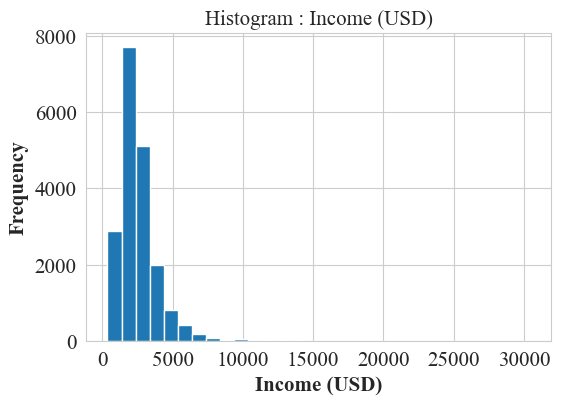

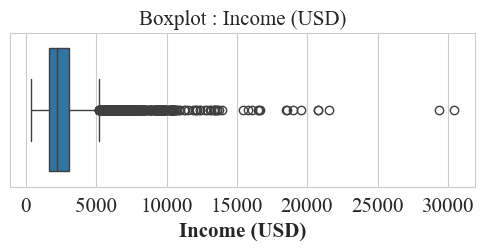

Outliers Detected : 831

--------------------------------------------------------------------------------
Column : Loan Amount Request (USD)
--------------------------------------------------------------------------------
Mean       : 88859.077
Median     : 74565.990
Std Dev    : 60007.334
Variance   : 3600880094.522
Skewness   : 1.278
Kurtosis   : 1.971


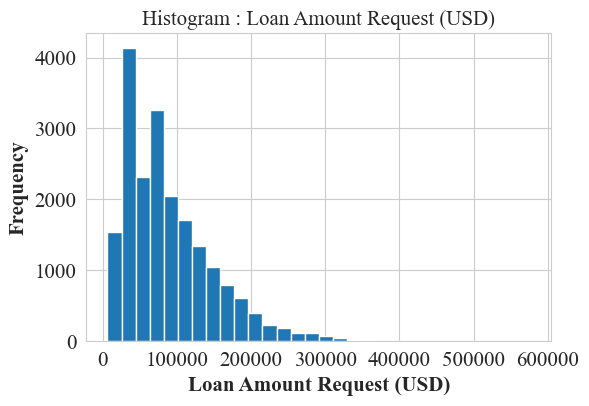

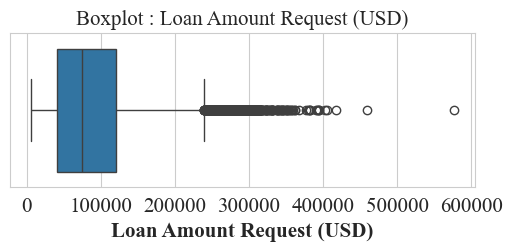

Outliers Detected : 511

--------------------------------------------------------------------------------
Column : Current Loan Expenses (USD)
--------------------------------------------------------------------------------
Mean       : 408.462
Median     : 374.000
Std Dev    : 215.847
Variance   : 46589.725
Skewness   : 1.378
Kurtosis   : 5.452


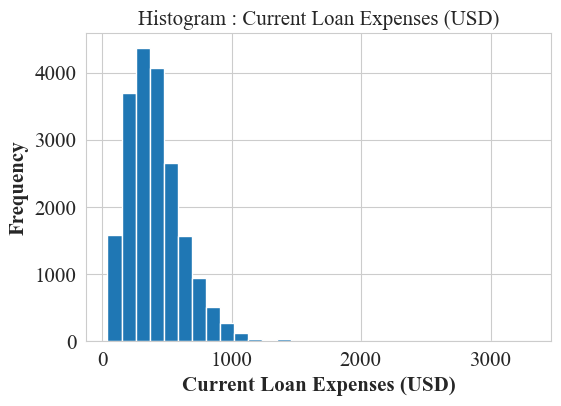

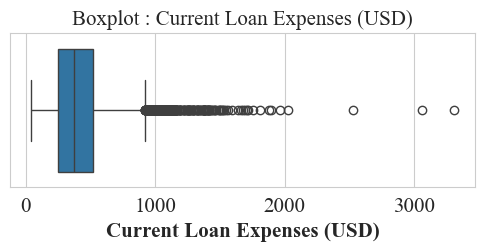

Outliers Detected : 486

--------------------------------------------------------------------------------
Column : Dependents
--------------------------------------------------------------------------------
Mean       : 2.251
Median     : 2.000
Std Dev    : 0.953
Variance   : 0.909
Skewness   : 0.807
Kurtosis   : 1.470


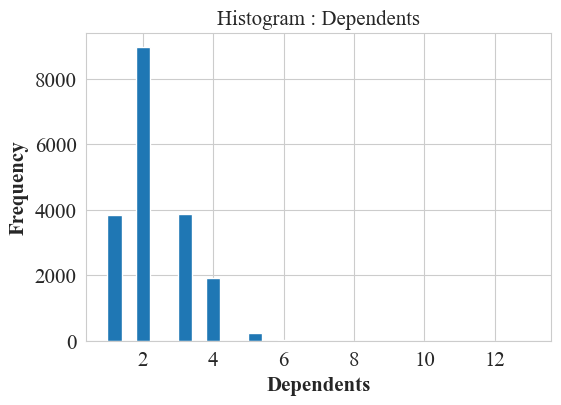

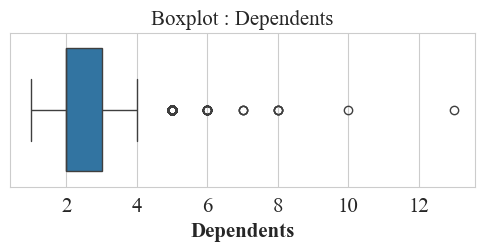

Outliers Detected : 275

--------------------------------------------------------------------------------
Column : Credit Score
--------------------------------------------------------------------------------
Mean       : 738.822
Median     : 739.300
Std Dev    : 72.407
Variance   : 5242.702
Skewness   : -0.012
Kurtosis   : -0.991


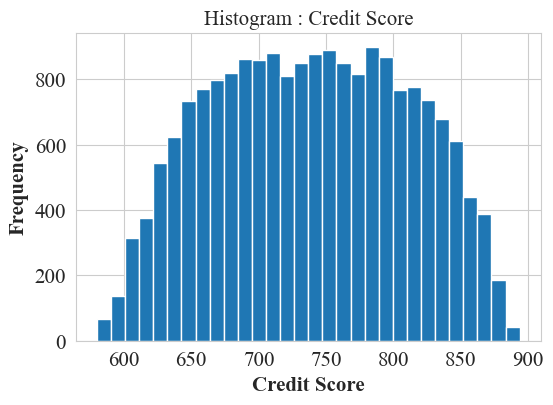

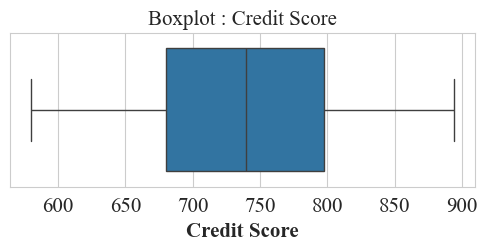

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : No. of Defaults
--------------------------------------------------------------------------------
Mean       : 0.190
Median     : 0.000
Std Dev    : 0.392
Variance   : 0.154
Skewness   : 1.585
Kurtosis   : 0.511


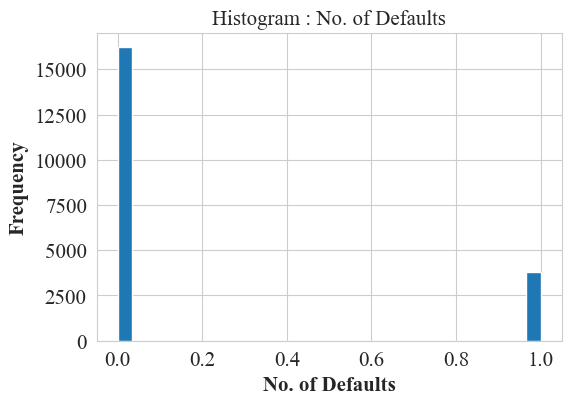

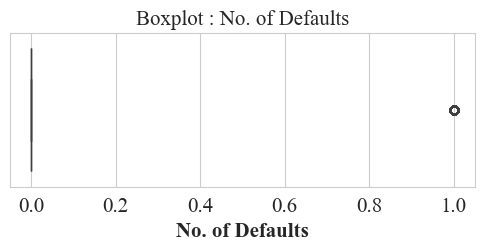

Outliers Detected : 3790

--------------------------------------------------------------------------------
Column : Property ID
--------------------------------------------------------------------------------
Mean       : 501.024
Median     : 501.000
Std Dev    : 287.538
Variance   : 82677.941
Skewness   : -0.007
Kurtosis   : -1.194


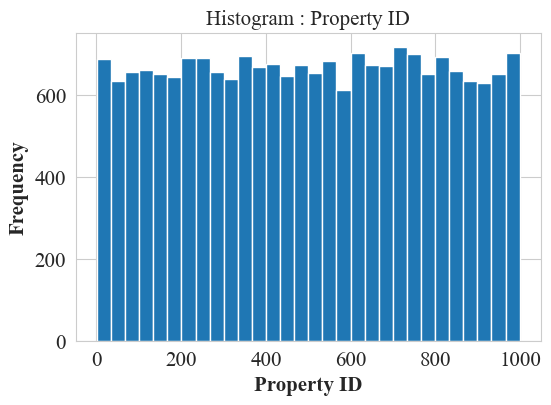

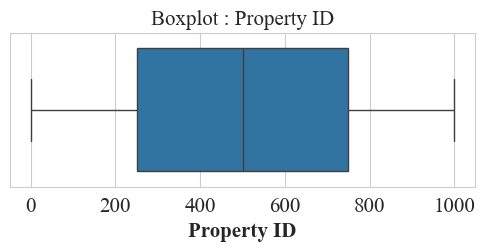

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Property Age
--------------------------------------------------------------------------------
Mean       : 2534.102
Median     : 2220.605
Std Dev    : 1408.509
Variance   : 1983898.322
Skewness   : 3.358
Kurtosis   : 30.483


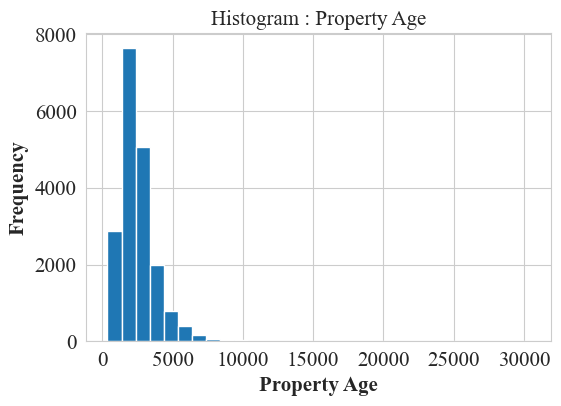

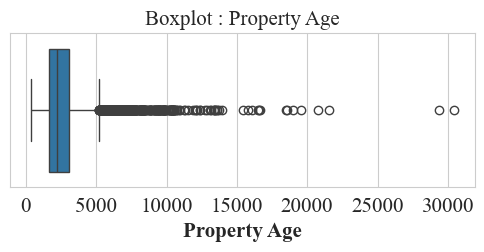

Outliers Detected : 822

--------------------------------------------------------------------------------
Column : Property Type
--------------------------------------------------------------------------------
Mean       : 2.472
Median     : 2.000
Std Dev    : 1.126
Variance   : 1.267
Skewness   : 0.034
Kurtosis   : -1.376


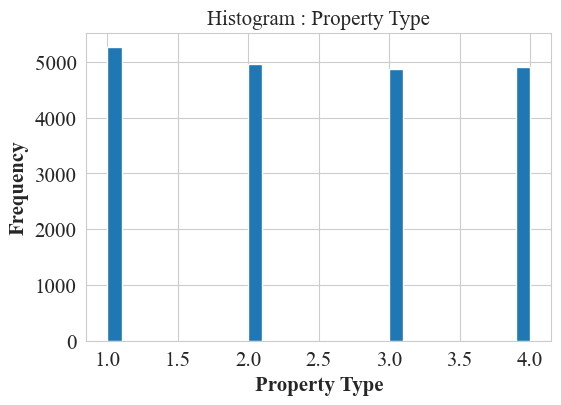

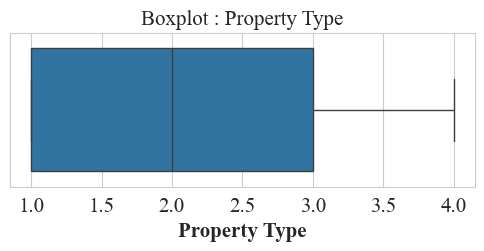

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Co-Applicant
--------------------------------------------------------------------------------
Mean       : 0.853
Median     : 1.000
Std Dev    : 0.354
Variance   : 0.125
Skewness   : -1.999
Kurtosis   : 1.998


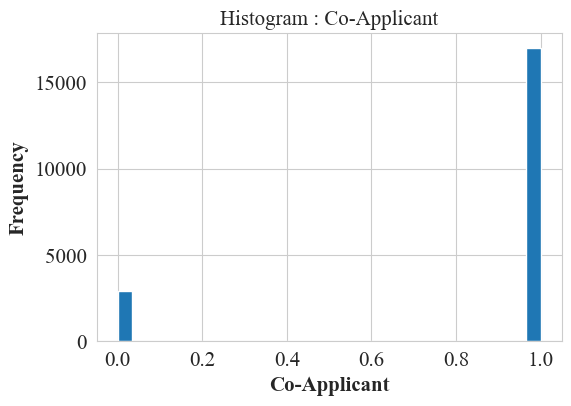

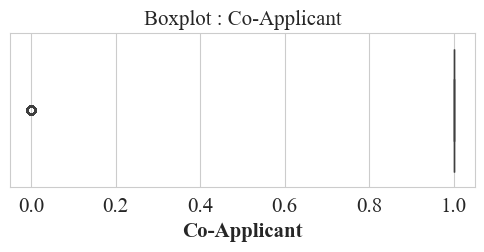

Outliers Detected : 2919

--------------------------------------------------------------------------------
Column : Property Price
--------------------------------------------------------------------------------
Mean       : 133466.497
Median     : 110871.825
Std Dev    : 93334.862
Variance   : 8711396458.667
Skewness   : 1.389
Kurtosis   : 2.496


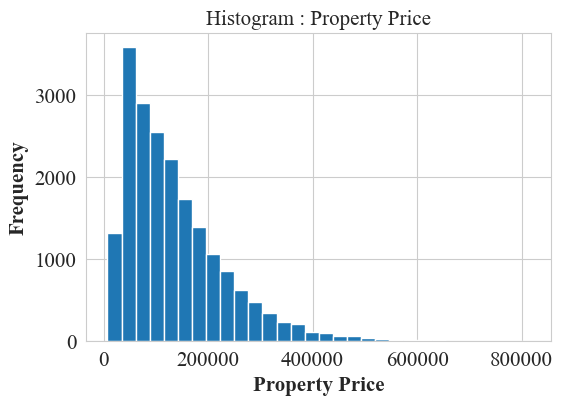

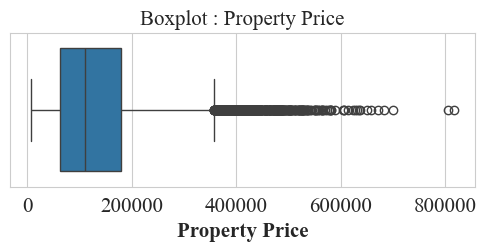

Outliers Detected : 606


CATEGORICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : Customer ID
--------------------------------------------------------------------------------
Unique Categories : 20000

--------------------------------------------------------------------------------
Column : Name
--------------------------------------------------------------------------------
Unique Categories : 20000

--------------------------------------------------------------------------------
Column : Gender
--------------------------------------------------------------------------------
Unique Categories : 2
Gender
F      10142
M       9827
NaN       31
Name: count, dtype: int64


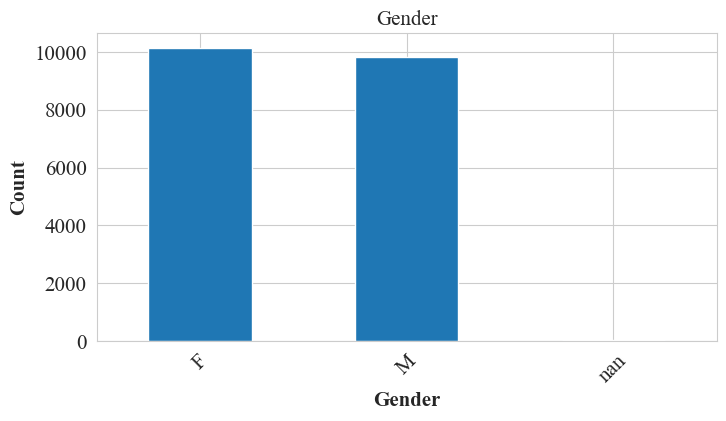


--------------------------------------------------------------------------------
Column : Income Stability
--------------------------------------------------------------------------------
Unique Categories : 2
Income Stability
Low     17501
High     1686
NaN       813
Name: count, dtype: int64


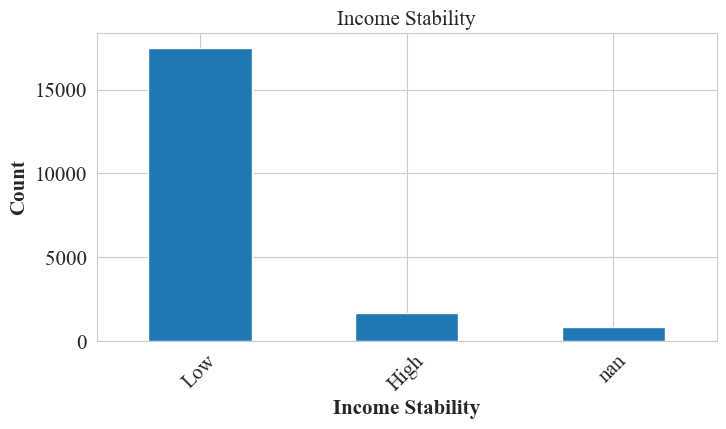


--------------------------------------------------------------------------------
Column : Profession
--------------------------------------------------------------------------------
Unique Categories : 7
Profession
Working                 11405
Commercial associate     5247
Pensioner                1764
State servant            1577
Student                     4
Unemployed                  2
Maternity leave             1
Name: count, dtype: int64


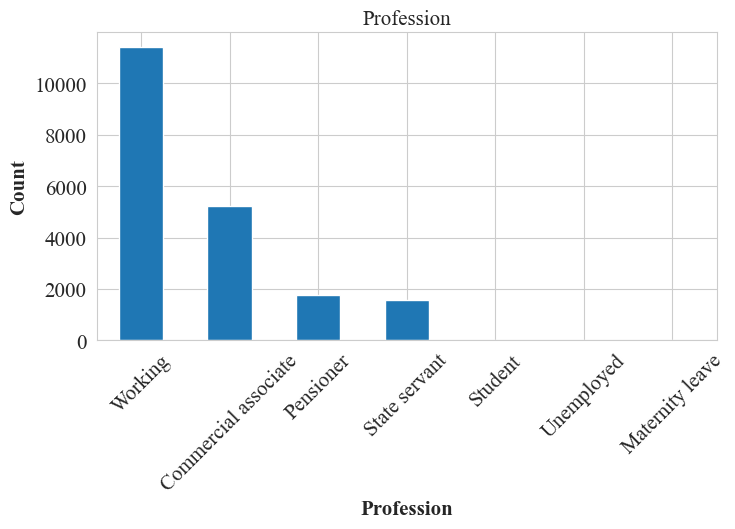


--------------------------------------------------------------------------------
Column : Type of Employment
--------------------------------------------------------------------------------
Unique Categories : 18
Type of Employment
NaN                      4689
Laborers                 3743
Sales staff              2433
Core staff               2232
Managers                 1719
Drivers                  1057
Accountants               886
High skill tech staff     881
Medicine staff            598
Cooking staff             405
Security staff            377
Cleaning staff            230
Private service staff     201
Low-skill Laborers        141
Secretaries               119
Waiters/barmen staff      110
Realty agents              68
HR staff                   60
IT staff                   51
Name: count, dtype: int64


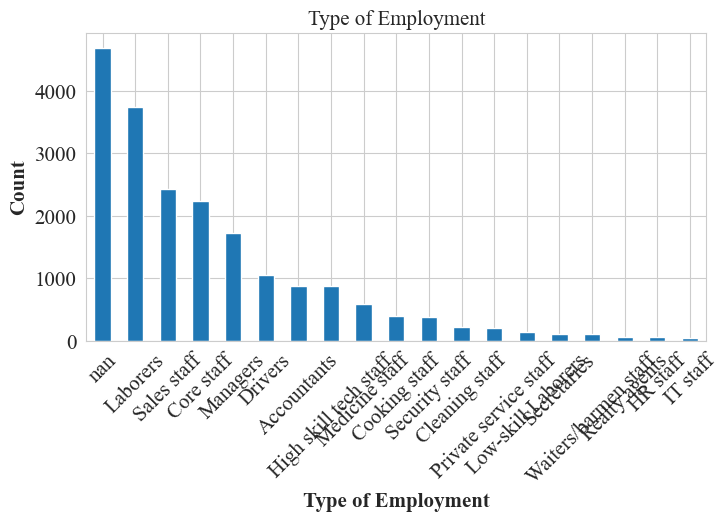


--------------------------------------------------------------------------------
Column : Location
--------------------------------------------------------------------------------
Unique Categories : 3
Location
Semi-Urban    14463
Rural          3436
Urban          2101
Name: count, dtype: int64


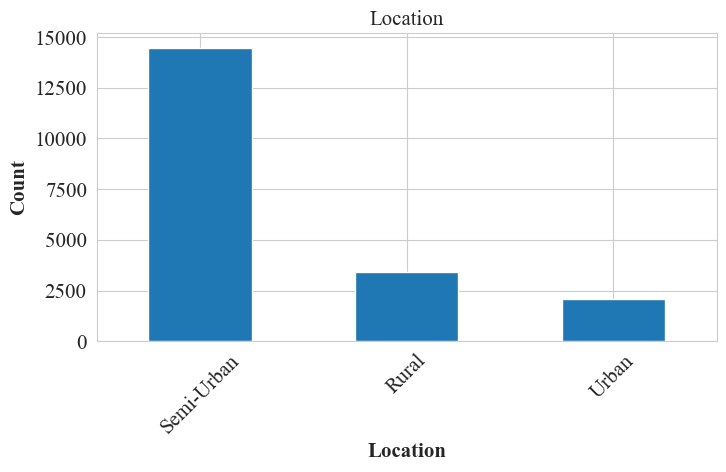


--------------------------------------------------------------------------------
Column : Expense Type 1
--------------------------------------------------------------------------------
Unique Categories : 2
Expense Type 1
N    12816
Y     7184
Name: count, dtype: int64


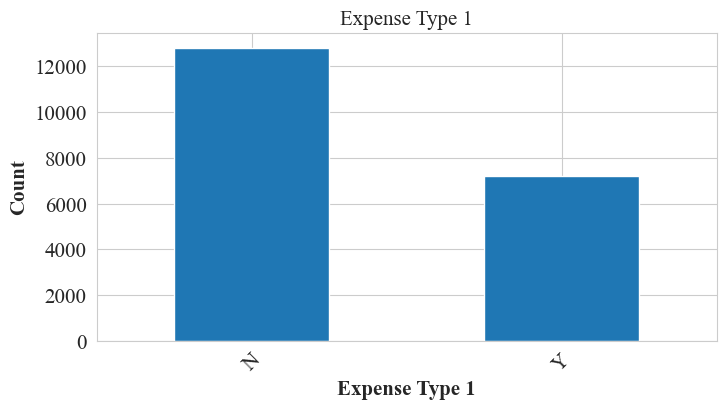


--------------------------------------------------------------------------------
Column : Expense Type 2
--------------------------------------------------------------------------------
Unique Categories : 2
Expense Type 2
Y    13383
N     6617
Name: count, dtype: int64


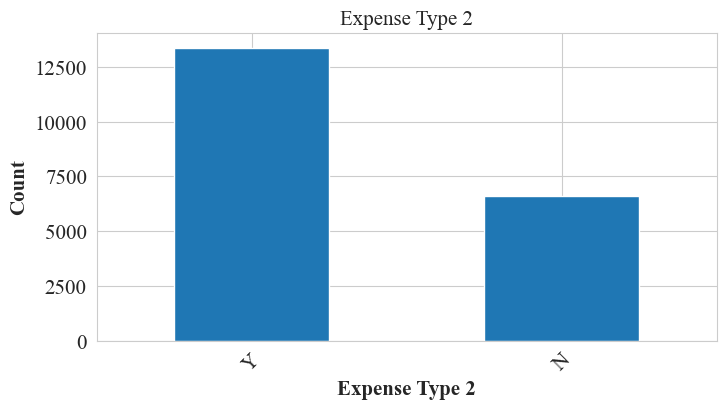


--------------------------------------------------------------------------------
Column : Has Active Credit Card
--------------------------------------------------------------------------------
Unique Categories : 3
Has Active Credit Card
Active         6418
Inactive       6376
Unpossessed    6130
NaN            1076
Name: count, dtype: int64


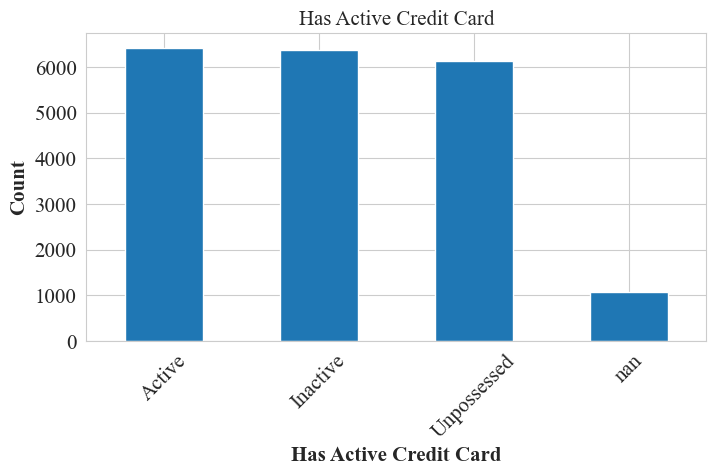


--------------------------------------------------------------------------------
Column : Property Location
--------------------------------------------------------------------------------
Unique Categories : 3
Property Location
Semi-Urban    6839
Rural         6768
Urban         6233
NaN            160
Name: count, dtype: int64


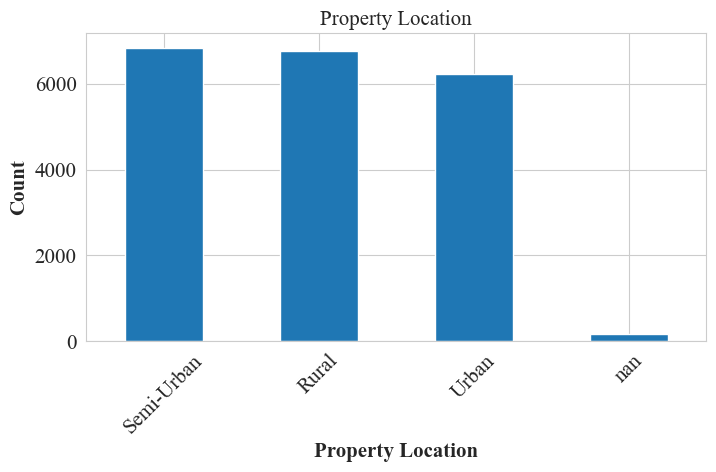



CORRELATION ANALYSIS


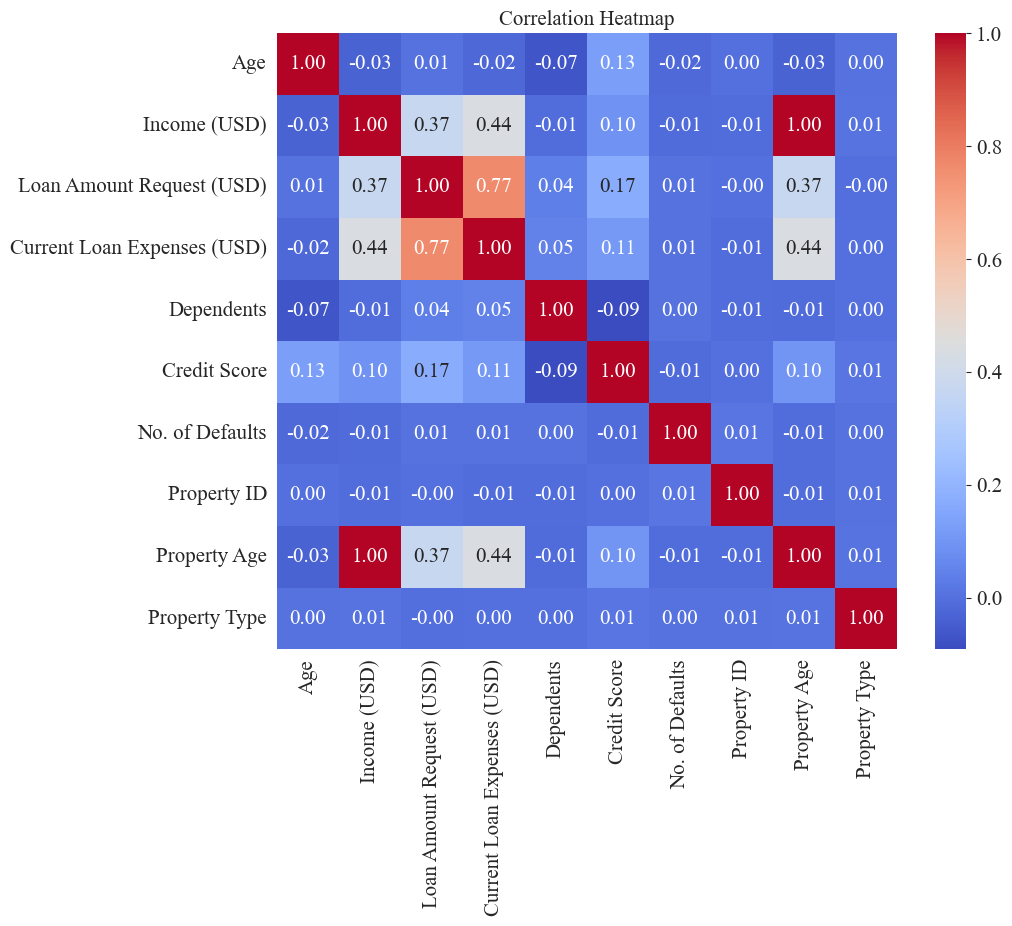


Highly Correlated Feature Pairs
Income (USD), Property Age = 1.0


TARGET ANALYSIS
No target provided as parameter!


FINAL EDA SUMMARY
Rows                     : 20000
Columns                  : 23
Numerical Columns        : 10
Categorical Columns      : 13
Duplicate Rows           : 0
Columns with Missing     : 10
Highly Correlated Pairs  : 1

EDA Completed Successfully.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


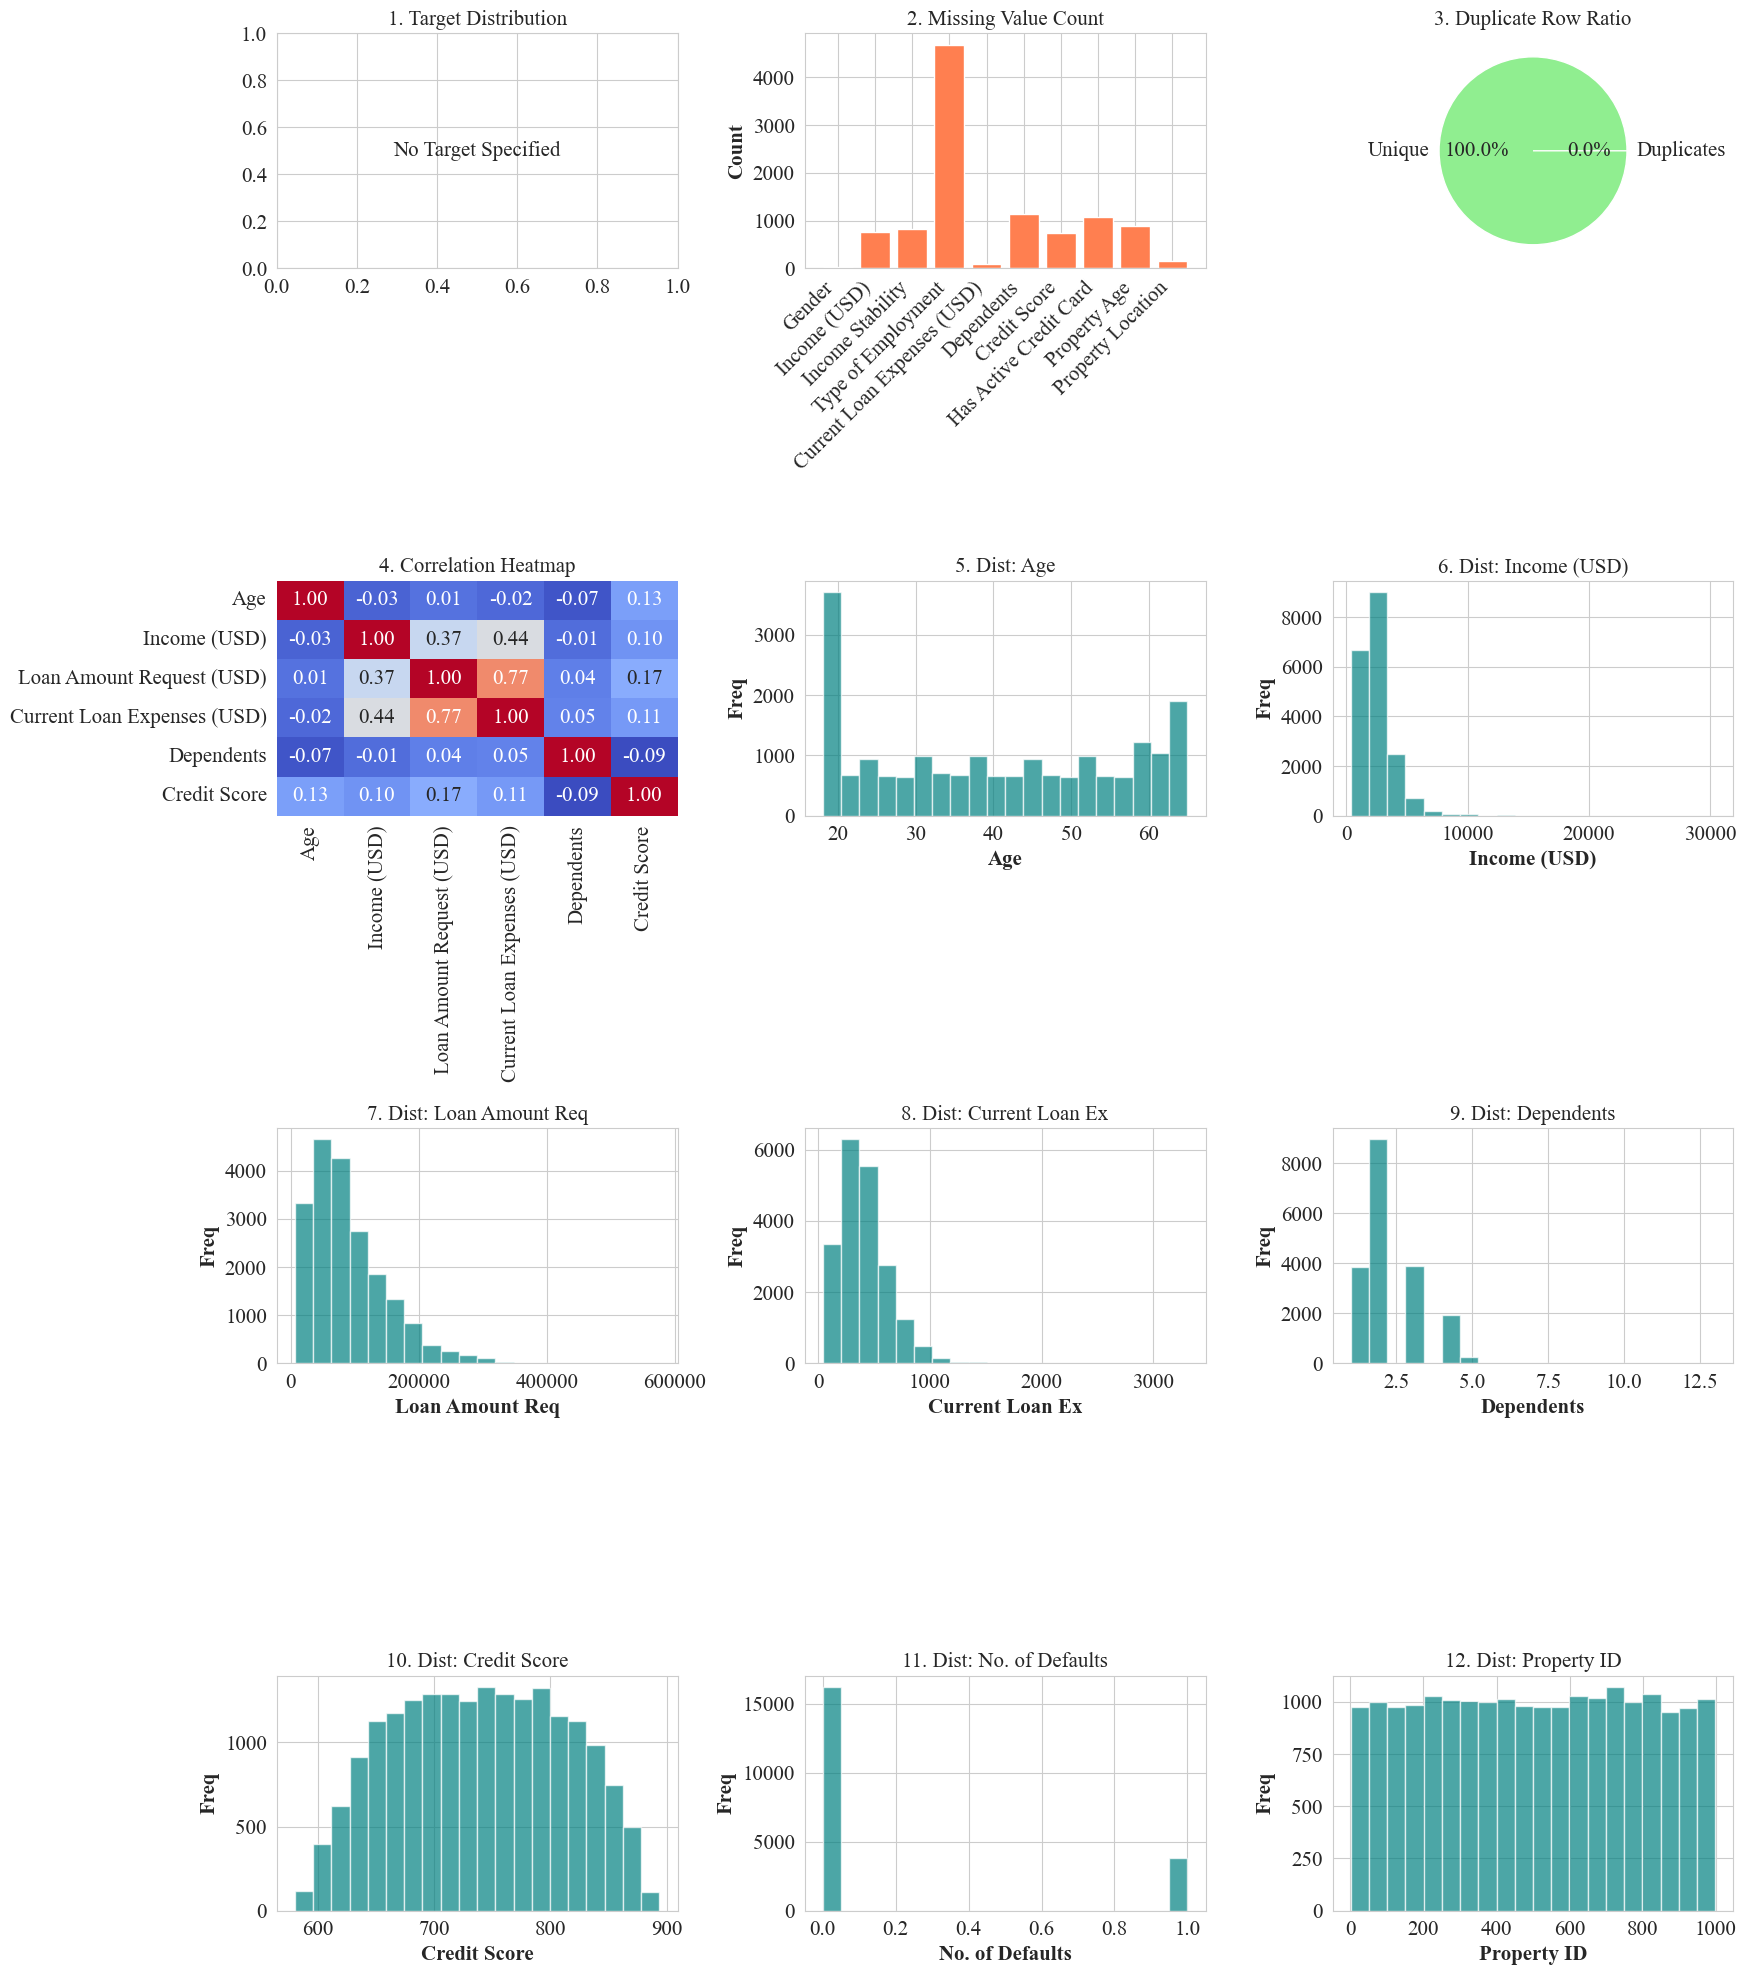

Consolidated EDA 12-subplot figure saved as 'exp3_eda_12_subplots.eps' at 600 DPI.


In [7]:
tabular_eda(test,"regression")

## 5. Data Cleaning (Handling Missing Values)

Different columns are filled in different ways, depending on what kind of column they are:
- **Categorical columns** (Gender, Income Stability, Type of Employment, Has Active Credit Card, Property Location) are filled with the **mode** (the most common value), since that is the most sensible guess for a category.
- **Skewed numeric columns** are filled with the **median** instead of the mean, because the median is not pulled around by a few very large or very small values the way the mean is. Most of the money-related columns here (income, loan amount, expenses, property price) are skewed, so the median is used for them.
- **Credit Score** is filled with the **mean**, since it behaves more like a normal, evenly-spread score rather than a skewed money value.
- A few columns (`Current Loan Expenses (USD)`, `Loan Sanction Amount (USD)`, `Co-Applicant`, `Property Price`) use `-999` as a placeholder for a missing value instead of leaving it blank, so that placeholder is first turned into a real missing value (`NaN`) before it is filled in.


### Train Data Set

In [8]:
# Data Cleaning

# Missing value Imputation
train["Gender"]=train["Gender"].fillna(train["Gender"].mode()[0])
train["Income Stability"]=train["Income Stability"].fillna(train["Income Stability"].mode()[0])
train["Type of Employment"]=train["Type of Employment"].fillna(train["Type of Employment"].mode()[0])
train["Has Active Credit Card"]=train["Has Active Credit Card"].fillna(train["Has Active Credit Card"].mode()[0])
train["Property Location"]=train["Property Location"].fillna(train["Property Location"].mode()[0])
train["Income (USD)"] = train["Income (USD)"].fillna(train["Income (USD)"].median())
train["Loan Amount Request (USD)"] = (train["Loan Amount Request (USD)"].fillna(train["Loan Amount Request (USD)"].median()))
train["Current Loan Expenses (USD)"] = train["Current Loan Expenses (USD)"].replace(-999, np.nan)
train["Current Loan Expenses (USD)"] = train["Current Loan Expenses (USD)"].fillna(train["Current Loan Expenses (USD)"].median())
train["Dependents"] = train["Dependents"].fillna(train["Dependents"].median())
train["Credit Score"] = train["Credit Score"].fillna(train["Credit Score"].mean())
train["Property Age"] = train["Property Age"].fillna(train["Property Age"].median())
train["Loan Sanction Amount (USD)"] = train["Loan Sanction Amount (USD)"].replace(-999, np.nan)
train["Loan Sanction Amount (USD)"] = train["Loan Sanction Amount (USD)"].fillna(train["Loan Sanction Amount (USD)"].median())
train["Co-Applicant"] = train["Co-Applicant"].replace(-999, np.nan)
train["Co-Applicant"]=train["Co-Applicant"].fillna(train["Co-Applicant"].mode()[0])
train["Property Price"] = train["Property Price"].replace(-999, np.nan)
train["Property Price"]=train["Property Price"].fillna(train["Property Price"].median())

### Test set


In [9]:
test["Gender"]=test["Gender"].fillna(test["Gender"].mode()[0])
test["Income Stability"]=test["Income Stability"].fillna(test["Income Stability"].mode()[0])
test["Type of Employment"]=test["Type of Employment"].fillna(test["Type of Employment"].mode()[0])
test["Has Active Credit Card"]=test["Has Active Credit Card"].fillna(test["Has Active Credit Card"].mode()[0])
test["Property Location"]=test["Property Location"].fillna(test["Property Location"].mode()[0])
test["Income (USD)"] = test["Income (USD)"].fillna(test["Income (USD)"].median())
test["Loan Amount Request (USD)"] = (test["Loan Amount Request (USD)"].fillna(test["Loan Amount Request (USD)"].median()))
test["Current Loan Expenses (USD)"] = test["Current Loan Expenses (USD)"].replace(-999, np.nan)
test["Current Loan Expenses (USD)"] = test["Current Loan Expenses (USD)"].fillna(test["Current Loan Expenses (USD)"].median())
test["Dependents"] = test["Dependents"].fillna(test["Dependents"].median())
test["Credit Score"] = test["Credit Score"].fillna(test["Credit Score"].mean())
test["Property Age"] = test["Property Age"].fillna(test["Property Age"].median())
test["Co-Applicant"] = pd.to_numeric(test["Co-Applicant"], errors="coerce")
test["Co-Applicant"] = test["Co-Applicant"].replace(-999, np.nan)
test["Co-Applicant"]=test["Co-Applicant"].fillna(test["Co-Applicant"].mode()[0])
test["Property Price"] = pd.to_numeric(test["Property Price"], errors="coerce")
test["Property Price"] = test["Property Price"].replace(-999, np.nan)
test["Property Price"]=test["Property Price"].fillna(test["Property Price"].median())

## 6. Exploratory Data Analysis (After Cleaning)


DATASET OVERVIEW

Rows                : 30000
Columns             : 24

Column Names
--------------------------------------------------------------------------------
Customer ID
Name
Gender
Age
Income (USD)
Income Stability
Profession
Type of Employment
Location
Loan Amount Request (USD)
Current Loan Expenses (USD)
Expense Type 1
Expense Type 2
Dependents
Credit Score
No. of Defaults
Has Active Credit Card
Property ID
Property Age
Property Type
Property Location
Co-Applicant
Property Price
Loan Sanction Amount (USD)

Dataset Info
--------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Customer ID                  30000 non-null  object 
 1   Name                         30000 non-null  object 
 2   Gender                       30000 no

                        count unique               top   freq
Customer ID             30000  30000           C-45413      1
Name                    30000  30000  Marilou Kwiecien      1
Gender                  30000      2                 M  15106
Income Stability        30000      2               Low  27434
Profession              30000      8           Working  16926
Type of Employment      30000     18          Laborers  12848
Location                30000      3        Semi-Urban  21563
Expense Type 1          30000      2                 N  19214
Expense Type 2          30000      2                 Y  20180
Has Active Credit Card  30000      3            Active  11337
Property Location       30000      3        Semi-Urban  10743


COLUMN ANALYSIS

--------------------------------------------------------------------------------
Column : Customer ID
--------------------------------------------------------------------------------
Data Type          : object
['C-36995' 'C-33999' 'C-37

Data Type          : object
['Sales staff' 'Laborers' 'High skill tech staff' 'Secretaries' 'Managers'
 'Cooking staff' 'Core staff' 'Drivers' 'Realty agents' 'Security staff'
 'Accountants' 'Private service staff' 'Waiters/barmen staff'
 'Medicine staff' 'Cleaning staff' 'Low-skill Laborers' 'HR staff'
 'IT staff']

--------------------------------------------------------------------------------
Column : Location
--------------------------------------------------------------------------------
Data Type          : object
['Semi-Urban' 'Rural' 'Urban']

--------------------------------------------------------------------------------
Column : Loan Amount Request (USD)
--------------------------------------------------------------------------------
Data Type          : float64
[ 72809.58  46837.47  45593.04  80057.92 113858.89  34434.72 152561.34
 240311.77  35141.99  42091.29  25765.72  20879.96  96080.6   48894.06
  72448.95 116487.58  70815.01  89489.99  66567.35 112910.57]

showing fi

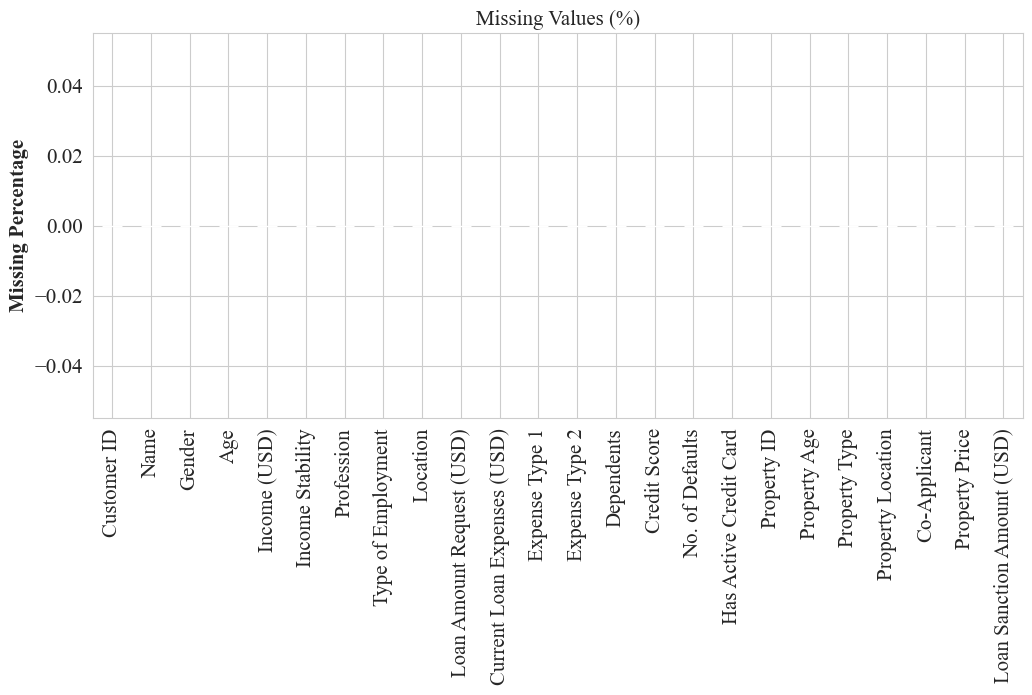



DUPLICATE ANALYSIS
Duplicate Rows       : 0
Duplicate Percentage : 0.00%


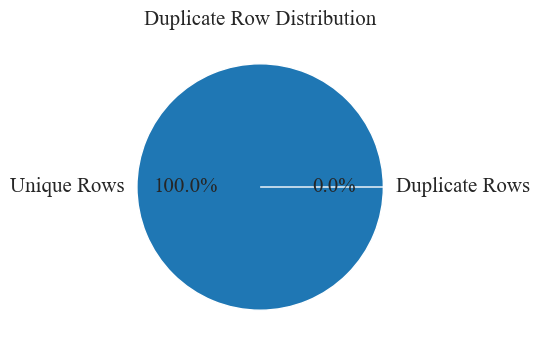



NUMERICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : Age
--------------------------------------------------------------------------------
Mean       : 40.092
Median     : 40.000
Std Dev    : 16.045
Variance   : 257.446
Skewness   : 0.046
Kurtosis   : -1.382


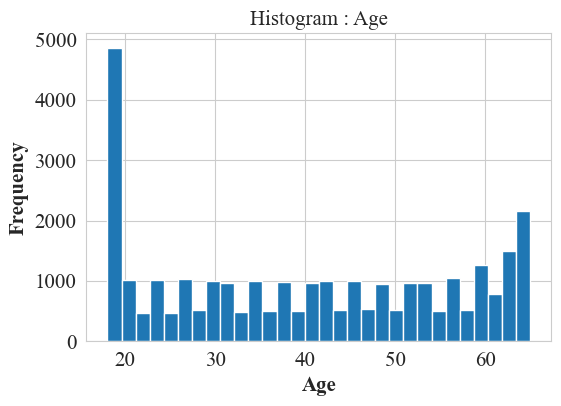

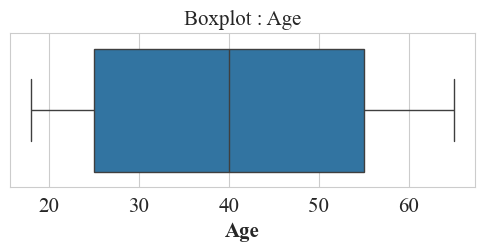

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Income (USD)
--------------------------------------------------------------------------------
Mean       : 2568.320
Median     : 2222.435
Std Dev    : 10369.240
Variance   : 107521143.927
Skewness   : 167.254
Kurtosis   : 28618.336


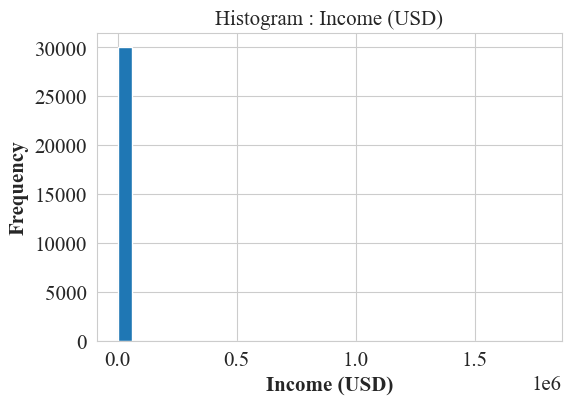

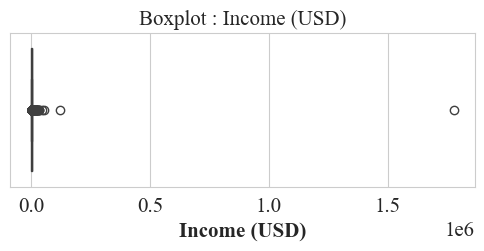

Outliers Detected : 1874

--------------------------------------------------------------------------------
Column : Loan Amount Request (USD)
--------------------------------------------------------------------------------
Mean       : 88826.334
Median     : 75128.075
Std Dev    : 59536.950
Variance   : 3544648368.253
Skewness   : 1.260
Kurtosis   : 2.103


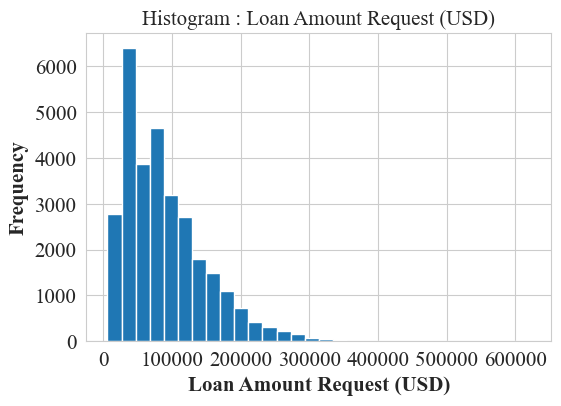

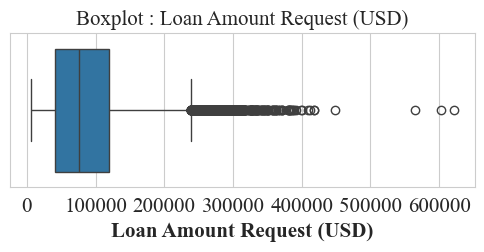

Outliers Detected : 752

--------------------------------------------------------------------------------
Column : Current Loan Expenses (USD)
--------------------------------------------------------------------------------
Mean       : 408.913
Median     : 376.530
Std Dev    : 216.497
Variance   : 46870.939
Skewness   : 1.547
Kurtosis   : 7.984


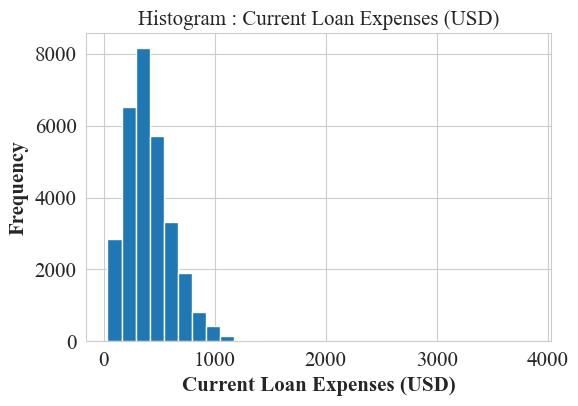

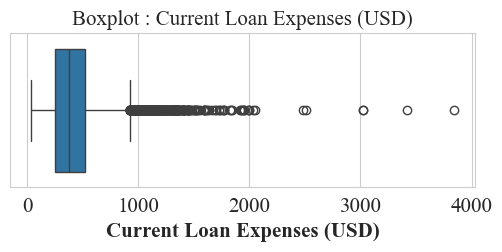

Outliers Detected : 722

--------------------------------------------------------------------------------
Column : Dependents
--------------------------------------------------------------------------------
Mean       : 2.232
Median     : 2.000
Std Dev    : 0.913
Variance   : 0.834
Skewness   : 0.900
Kurtosis   : 1.821


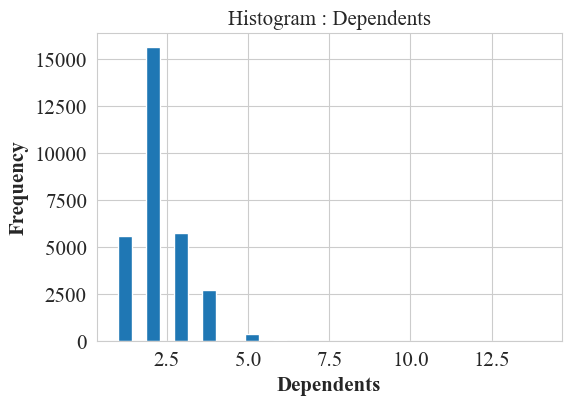

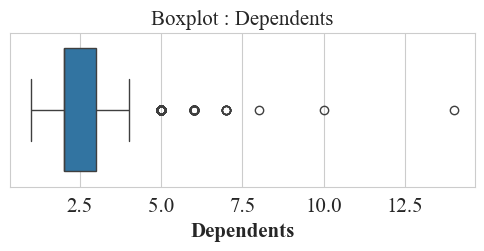

Outliers Detected : 432

--------------------------------------------------------------------------------
Column : Credit Score
--------------------------------------------------------------------------------
Mean       : 739.885
Median     : 739.885
Std Dev    : 70.086
Variance   : 4911.992
Skewness   : -0.021
Kurtosis   : -0.864


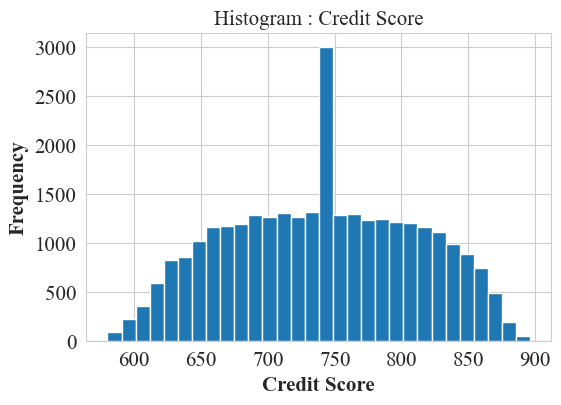

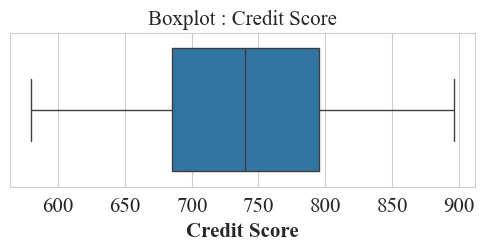

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : No. of Defaults
--------------------------------------------------------------------------------
Mean       : 0.194
Median     : 0.000
Std Dev    : 0.395
Variance   : 0.156
Skewness   : 1.548
Kurtosis   : 0.397


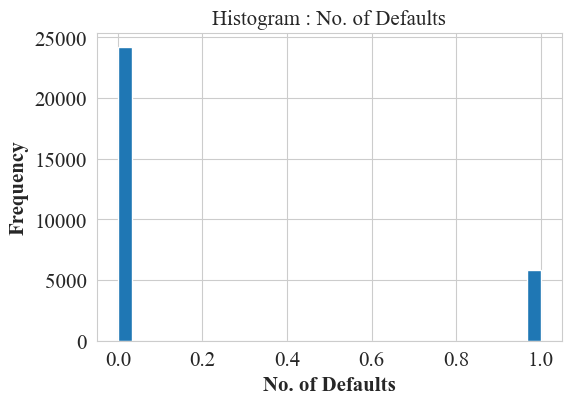

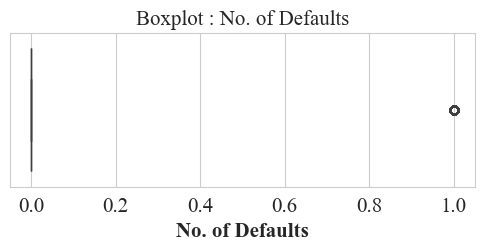

Outliers Detected : 5818

--------------------------------------------------------------------------------
Column : Property ID
--------------------------------------------------------------------------------
Mean       : 501.935
Median     : 504.000
Std Dev    : 288.158
Variance   : 83035.082
Skewness   : -0.011
Kurtosis   : -1.203


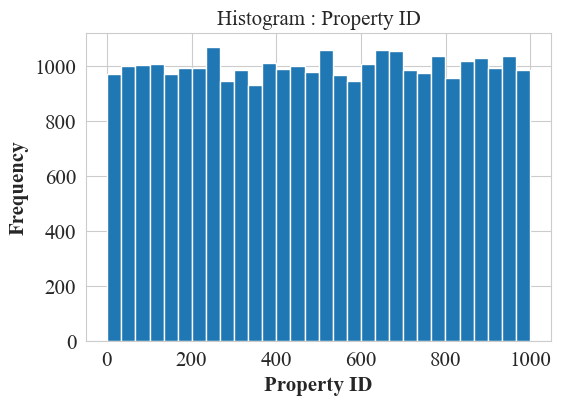

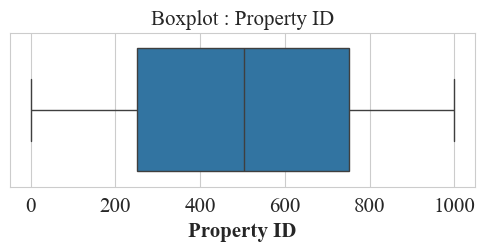

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Property Age
--------------------------------------------------------------------------------
Mean       : 2565.181
Median     : 2223.250
Std Dev    : 10368.159
Variance   : 107498716.828
Skewness   : 167.307
Kurtosis   : 28630.482


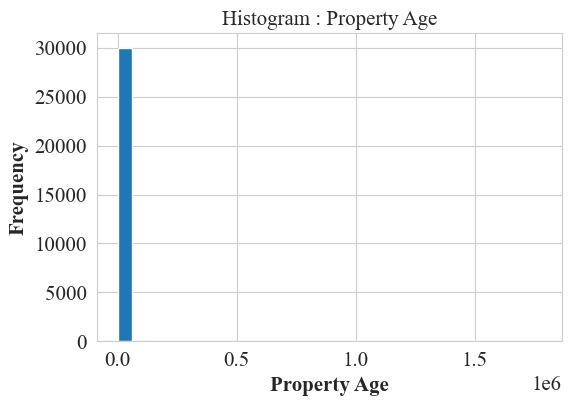

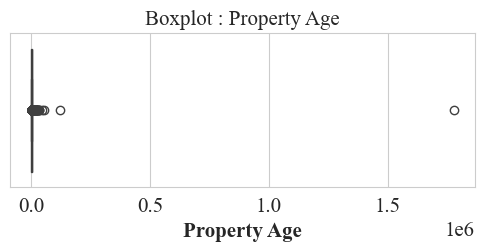

Outliers Detected : 1930

--------------------------------------------------------------------------------
Column : Property Type
--------------------------------------------------------------------------------
Mean       : 2.460
Median     : 2.000
Std Dev    : 1.119
Variance   : 1.251
Skewness   : 0.051
Kurtosis   : -1.359


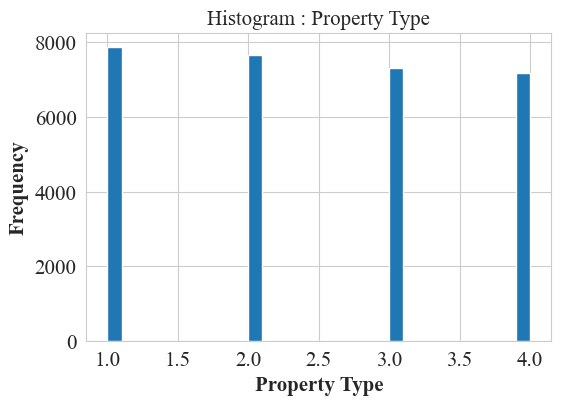

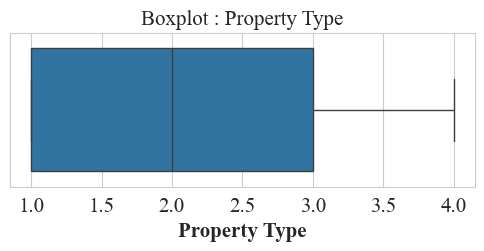

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Co-Applicant
--------------------------------------------------------------------------------
Mean       : 0.856
Median     : 1.000
Std Dev    : 0.351
Variance   : 0.123
Skewness   : -2.030
Kurtosis   : 2.119


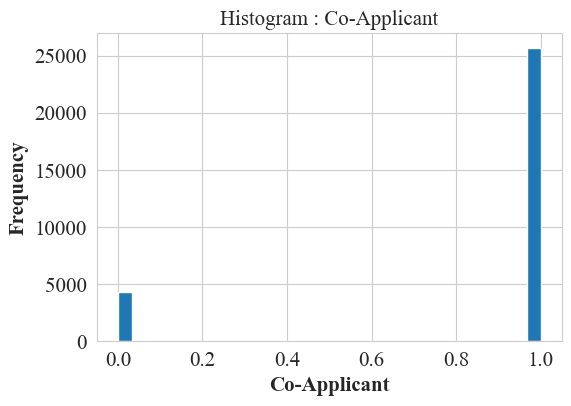

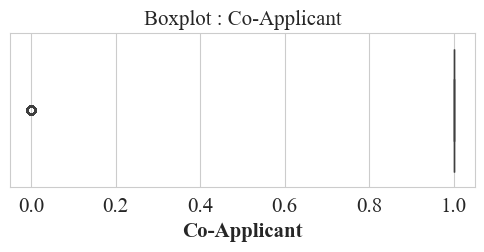

Outliers Detected : 4316

--------------------------------------------------------------------------------
Column : Property Price
--------------------------------------------------------------------------------
Mean       : 133077.046
Median     : 111276.530
Std Dev    : 92454.854
Variance   : 8547900098.694
Skewness   : 1.460
Kurtosis   : 3.312


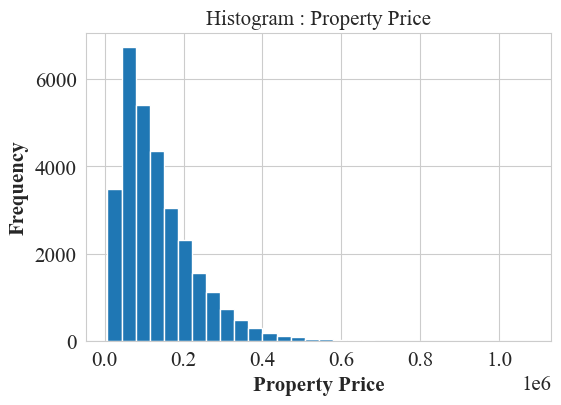

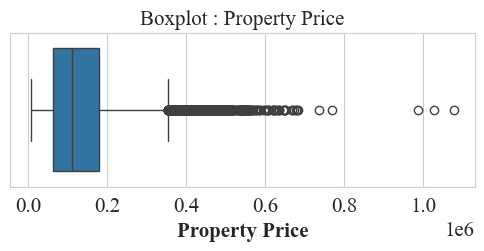

Outliers Detected : 898

--------------------------------------------------------------------------------
Column : Loan Sanction Amount (USD)
--------------------------------------------------------------------------------
Mean       : 47935.623
Median     : 36064.225
Std Dev    : 47699.173
Variance   : 2275211074.882
Skewness   : 1.250
Kurtosis   : 1.873


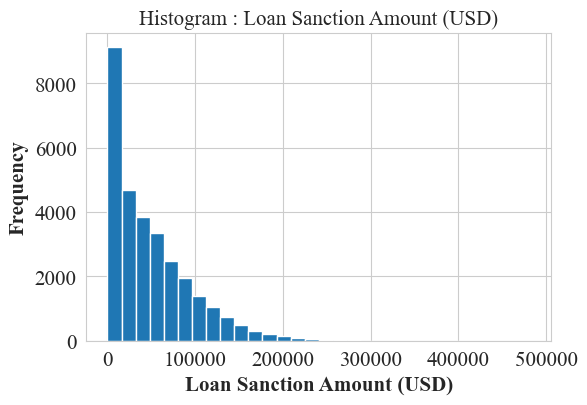

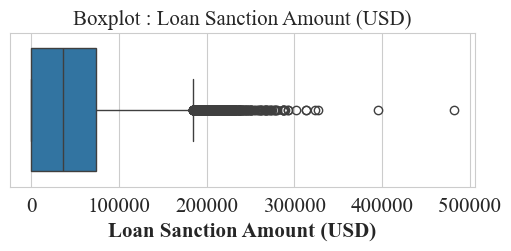

Outliers Detected : 453


CATEGORICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : Customer ID
--------------------------------------------------------------------------------
Unique Categories : 30000

--------------------------------------------------------------------------------
Column : Name
--------------------------------------------------------------------------------
Unique Categories : 30000

--------------------------------------------------------------------------------
Column : Gender
--------------------------------------------------------------------------------
Unique Categories : 2
Gender
M    15106
F    14894
Name: count, dtype: int64


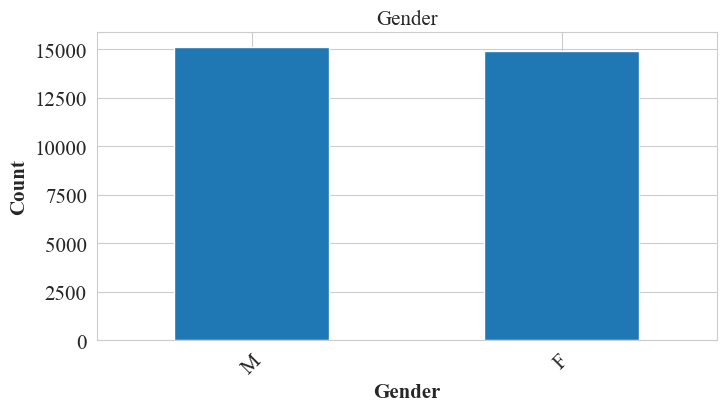


--------------------------------------------------------------------------------
Column : Income Stability
--------------------------------------------------------------------------------
Unique Categories : 2
Income Stability
Low     27434
High     2566
Name: count, dtype: int64


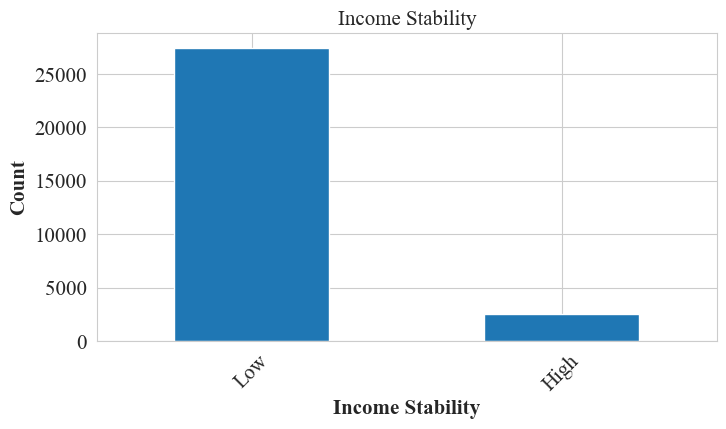


--------------------------------------------------------------------------------
Column : Profession
--------------------------------------------------------------------------------
Unique Categories : 8
Profession
Working                 16926
Commercial associate     7962
Pensioner                2740
State servant            2366
Unemployed                  2
Businessman                 2
Student                     1
Maternity leave             1
Name: count, dtype: int64


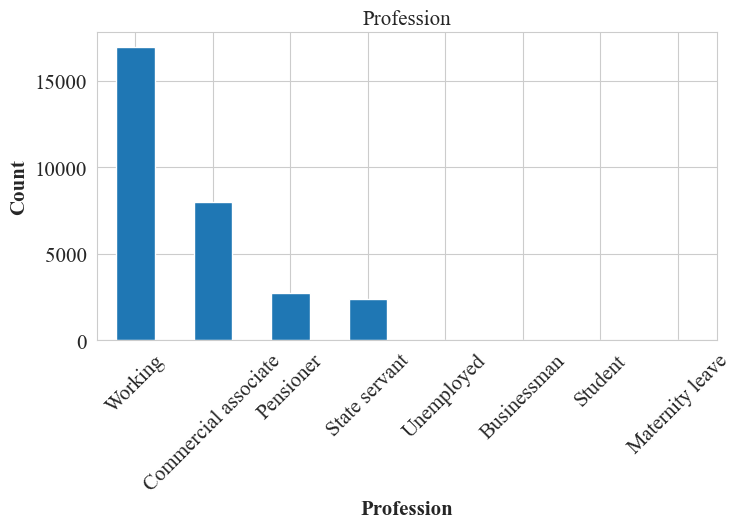


--------------------------------------------------------------------------------
Column : Type of Employment
--------------------------------------------------------------------------------
Unique Categories : 18
Type of Employment
Laborers                 12848
Sales staff               3736
Core staff                3230
Managers                  2495
Drivers                   1606
Accountants               1379
High skill tech staff     1307
Medicine staff             864
Security staff             579
Cooking staff              566
Private service staff      342
Cleaning staff             341
Low-skill Laborers         162
Secretaries                161
Waiters/barmen staff       149
Realty agents               86
IT staff                    77
HR staff                    72
Name: count, dtype: int64


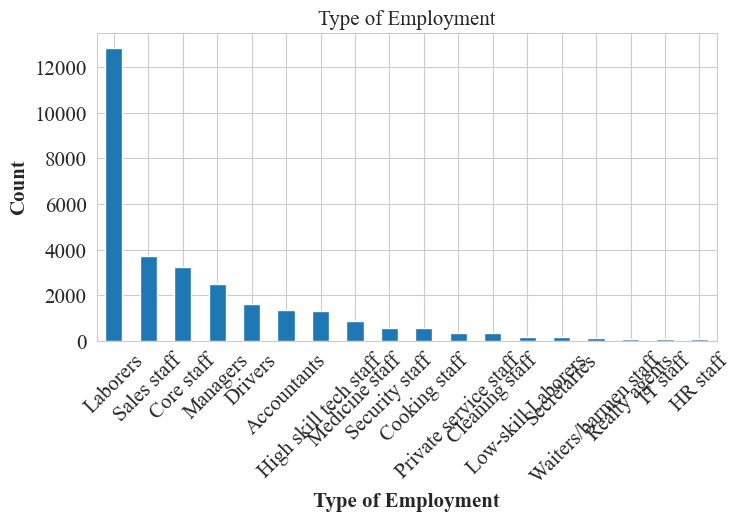


--------------------------------------------------------------------------------
Column : Location
--------------------------------------------------------------------------------
Unique Categories : 3
Location
Semi-Urban    21563
Rural          5338
Urban          3099
Name: count, dtype: int64


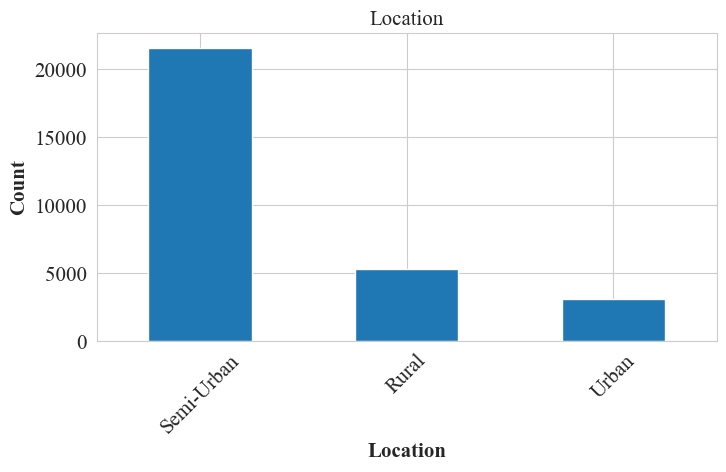


--------------------------------------------------------------------------------
Column : Expense Type 1
--------------------------------------------------------------------------------
Unique Categories : 2
Expense Type 1
N    19214
Y    10786
Name: count, dtype: int64


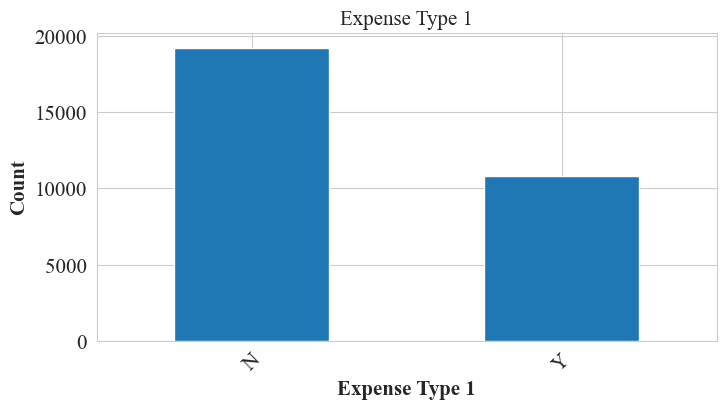


--------------------------------------------------------------------------------
Column : Expense Type 2
--------------------------------------------------------------------------------
Unique Categories : 2
Expense Type 2
Y    20180
N     9820
Name: count, dtype: int64


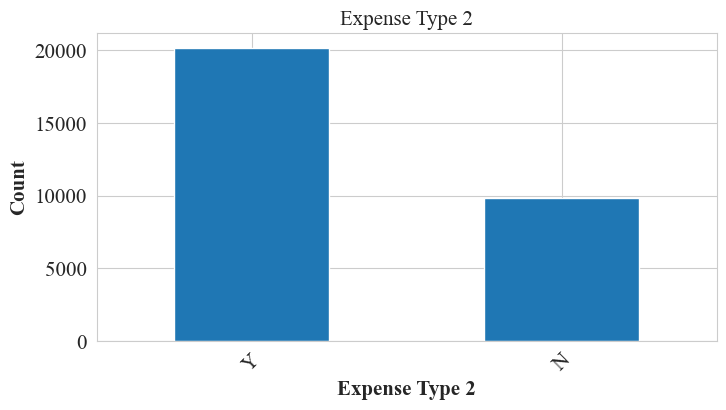


--------------------------------------------------------------------------------
Column : Has Active Credit Card
--------------------------------------------------------------------------------
Unique Categories : 3
Has Active Credit Card
Active         11337
Inactive        9466
Unpossessed     9197
Name: count, dtype: int64


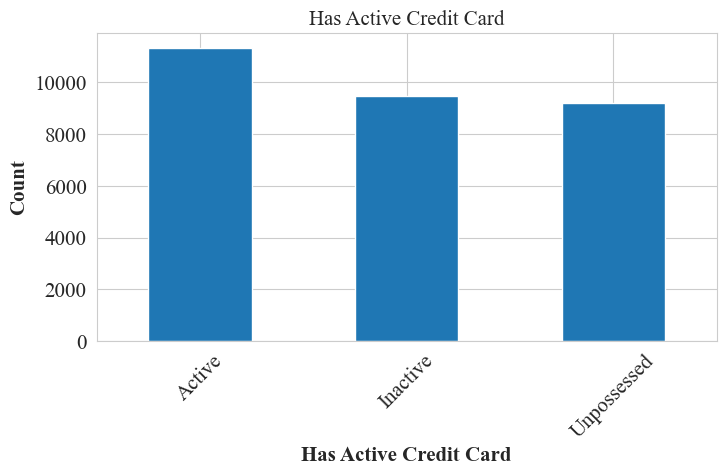


--------------------------------------------------------------------------------
Column : Property Location
--------------------------------------------------------------------------------
Unique Categories : 3
Property Location
Semi-Urban    10743
Rural         10041
Urban          9216
Name: count, dtype: int64


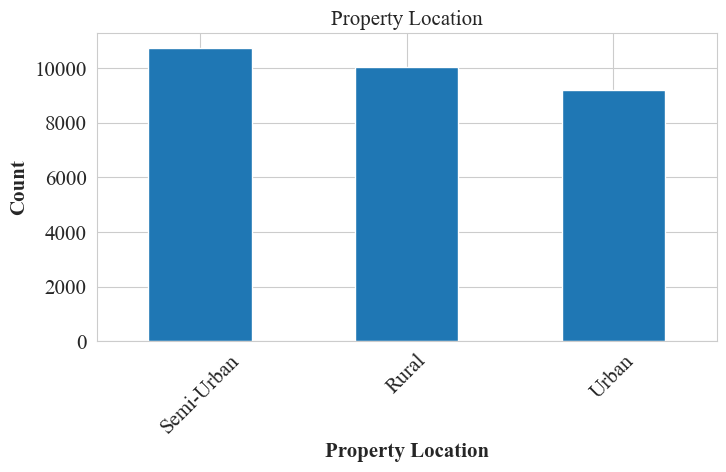



CORRELATION ANALYSIS


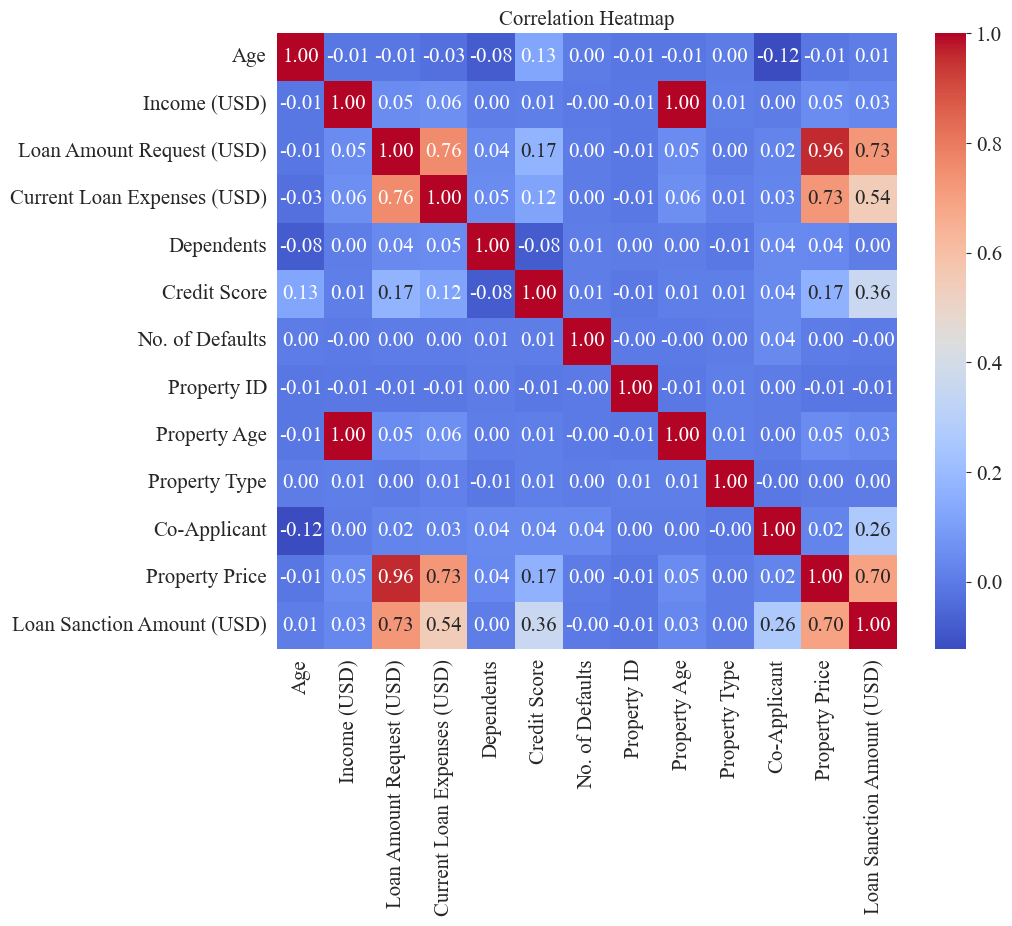


Highly Correlated Feature Pairs
Income (USD), Property Age = 0.9998857191893838
Loan Amount Request (USD), Property Price = 0.9588551226045647


TARGET ANALYSIS
count     30000.000000
mean      47935.623215
std       47699.172686
min           0.000000
25%           0.000000
50%       36064.225000
75%       73763.532500
max      481907.320000
Name: Loan Sanction Amount (USD), dtype: float64


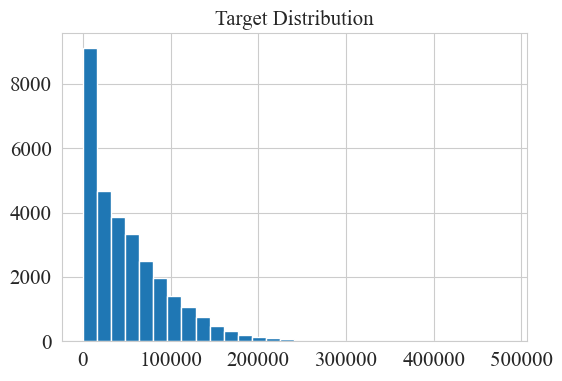



FINAL EDA SUMMARY
Rows                     : 30000
Columns                  : 24
Numerical Columns        : 13
Categorical Columns      : 11
Duplicate Rows           : 0
Columns with Missing     : 0
Highly Correlated Pairs  : 2

EDA Completed Successfully.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


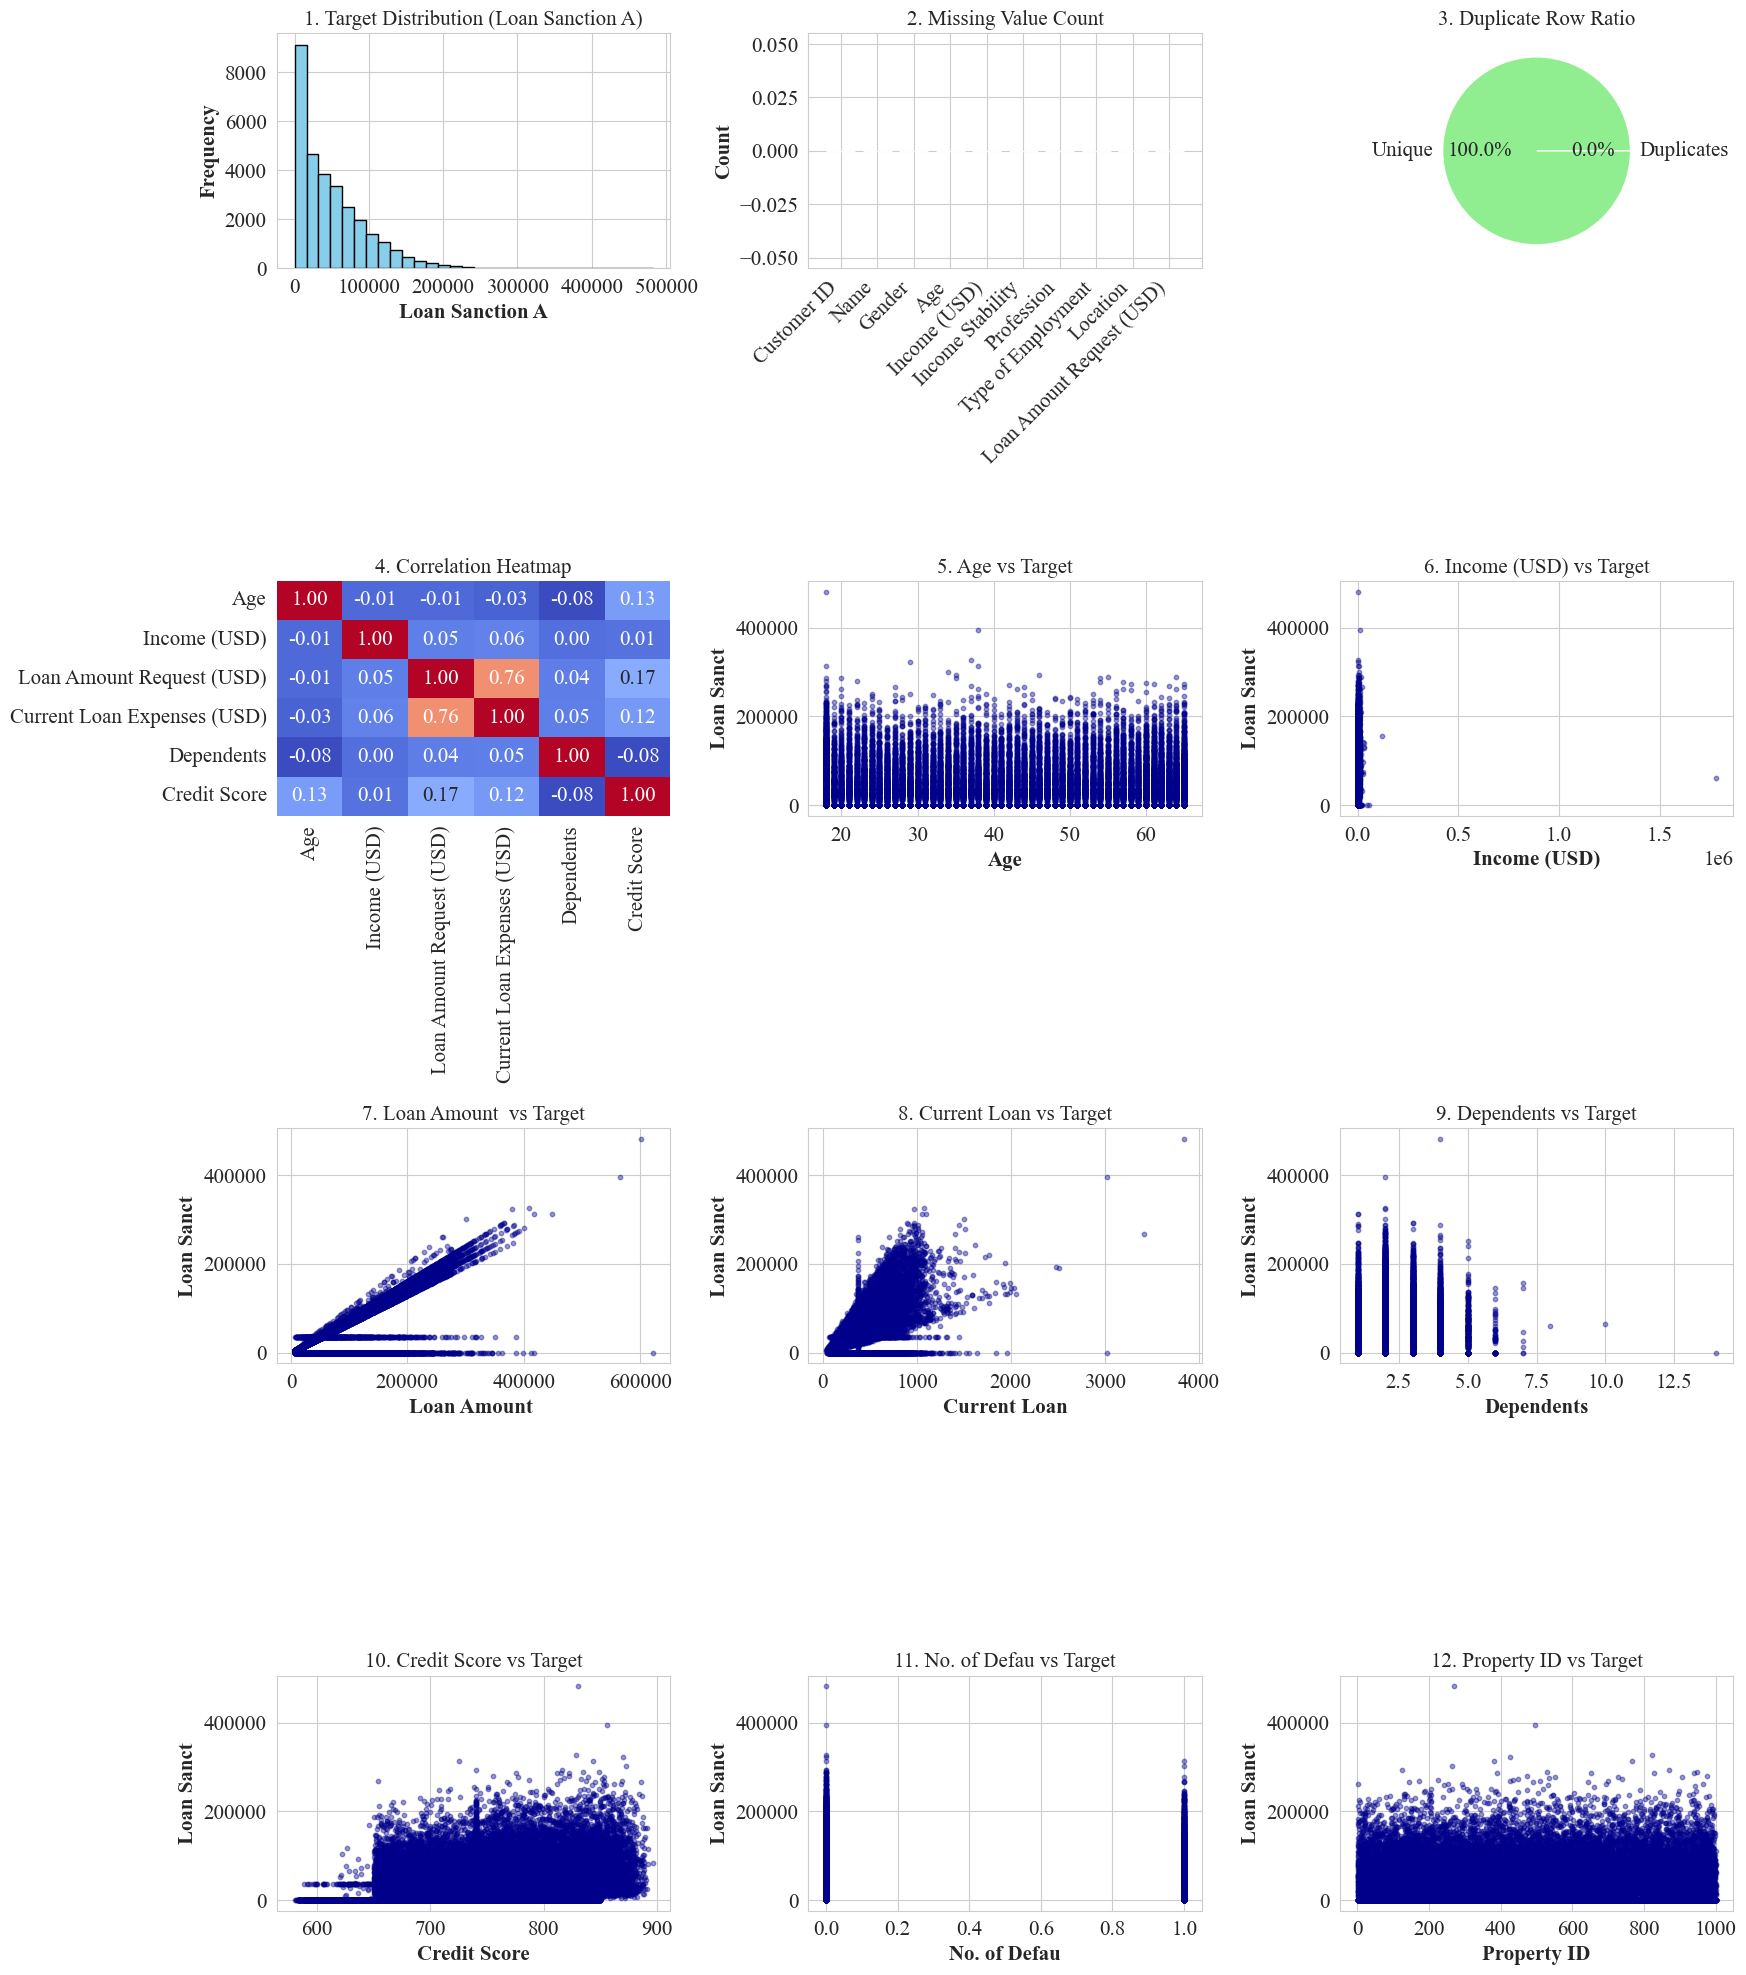

Consolidated EDA 12-subplot figure saved as 'exp3_eda_12_subplots.eps' at 600 DPI.


In [10]:
tabular_eda(train,"regression","Loan Sanction Amount (USD)")

DATASET OVERVIEW

Rows                : 20000
Columns             : 23

Column Names
--------------------------------------------------------------------------------
Customer ID
Name
Gender
Age
Income (USD)
Income Stability
Profession
Type of Employment
Location
Loan Amount Request (USD)
Current Loan Expenses (USD)
Expense Type 1
Expense Type 2
Dependents
Credit Score
No. of Defaults
Has Active Credit Card
Property ID
Property Age
Property Type
Property Location
Co-Applicant
Property Price

Dataset Info
--------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Customer ID                  20000 non-null  object 
 1   Name                         20000 non-null  object 
 2   Gender                       20000 non-null  object 
 3   Age   

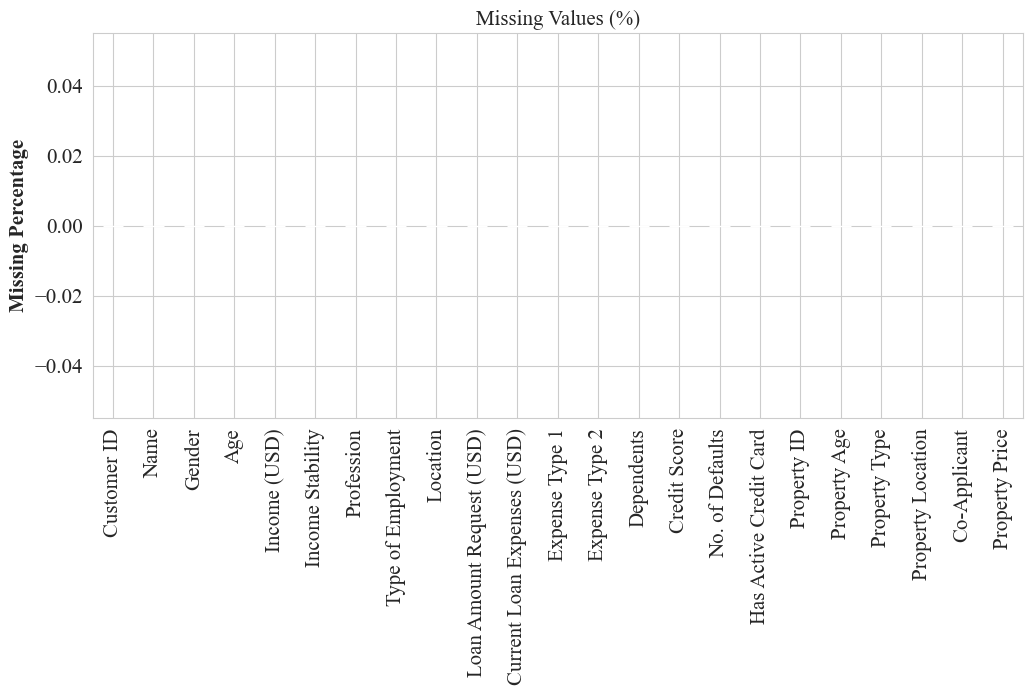



DUPLICATE ANALYSIS
Duplicate Rows       : 0
Duplicate Percentage : 0.00%


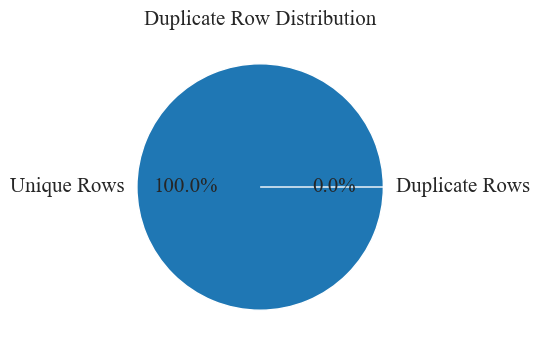



NUMERICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : Age
--------------------------------------------------------------------------------
Mean       : 39.941
Median     : 40.000
Std Dev    : 16.098
Variance   : 259.133
Skewness   : 0.055
Kurtosis   : -1.387


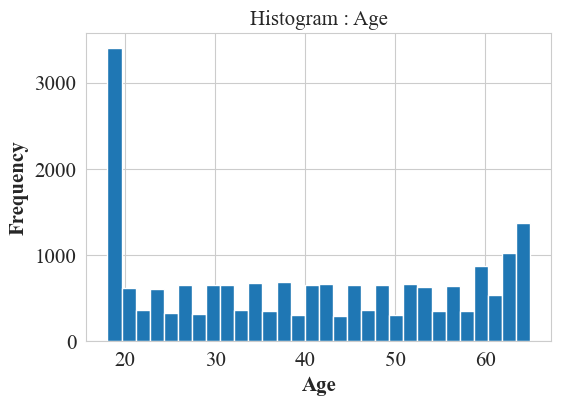

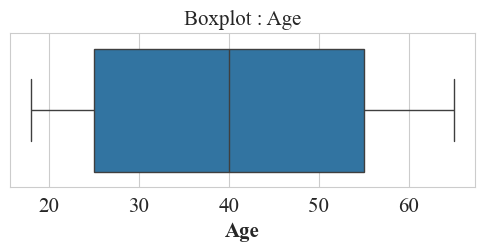

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Income (USD)
--------------------------------------------------------------------------------
Mean       : 2525.280
Median     : 2224.590
Std Dev    : 1390.373
Variance   : 1933136.886
Skewness   : 3.491
Kurtosis   : 32.367


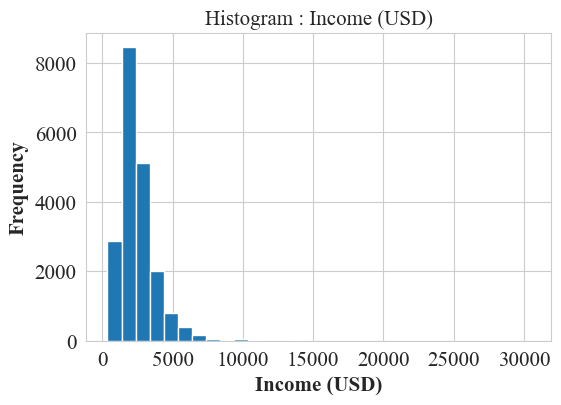

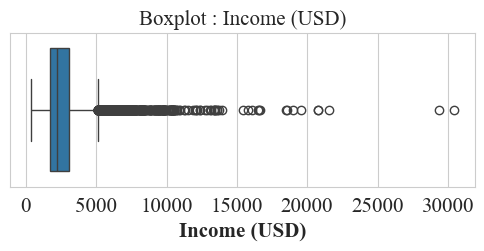

Outliers Detected : 902



--------------------------------------------------------------------------------
Column : Loan Amount Request (USD)
--------------------------------------------------------------------------------
Mean       : 88859.077
Median     : 74565.990
Std Dev    : 60007.334
Variance   : 3600880094.522
Skewness   : 1.278
Kurtosis   : 1.971


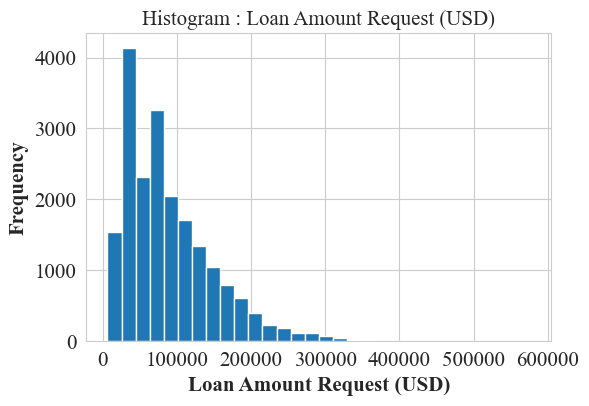

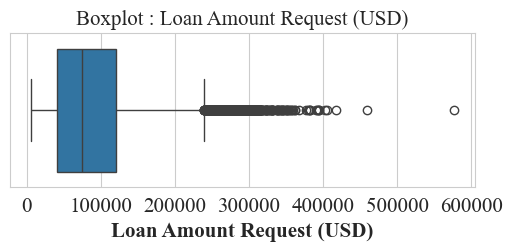

Outliers Detected : 511

--------------------------------------------------------------------------------
Column : Current Loan Expenses (USD)
--------------------------------------------------------------------------------
Mean       : 408.319
Median     : 374.000
Std Dev    : 215.410
Variance   : 46401.277
Skewness   : 1.382
Kurtosis   : 5.489


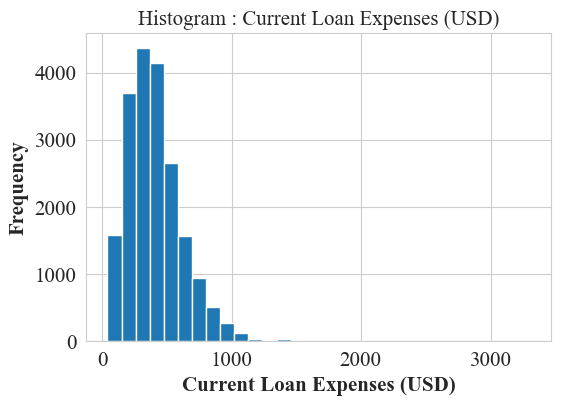

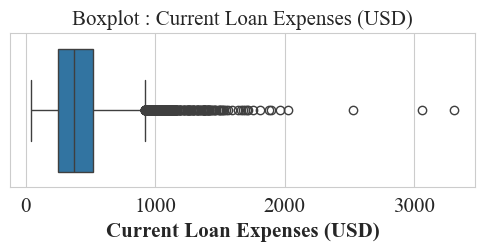

Outliers Detected : 499

--------------------------------------------------------------------------------
Column : Dependents
--------------------------------------------------------------------------------
Mean       : 2.237
Median     : 2.000
Std Dev    : 0.927
Variance   : 0.860
Skewness   : 0.872
Kurtosis   : 1.757


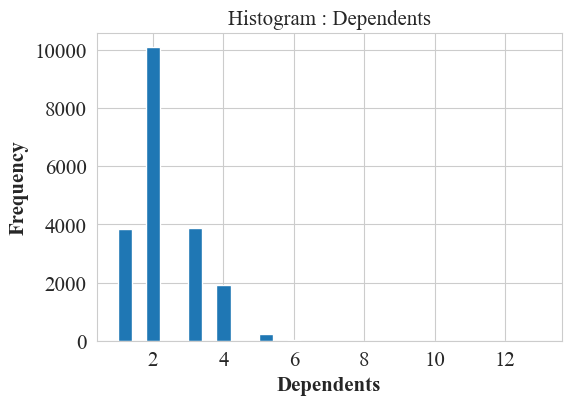

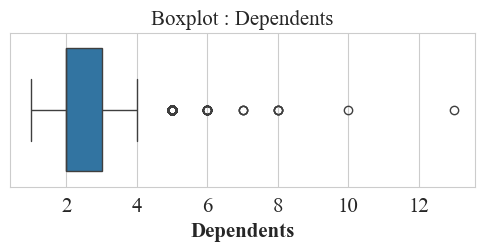

Outliers Detected : 275

--------------------------------------------------------------------------------
Column : Credit Score
--------------------------------------------------------------------------------
Mean       : 738.822
Median     : 738.822
Std Dev    : 71.049
Variance   : 5047.926
Skewness   : -0.012
Kurtosis   : -0.914


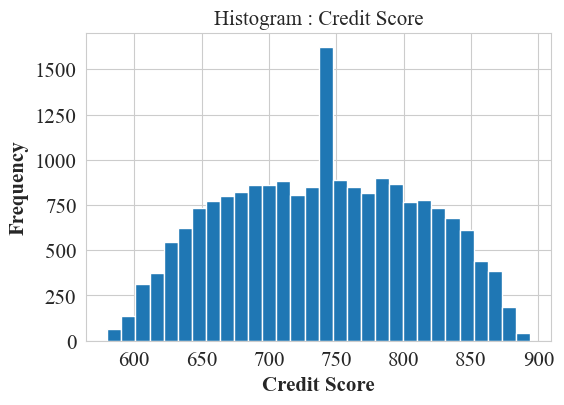

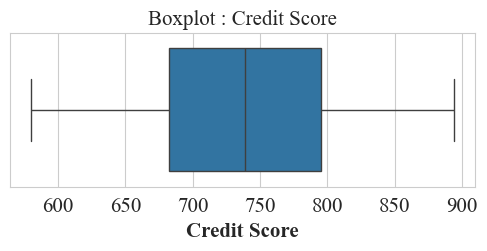

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : No. of Defaults
--------------------------------------------------------------------------------
Mean       : 0.190
Median     : 0.000
Std Dev    : 0.392
Variance   : 0.154
Skewness   : 1.585
Kurtosis   : 0.511


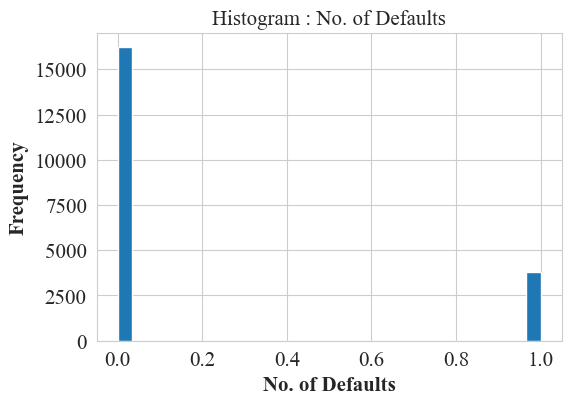

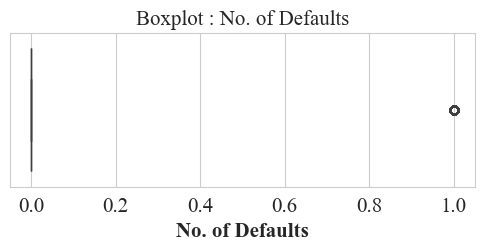

Outliers Detected : 3790

--------------------------------------------------------------------------------
Column : Property ID
--------------------------------------------------------------------------------
Mean       : 501.024
Median     : 501.000
Std Dev    : 287.538
Variance   : 82677.941
Skewness   : -0.007
Kurtosis   : -1.194


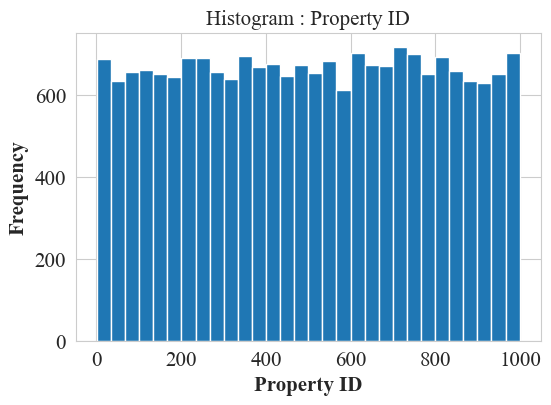

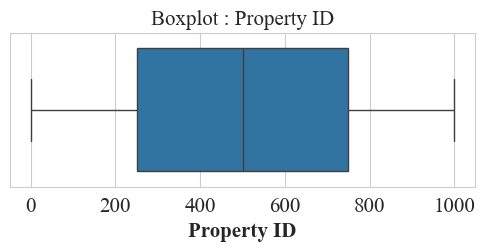

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Property Age
--------------------------------------------------------------------------------
Mean       : 2520.120
Median     : 2220.605
Std Dev    : 1378.260
Variance   : 1899600.051
Skewness   : 3.454
Kurtosis   : 32.031


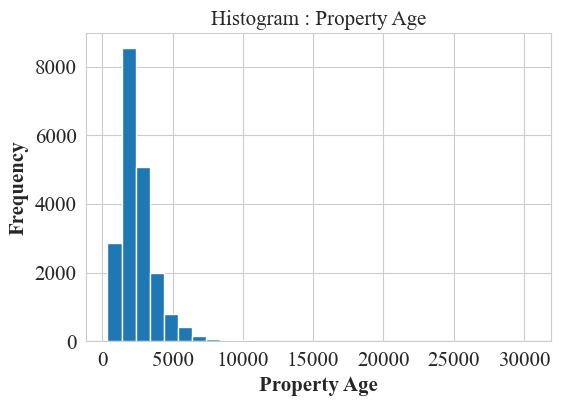

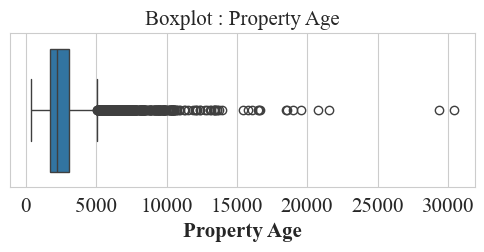

Outliers Detected : 902

--------------------------------------------------------------------------------
Column : Property Type
--------------------------------------------------------------------------------
Mean       : 2.472
Median     : 2.000
Std Dev    : 1.126
Variance   : 1.267
Skewness   : 0.034
Kurtosis   : -1.376


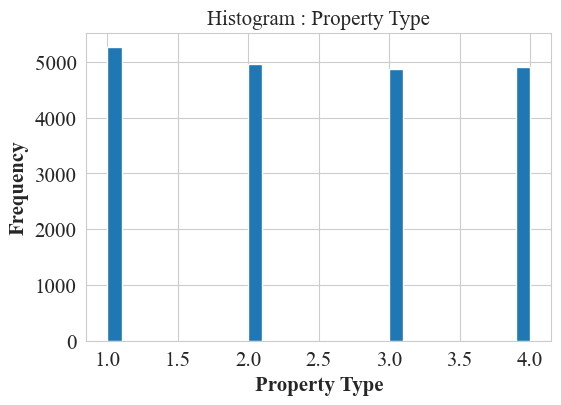

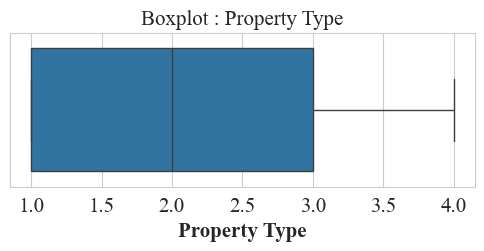

Outliers Detected : 0



--------------------------------------------------------------------------------
Column : Co-Applicant
--------------------------------------------------------------------------------
Mean       : 0.854
Median     : 1.000
Std Dev    : 0.353
Variance   : 0.125
Skewness   : -2.006
Kurtosis   : 2.023


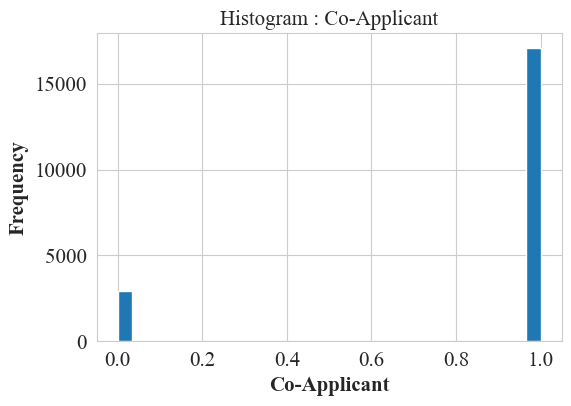

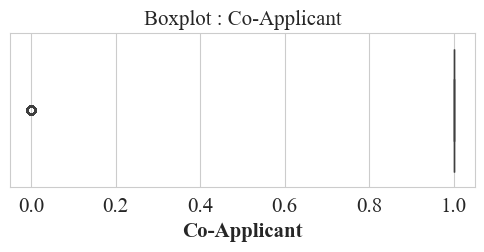

Outliers Detected : 2919

--------------------------------------------------------------------------------
Column : Property Price
--------------------------------------------------------------------------------
Mean       : 133276.702
Median     : 110871.825
Std Dev    : 92964.884
Variance   : 8642469621.198
Skewness   : 1.399
Kurtosis   : 2.548


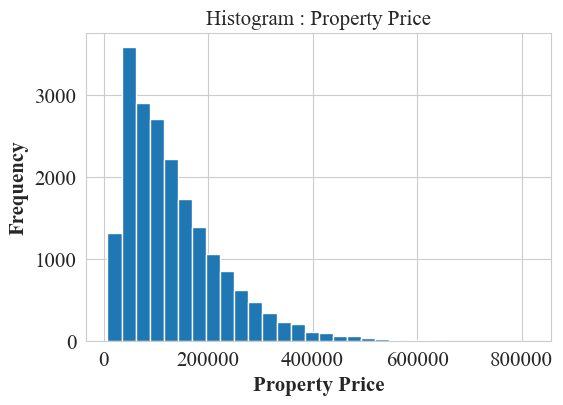

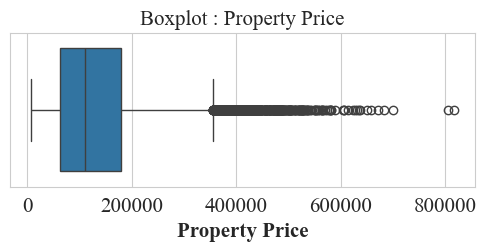

Outliers Detected : 628


CATEGORICAL FEATURE ANALYSIS



--------------------------------------------------------------------------------
Column : Customer ID
--------------------------------------------------------------------------------
Unique Categories : 20000

--------------------------------------------------------------------------------
Column : Name
--------------------------------------------------------------------------------
Unique Categories : 20000

--------------------------------------------------------------------------------
Column : Gender
--------------------------------------------------------------------------------
Unique Categories : 2
Gender
F    10173
M     9827
Name: count, dtype: int64


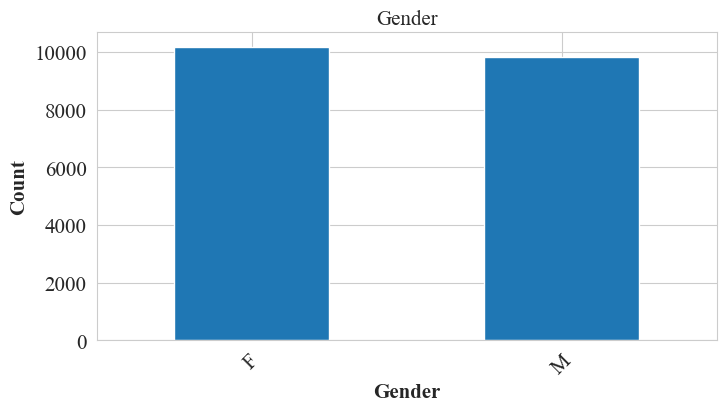


--------------------------------------------------------------------------------
Column : Income Stability
--------------------------------------------------------------------------------
Unique Categories : 2
Income Stability
Low     18314
High     1686
Name: count, dtype: int64


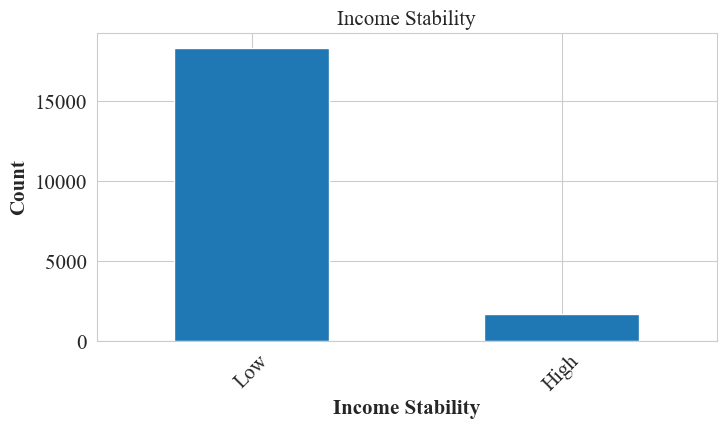


--------------------------------------------------------------------------------
Column : Profession
--------------------------------------------------------------------------------
Unique Categories : 7
Profession
Working                 11405
Commercial associate     5247
Pensioner                1764
State servant            1577
Student                     4
Unemployed                  2
Maternity leave             1
Name: count, dtype: int64


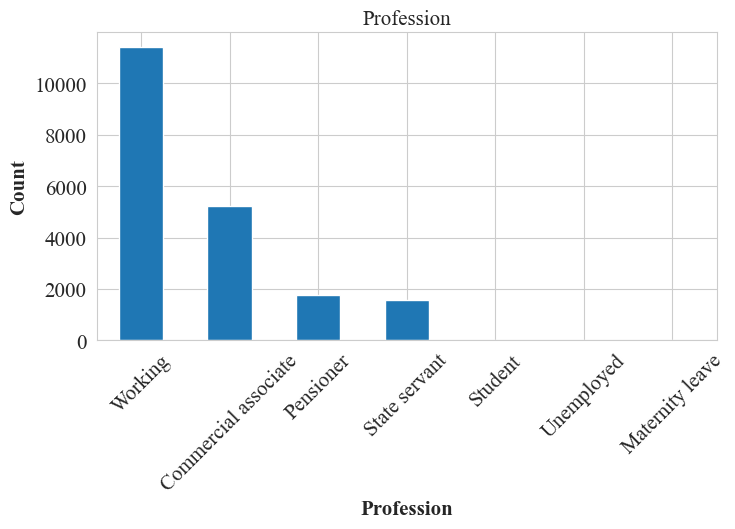


--------------------------------------------------------------------------------
Column : Type of Employment
--------------------------------------------------------------------------------
Unique Categories : 18
Type of Employment
Laborers                 8432
Sales staff              2433
Core staff               2232
Managers                 1719
Drivers                  1057
Accountants               886
High skill tech staff     881
Medicine staff            598
Cooking staff             405
Security staff            377
Cleaning staff            230
Private service staff     201
Low-skill Laborers        141
Secretaries               119
Waiters/barmen staff      110
Realty agents              68
HR staff                   60
IT staff                   51
Name: count, dtype: int64


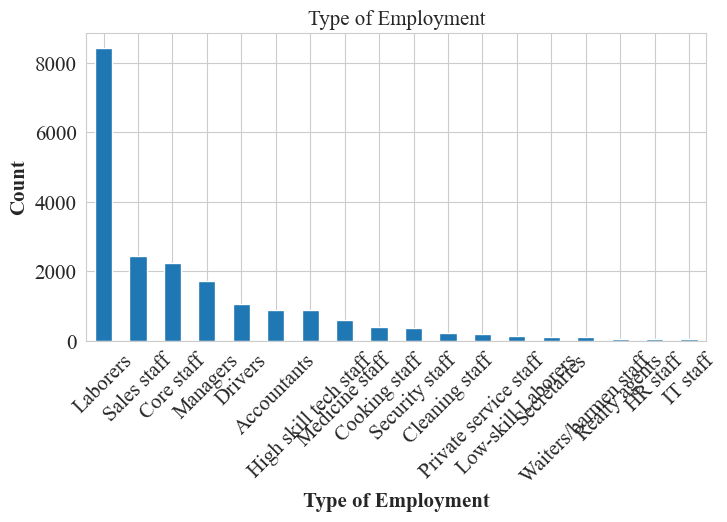


--------------------------------------------------------------------------------
Column : Location
--------------------------------------------------------------------------------
Unique Categories : 3
Location
Semi-Urban    14463
Rural          3436
Urban          2101
Name: count, dtype: int64


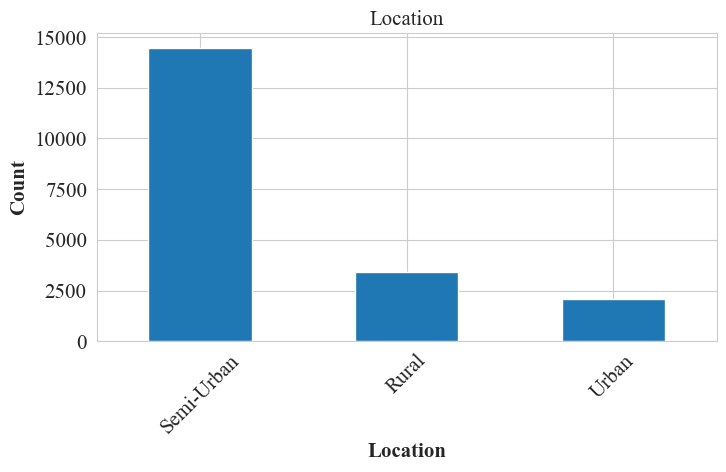


--------------------------------------------------------------------------------
Column : Expense Type 1
--------------------------------------------------------------------------------
Unique Categories : 2
Expense Type 1
N    12816
Y     7184
Name: count, dtype: int64


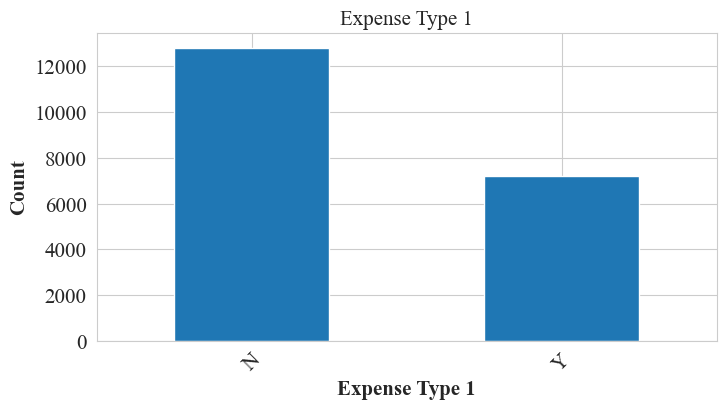


--------------------------------------------------------------------------------
Column : Expense Type 2
--------------------------------------------------------------------------------
Unique Categories : 2
Expense Type 2
Y    13383
N     6617
Name: count, dtype: int64


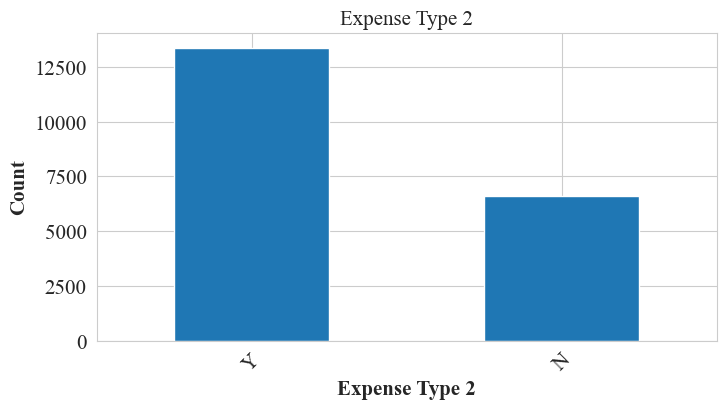


--------------------------------------------------------------------------------
Column : Has Active Credit Card
--------------------------------------------------------------------------------
Unique Categories : 3
Has Active Credit Card
Active         7494
Inactive       6376
Unpossessed    6130
Name: count, dtype: int64


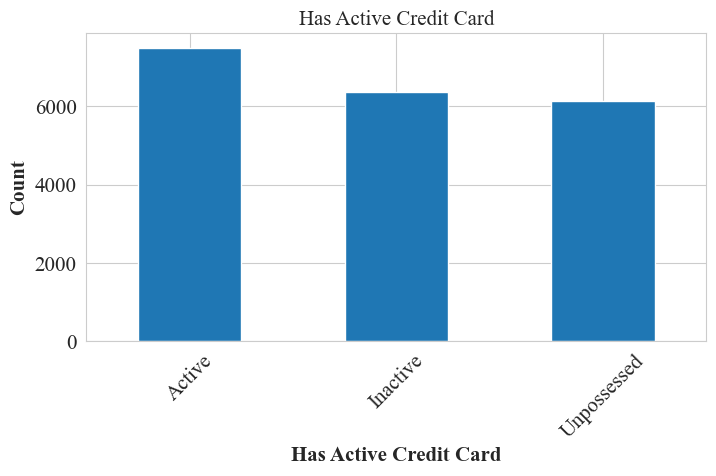


--------------------------------------------------------------------------------
Column : Property Location
--------------------------------------------------------------------------------
Unique Categories : 3
Property Location
Semi-Urban    6999
Rural         6768
Urban         6233
Name: count, dtype: int64


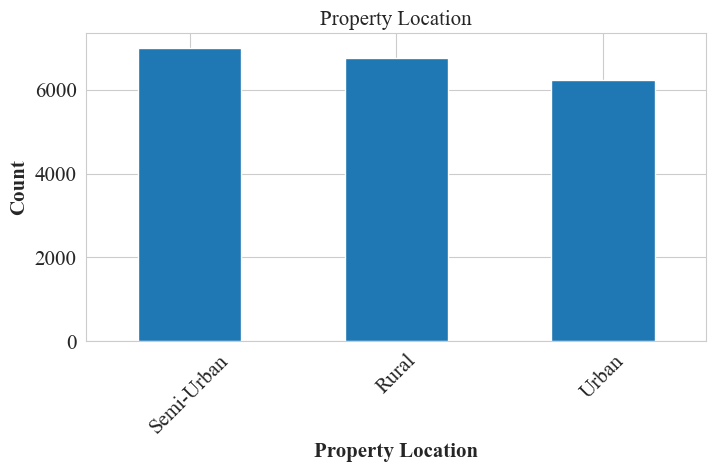



CORRELATION ANALYSIS


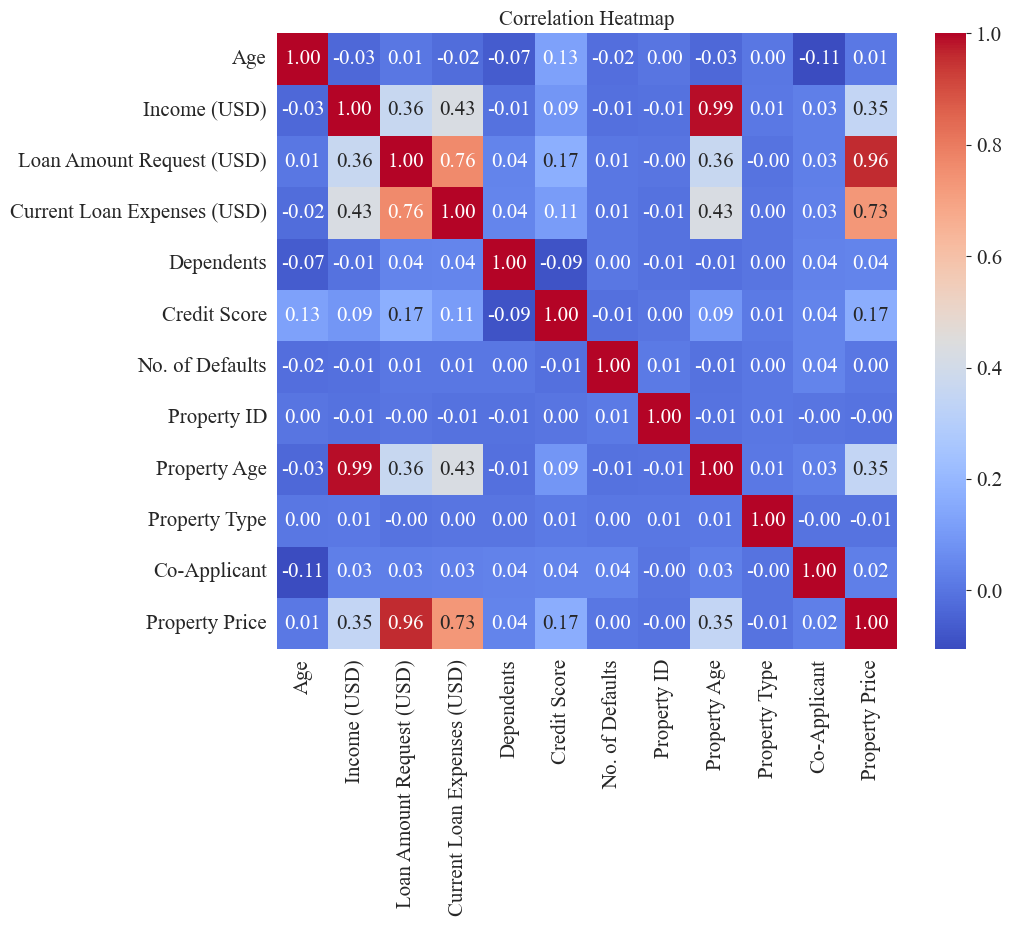


Highly Correlated Feature Pairs
Income (USD), Property Age = 0.9904812809133765
Loan Amount Request (USD), Property Price = 0.9609328266369354


TARGET ANALYSIS
No target provided as parameter!


FINAL EDA SUMMARY
Rows                     : 20000
Columns                  : 23
Numerical Columns        : 12
Categorical Columns      : 11
Duplicate Rows           : 0
Columns with Missing     : 0
Highly Correlated Pairs  : 2

EDA Completed Successfully.


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


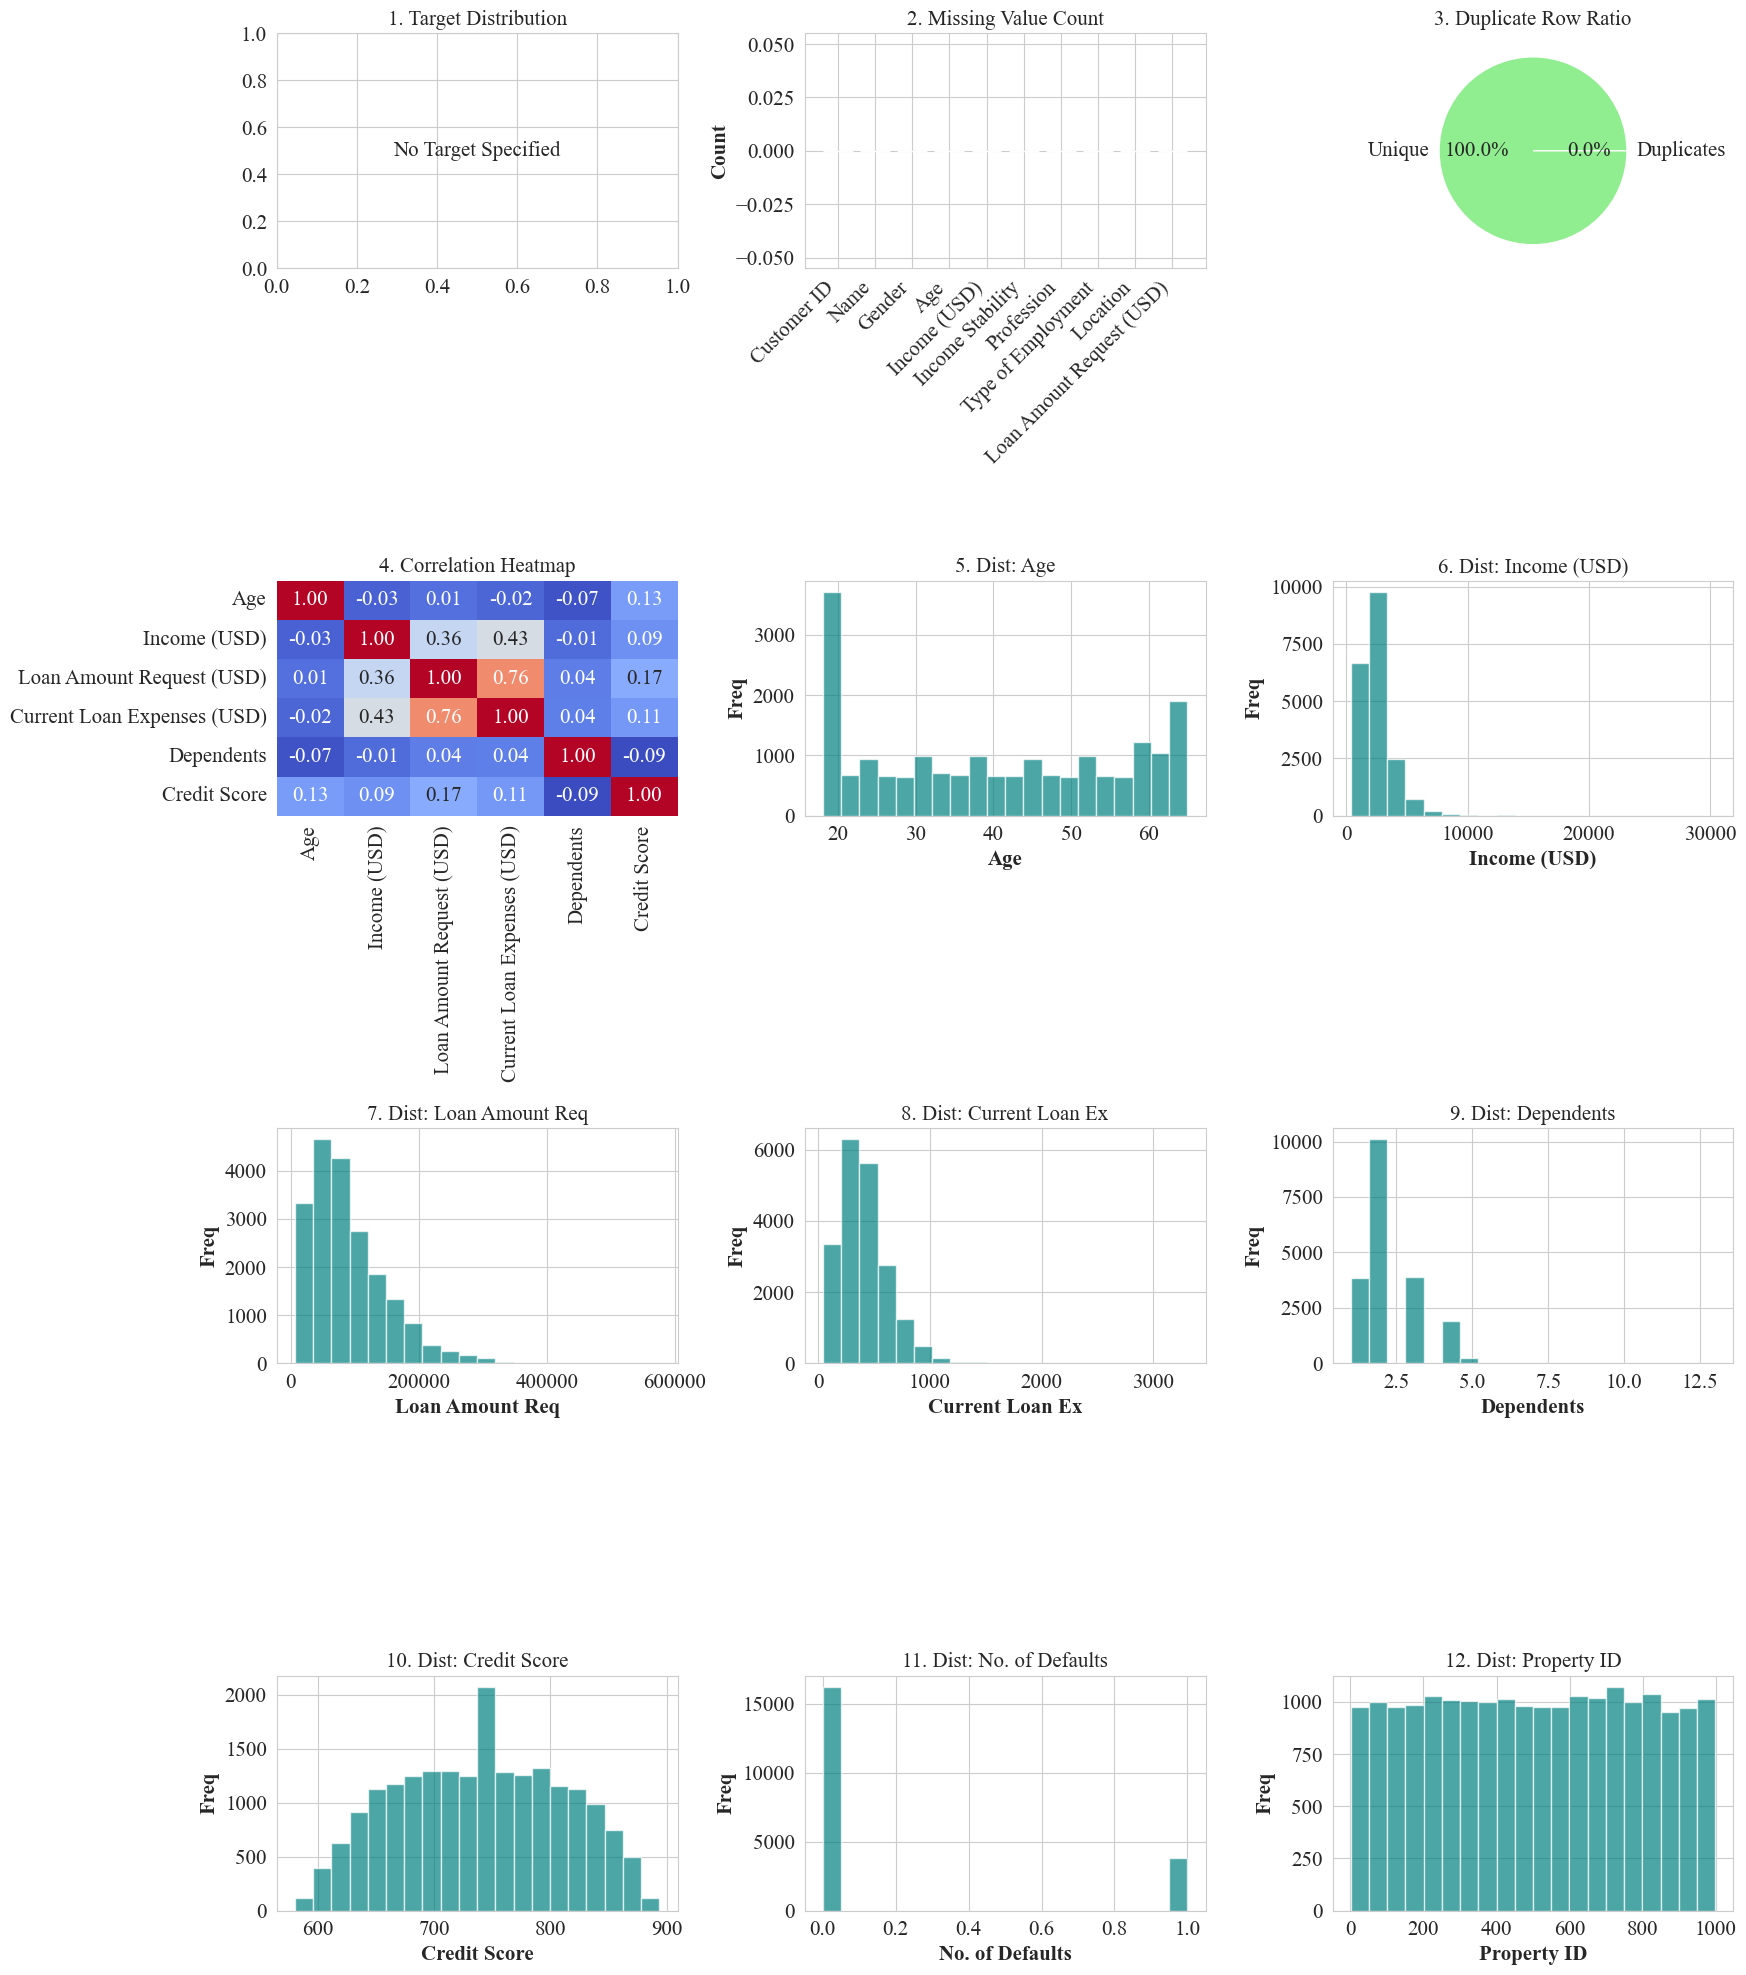

Consolidated EDA 12-subplot figure saved as 'exp3_eda_12_subplots.eps' at 600 DPI.


In [11]:
tabular_eda(test,"regression")

## 7. Data Preprocessing 

### Encoding Categorical Variables


In [12]:
# Income Stability is a simple Low/High column, so  mapped directly to 0/1
train['Income Stability'] = train['Income Stability'].replace({'Low': 0, 'High': 1})
test['Income Stability'] = test['Income Stability'].replace({'Low': 0, 'High': 1})

In [13]:
from sklearn.preprocessing import LabelEncoder

# These are the text (categorical) columns that need to be converted to numbers
categorical_cols = ['Customer ID', 'Name', 'Gender', 'Profession', 'Type of Employment',
                     'Location', 'Expense Type 1', 'Expense Type 2',
                     'Has Active Credit Card', 'Property Location']

le = LabelEncoder()
for col in categorical_cols:
    train[col] = le.fit_transform(train[col])

for col in categorical_cols:
    test[col] = le.fit_transform(test[col])

train.head()

,Customer ID,Name,Gender,Age,Income (USD),Income Stability,Profession,Type of Employment,Location,Loan Amount Request (USD),...,Credit Score,No. of Defaults,Has Active Credit Card,Property ID,Property Age,Property Type,Property Location,Co-Applicant,Property Price,Loan Sanction Amount (USD)
0,18080,9529,0,56,1933.050,0,7,14,1,72809.58,...,809.44,0,0,746,1933.05,4,0,1.0,119933.46,54607.18
1,16076,1304,1,32,4952.910,0,7,8,1,46837.47,...,780.40,0,2,608,4952.91,2,0,1.0,54791.00,37469.98
2,18552,24595,0,65,988.190,1,3,8,1,45593.04,...,833.15,0,2,546,988.19,2,2,0.0,72440.58,36474.43
3,11046,29860,0,65,2222.435,1,3,8,0,80057.92,...,832.70,1,2,890,2223.25,2,1,1.0,121441.51,56040.54
4,8991,190,0,31,2614.770,0,7,6,1,113858.89,...,745.55,1,0,715,2614.77,4,1,1.0,208567.91,74008.28


## 8. Feature vs Target Visualization


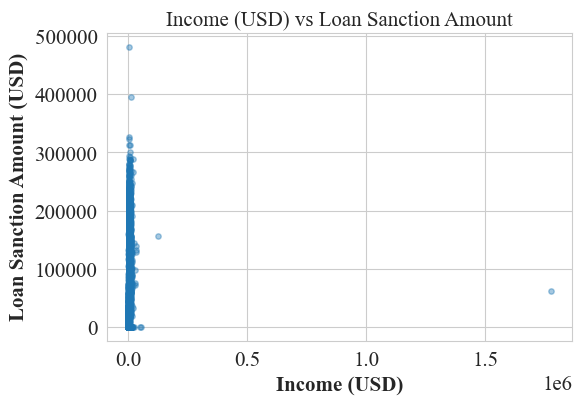

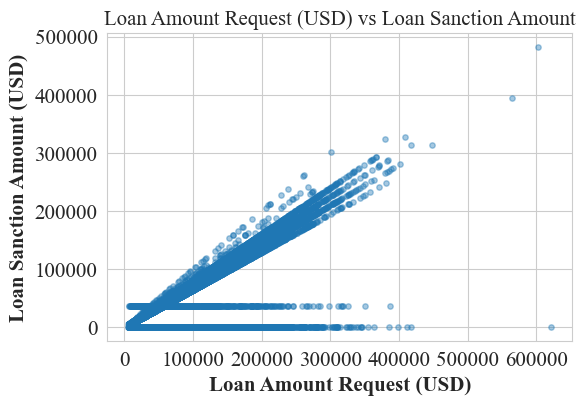

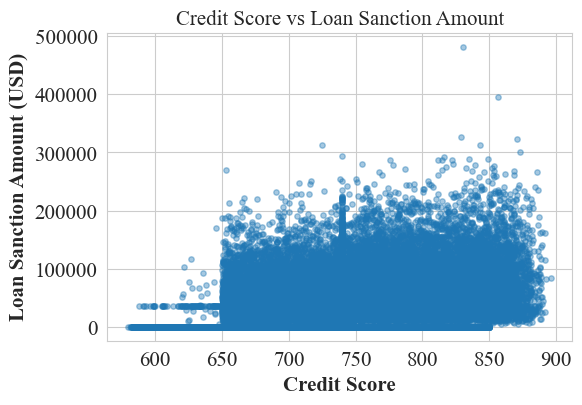

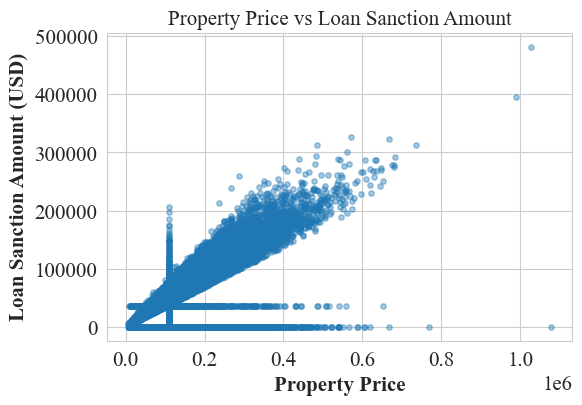

In [14]:
features_to_plot = ['Income (USD)', 'Loan Amount Request (USD)', 'Credit Score', 'Property Price']

for feature in features_to_plot:
    plt.figure(figsize=(6, 4))
    plt.scatter(train[feature], train['Loan Sanction Amount (USD)'], alpha=0.4, s=15)
    plt.xlabel(feature)
    plt.ylabel('Loan Sanction Amount (USD)')
    plt.title(f'{feature} vs Loan Sanction Amount')
    plt.show()

## 9. Feature and Target Split


In [15]:
X = train.drop(['Loan Sanction Amount (USD)'], axis=1)   # independent variables (features)
y = train['Loan Sanction Amount (USD)']                  # dependent variable (target)

feature_names = X.columns.tolist()   # keep the column names before scaling turns X into a plain array

X.head()

,Customer ID,Name,Gender,Age,Income (USD),Income Stability,Profession,Type of Employment,Location,Loan Amount Request (USD),...,Dependents,Credit Score,No. of Defaults,Has Active Credit Card,Property ID,Property Age,Property Type,Property Location,Co-Applicant,Property Price
0,18080,9529,0,56,1933.050,0,7,14,1,72809.58,...,3.0,809.44,0,0,746,1933.05,4,0,1.0,119933.46
1,16076,1304,1,32,4952.910,0,7,8,1,46837.47,...,1.0,780.40,0,2,608,4952.91,2,0,1.0,54791.00
2,18552,24595,0,65,988.190,1,3,8,1,45593.04,...,1.0,833.15,0,2,546,988.19,2,2,0.0,72440.58
3,11046,29860,0,65,2222.435,1,3,8,0,80057.92,...,2.0,832.70,1,2,890,2223.25,2,1,1.0,121441.51
4,8991,190,0,31,2614.770,0,7,6,1,113858.89,...,2.0,745.55,1,0,715,2614.77,4,1,1.0,208567.91


## 10. Feature Scaling
Regularized models (Ridge, Lasso, Elastic Net) add a penalty based on the size of each coefficient. If the features are on very different scales (for example, income in the thousands vs. dependents as a single digit), that penalty would unfairly punish features with naturally larger numbers. `StandardScaler` puts every feature on the same scale (mean 0, standard deviation 1) so the penalty is applied fairly across all features.

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(X)
X1 = scaler.transform(test)   # scale the real test/submission set using the same scaler (no separate fit)

## 11. Train-Test Split


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

Train shape: (22500, 23)  Test shape: (7500, 23)


In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Reusable regression performance metrics function (rules.md Section 4.4)
def display_regression_metrics(y_true, y_pred, name="Model"):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    
    print("=" * 60)
    print(f"Regression Metrics — {name}")
    print("=" * 60)
    print(f"MAE  : {mae:.3f}")
    print(f"MSE  : {mse:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R2   : {r2:.3f}")
    return {"Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

# Reusable regression model evaluation function (rules.md Section 4.2)
def train_and_evaluate_regression(model, X_train, y_train, X_test, y_test, name="Model"):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results = display_regression_metrics(y_test, y_pred, name)
    
    # Predicted vs Actual Plot
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].scatter(y_test, y_pred, alpha=0.4, color='navy', s=15)
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    axes[0].plot(lims, lims, color="red", linestyle="--")
    axes[0].set_xlabel("Actual Target")
    axes[0].set_ylabel("Predicted Target")
    axes[0].set_title(f"{name} — Predicted vs Actual")
    
    # Residual Plot
    residuals = y_test - y_pred
    axes[1].scatter(y_pred, residuals, alpha=0.4, color='darkgreen', s=15)
    axes[1].axhline(0, color="red", linestyle="--")
    axes[1].set_xlabel("Predicted Target")
    axes[1].set_ylabel("Residual")
    axes[1].set_title(f"{name} — Residual Plot")
    
    plt.tight_layout()
    plt.savefig(f'exp3_reg_{name.replace(" ", "_")}.eps', format='eps', dpi=600, bbox_inches='tight')
    plt.show()
    return results

# Alias for existing evaluate_regressor calls
def evaluate_regressor(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    results = display_regression_metrics(y_test, y_pred, name)
    return results


## 13. Baseline Linear Regression
Linear Regression is trained first, with no regularization at all, as the baseline that the regularized models will be compared against.

In [19]:
from sklearn.linear_model import LinearRegression

start = time.perf_counter()
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_train_time = time.perf_counter() - start

print("Training Time:", linear_train_time, "seconds")

linear_results = evaluate_regressor(linear_model, X_test, y_test, "Linear Regression")
linear_results["Training Time"] = linear_train_time
linear_results

Training Time: 0.03191829996649176 seconds
Regression Metrics — Linear Regression
MAE  : 18749.140
MSE  : 777840911.586
RMSE : 27889.799
R2   : 0.653


{'Model': 'Linear Regression',
 'MAE': 18749.140193227053,
 'MSE': 777840911.5864035,
 'RMSE': np.float64(27889.799418181614),
 'R2': 0.6532198424471078,
 'Training Time': 0.03191829996649176}

## 14. Ridge Regression

Ridge adds a penalty on the **size** of the coefficients (it shrinks them towards zero but does not usually make them exactly zero). The strength of this penalty is controlled by `alpha` — a bigger alpha means a stronger penalty, which shrinks the coefficients more.

`GridSearchCV` is used to try every value of alpha in `{0.01, 0.1, 1, 10, 100}` with 5-fold cross validation, and picks the alpha that gives the best R2 score.

In [20]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

ridge_param_grid = {'alpha': [0.01, 0.1, 1, 10, 100]}

ridge_grid = GridSearchCV(Ridge(), ridge_param_grid, cv=5, scoring='r2', n_jobs=-1)

start = time.perf_counter()
ridge_grid.fit(X_train, y_train)
ridge_train_time = time.perf_counter() - start

print("Best alpha:", ridge_grid.best_params_)
print("Best CV R2:", ridge_grid.best_score_)
print("Training Time:", ridge_train_time, "seconds")

best_ridge = ridge_grid.best_estimator_
ridge_results = evaluate_regressor(best_ridge, X_test, y_test, "Ridge Regression (Tuned)")
ridge_results["Training Time"] = ridge_train_time
ridge_results

Best alpha: {'alpha': 0.01}
Best CV R2: 0.6590010644100045
Training Time: 3.449272199999541 seconds
Regression Metrics — Ridge Regression (Tuned)
MAE  : 18749.066
MSE  : 777829008.393
RMSE : 27889.586
R2   : 0.653


{'Model': 'Ridge Regression (Tuned)',
 'MAE': 18749.066437675334,
 'MSE': 777829008.3931761,
 'RMSE': np.float64(27889.586020469647),
 'R2': 0.6532251491764933,
 'Training Time': 3.449272199999541}

## 15. Lasso Regression

Lasso also penalizes the size of the coefficients, but it can shrink some of them all the way to exactly zero. In effect, this means Lasso can perform **feature selection** on its own, by dropping features it decides are not useful.

The search space asked for is `alpha` in `{0.001, 0.01, 0.1, 1, 10}`.

In [21]:
from sklearn.linear_model import Lasso

lasso_param_grid = {'alpha': [0.001, 0.01, 0.1, 1, 10]}

lasso_grid = GridSearchCV(Lasso(max_iter=10000), lasso_param_grid, cv=5, scoring='r2', n_jobs=-1)

start = time.perf_counter()
lasso_grid.fit(X_train, y_train)
lasso_train_time = time.perf_counter() - start

print("Best alpha:", lasso_grid.best_params_)
print("Best CV R2:", lasso_grid.best_score_)
print("Training Time:", lasso_train_time, "seconds")

best_lasso = lasso_grid.best_estimator_
lasso_results = evaluate_regressor(best_lasso, X_test, y_test, "Lasso Regression (Tuned)")
lasso_results["Training Time"] = lasso_train_time
lasso_results

Best alpha: {'alpha': 0.001}
Best CV R2: 0.6590011290844211
Training Time: 19.049890599912032 seconds
Regression Metrics — Lasso Regression (Tuned)
MAE  : 18749.135
MSE  : 777840236.830
RMSE : 27889.787
R2   : 0.653


{'Model': 'Lasso Regression (Tuned)',
 'MAE': 18749.135338393902,
 'MSE': 777840236.8298447,
 'RMSE': np.float64(27889.787321344793),
 'R2': 0.6532201432697854,
 'Training Time': 19.049890599912032}

In [22]:
# Features dropped by Lasso

zero_coefs = np.sum(best_lasso.coef_ == 0)
print(f"Lasso set {zero_coefs} out of {len(best_lasso.coef_)} feature coefficients to exactly zero.")

Lasso set 0 out of 23 feature coefficients to exactly zero.


## 16. Elastic Net Regression

Elastic Net mixes Ridge and Lasso together. Besides `alpha` (overall penalty strength), it has a second setting, `l1_ratio`, which controls the mix: `l1_ratio = 1` behaves like pure Lasso, `l1_ratio = 0` behaves like pure Ridge, and anything in between is a blend of both.

The search space asked for is `alpha` in `{0.01, 0.1, 1, 10}` and `l1_ratio` in `{0.2, 0.5, 0.8}`.

In [23]:
from sklearn.linear_model import ElasticNet

elastic_param_grid = {
    'alpha': [0.01, 0.1, 1, 10],
    'l1_ratio': [0.2, 0.5, 0.8]
}

elastic_grid = GridSearchCV(ElasticNet(max_iter=10000), elastic_param_grid, cv=5, scoring='r2', n_jobs=-1)

start = time.perf_counter()
elastic_grid.fit(X_train, y_train)
elastic_train_time = time.perf_counter() - start

print("Best Parameters:", elastic_grid.best_params_)
print("Best CV R2:", elastic_grid.best_score_)
print("Training Time:", elastic_train_time, "seconds")

best_elastic = elastic_grid.best_estimator_
elastic_results = evaluate_regressor(best_elastic, X_test, y_test, "Elastic Net Regression (Tuned)")
elastic_results["Training Time"] = elastic_train_time
elastic_results

Best Parameters: {'alpha': 0.01, 'l1_ratio': 0.8}
Best CV R2: 0.658916475129401
Training Time: 6.0140299999620765 seconds
Regression Metrics — Elastic Net Regression (Tuned)
MAE  : 18744.990
MSE  : 772890046.529
RMSE : 27800.900
R2   : 0.655


{'Model': 'Elastic Net Regression (Tuned)',
 'MAE': 18744.990435109026,
 'MSE': 772890046.5287187,
 'RMSE': np.float64(27800.900102851323),
 'R2': 0.6554270569805083,
 'Training Time': 6.0140299999620765}

## 17. Hyperparameter Tuning Summary

In [24]:
tuning_summary = pd.DataFrame({
    "Model": ["Ridge Regression", "Lasso Regression", "Elastic Net Regression"],
    "Search Method": ["Grid Search", "Grid Search", "Grid Search"],
    "Best Parameters": [ridge_grid.best_params_, lasso_grid.best_params_, elastic_grid.best_params_],
    "Best CV R2": [ridge_grid.best_score_, lasso_grid.best_score_, elastic_grid.best_score_],
})
tuning_summary

,Model,Search Method,Best Parameters,Best CV R2
0,Ridge Regression,Grid Search,{'alpha': 0.01},0.659001
1,Lasso Regression,Grid Search,{'alpha': 0.001},0.659001
2,Elastic Net Regression,Grid Search,"{'alpha': 0.01, 'l1_ratio': 0.8}",0.658916


## 18. Cross-Validation Performance (K = 5)


In [25]:
from sklearn.model_selection import cross_val_score

def cv_metrics(model, X, y):
    mae  = -cross_val_score(model, X, y, cv=5, scoring='neg_mean_absolute_error').mean()
    mse  = -cross_val_score(model, X, y, cv=5, scoring='neg_mean_squared_error').mean()
    rmse = np.sqrt(mse)
    r2   =  cross_val_score(model, X, y, cv=5, scoring='r2').mean()
    return mae, mse, rmse, r2

models_for_cv = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(**ridge_grid.best_params_),
    "Lasso Regression": Lasso(max_iter=10000, **lasso_grid.best_params_),
    "Elastic Net Regression": ElasticNet(max_iter=10000, **elastic_grid.best_params_),
}

cv_rows = []
for name, model in models_for_cv.items():
    mae, mse, rmse, r2 = cv_metrics(model, X_train, y_train)
    cv_rows.append({"Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2})

cv_performance = pd.DataFrame(cv_rows)
cv_performance

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,19098.549284,7.798015e+08,27924.926276,0.659001
1,Ridge Regression,19098.521693,7.798017e+08,27924.929089,0.659001
2,Lasso Regression,19098.547845,7.798015e+08,27924.926380,0.659001
3,Elastic Net Regression,19107.712457,7.799896e+08,27928.294271,0.658916


## 19. Test Set Performance


In [26]:
test_performance = pd.DataFrame([linear_results, ridge_results, lasso_results, elastic_results])
test_performance = test_performance[["Model", "MAE", "MSE", "RMSE", "R2", "Training Time"]]
test_performance

,Model,MAE,MSE,RMSE,R2,Training Time
0,Linear Regression,18749.140193,7.778409e+08,27889.799418,0.653220,0.031918
1,Ridge Regression (Tuned),18749.066438,7.778290e+08,27889.586020,0.653225,3.449272
2,Lasso Regression (Tuned),18749.135338,7.778402e+08,27889.787321,0.653220,19.049891
3,Elastic Net Regression (Tuned),18744.990435,7.728900e+08,27800.900103,0.655427,6.014030


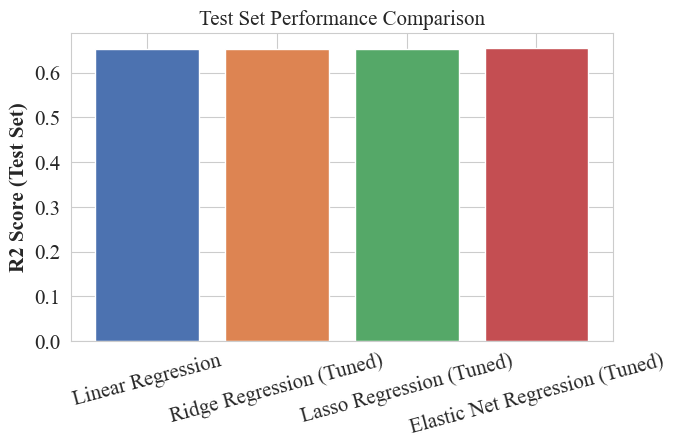

In [27]:
# Test Set Performance Comparison (bar chart)

plt.figure(figsize=(7, 4))
plt.bar(test_performance["Model"], test_performance["R2"], color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])
plt.ylabel("R2 Score (Test Set)")
plt.title("Test Set Performance Comparison")
plt.xticks(rotation=15)
plt.show()

In [28]:
# Effect of Regularization on Coefficients

coefficient_comparison = pd.DataFrame({
    "Feature": feature_names,
    "Linear": linear_model.coef_,
    "Ridge": best_ridge.coef_,
    "Lasso": best_lasso.coef_,
    "Elastic Net": best_elastic.coef_,
})
coefficient_comparison

,Feature,Linear,Ridge,Lasso,Elastic Net
0,Customer ID,-6937.839820,-6937.861312,-6937.840489,-6931.986568
1,Name,9.497493,9.480883,9.495465,3.696447
2,Gender,-130.731620,-130.731922,-130.730600,-130.222684
3,Age,-343.565334,-343.541345,-343.562024,-334.625417
4,Income (USD),34643.720277,34486.164209,34633.910755,360.629372
5,Income Stability,2013.740583,2013.737284,2013.738679,2008.332503
6,Profession,-81.310743,-81.317996,-81.310515,-82.955542
7,Type of Employment,-58.854627,-58.849855,-58.853347,-60.536088
8,Location,52.461702,52.493414,52.462804,59.077692
9,Loan Amount Request (USD),32953.656840,32953.505757,32953.632839,32097.257916


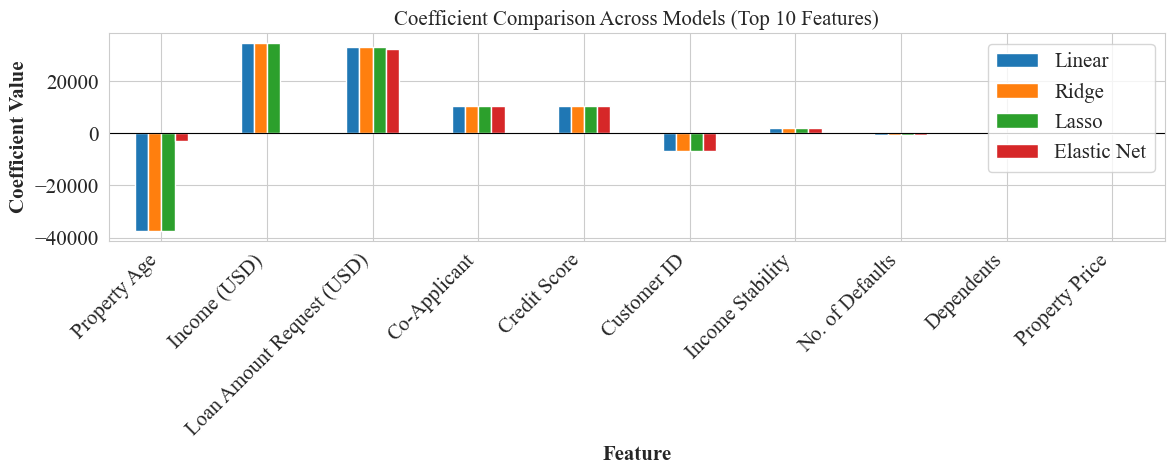

In [29]:
# Coefficient Comparison Bar Plot

top_features = coefficient_comparison.reindex(
    coefficient_comparison["Linear"].abs().sort_values(ascending=False).index
).head(10)

top_features.set_index("Feature")[["Linear", "Ridge", "Lasso", "Elastic Net"]].plot(
    kind="bar", figsize=(12, 5)
)
plt.ylabel("Coefficient Value")
plt.title("Coefficient Comparison Across Models (Top 10 Features)")
plt.xticks(rotation=45, ha="right")
plt.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

## 21. Training Error vs Validation Error (Bias–Variance Trade-off)

This plot shows what happens as the Ridge penalty (`alpha`) gets stronger. `validation_curve` trains the model at each alpha using cross validation and records both the training error and the validation error:
- At very **low alpha** (almost no regularization), the model is closer to plain Linear Regression — training error is low, but it may not generalize as well (higher variance).
- At very **high alpha** (very strong regularization), the model is forced to be too simple — both training and validation error go up, since the model can no longer fit the real pattern in the data (higher bias, underfitting).
- Somewhere in between is usually the best trade-off, where validation error is at its lowest.

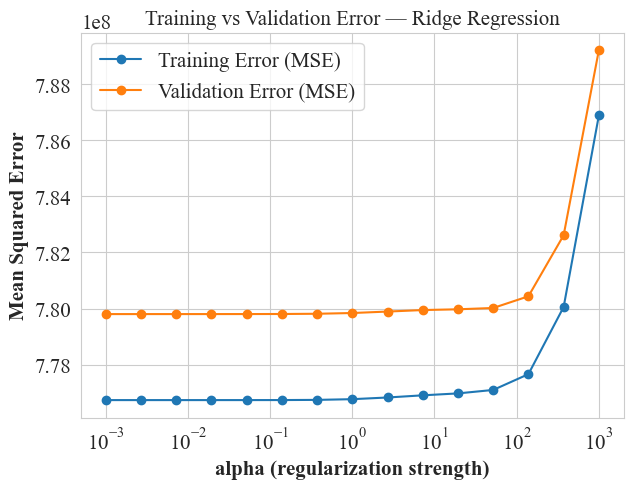

In [30]:
from sklearn.model_selection import validation_curve

alpha_range = np.logspace(-3, 3, 15)

train_scores, val_scores = validation_curve(
    Ridge(), X_train, y_train,
    param_name="alpha", param_range=alpha_range,
    cv=5, scoring="neg_mean_squared_error", n_jobs=-1
)

train_error = -train_scores.mean(axis=1)
val_error = -val_scores.mean(axis=1)

plt.figure(figsize=(7, 5))
plt.plot(alpha_range, train_error, marker='o', label="Training Error (MSE)")
plt.plot(alpha_range, val_error, marker='o', label="Validation Error (MSE)")
plt.xscale("log")
plt.xlabel("alpha (regularization strength)")
plt.ylabel("Mean Squared Error")
plt.title("Training vs Validation Error — Ridge Regression")
plt.legend()
plt.show()

## 22. Overfitting and Underfitting Analysis

- Plain **Linear Regression** has no penalty at all, so it fits the training data as closely as it can. If the training error is much lower than the test error, that is a sign of overfitting — the model has partly memorized the training data instead of learning a pattern that generalizes.
- **Ridge, Lasso and Elastic Net** all add a penalty that discourages large coefficients, which keeps the model simpler and usually reduces the gap between training and test error, at the cost of slightly higher training error.
- The training vs validation error plot above shows this trade-off directly for Ridge: error is high on the underfitting side (alpha too large, model too  simple) and can also creep up on the overfitting side (alpha too small, model too close to plain Linear Regression), with the best alpha sitting somewhere in between.
- After tuning, the gap between the cross-validation R2 and the test R2 should be small for all three regularized models — a big gap between the two would be a warning sign that the model is still overfitting even after regularization.

## 23. Bias–Variance Analysis

- **Linear Regression** has low bias (it does not force any particular shape onto the coefficients) but can have higher variance, since it is free to fit noise in the training data as well as the real pattern.
- **Ridge Regression** trades a little bit of bias for a reduction in variance — by shrinking all coefficients together, it becomes less sensitive to small changes in the training data, which usually helps it generalize better than plain Linear Regression.
- **Lasso Regression** goes a step further and can set some coefficients to exactly zero, effectively removing features it decides are not useful. This adds some bias if a genuinely useful feature gets zeroed out, but it can also reduce variance a lot when many features are irrelevant or repeat the same information.
- **Elastic Net** sits between Ridge and Lasso, controlled by `l1_ratio` — it keeps some of Ridge's smooth shrinking behaviour while still allowing some coefficients to be pushed to zero like Lasso, which is useful when features are correlated with each other (a situation where Lasso alone can behave a little unpredictably).

## 24. Conclusion

Linear Regression, Ridge, Lasso and Elastic Net were all trained on the loan amount dataset, with Ridge, Lasso and Elastic Net tuned using GridSearchCV over the alpha (and `l1_ratio`) values given in the lab manual. The tuning summary, cross-validation table, test set table and coefficient comparison above show how each model performs and how regularization changes the coefficients. The training-vs-validation error plot shows the bias-variance trade-off directly, and the discussion sections above explain why the regularized models are expected to generalize better than plain Linear Regression on this dataset.